# Unattended four-participant demo

One chronic participant runs through the single-case workflow; the remaining chronic participant and two acute participants run in the batch. Completed single-case results are reused in cohort summaries. All available optional analyses are selected when `optional=all`.

**Human QC is skipped for this demonstration. No passing ratings are invented.** Static QC images, tables and four participant reports are saved. Repair/edit controls are displayed but no automatic edits are made. The source notebook is unchanged. The runner autosaves throughout execution.

In [1]:
import os
os.environ['CALMAR_KB_UPDATE'] = 'off'
_CALMAR_CONFIG_OVERRIDES = {'SUBJECT_FILTER': ['sub-M2001', 'sub-M2004'], 'SESSION_FILTER': ['ses-1076', 'ses-524'], 'MAX_SUBJECTS': 2, 'RANDOM_SAMPLE': False, 'RUN_TEST': True, 'TEST_SUBJECT_IDX': 0, 'ANALYSE_DWI': True, 'ANALYSE_TRACT_DWI': True, 'ANALYSE_BRAIN_HEALTH': True, 'REPORTS_SUBDIR': 'reports/unattended-demo', 'OVERWRITE': False, 'BCB_OVERWRITE': False, 'DEEPDISCO_OVERWRITE': False, 'DMRI_OVERWRITE': False, 'BRAIN_HEALTH_OVERWRITE': False, 'DMRI_REUSE_PRIOR': True, 'BRAIN_HEALTH_REUSE_PRIOR': True, 'ADDITIONAL_COHORTS': [{'NAME': 'ISLES 2022 acute', 'DATASET_SOURCE': 'isles2022', 'LOCAL_DATASET': 'data/ISLES-2022', 'MODALITY': 'dwi', 'STROKE_PHASE': 'acute', 'SEGMENTATION_METHODS': ['openads'], 'SUBJECT_FILTER': ['sub-strokecase0001', 'sub-strokecase0002'], 'SESSION_FILTER': ['ses-0001'], 'MAX_SUBJECTS': 2}]}
print('Demo settings:', _CALMAR_CONFIG_OVERRIDES)

DEMO_COMPLETION_TOKEN = 'dd3a31f64dcf45679628d328465ef25a'
DEMO_COMPLETION_PROOF = '/home/jovyan/neurodesktop-storage/calmar/analyses/unattended-demo/run/attempts/20261113T070019Z-34/completion-proof.json'


Demo settings: {'SUBJECT_FILTER': ['sub-M2001', 'sub-M2004'], 'SESSION_FILTER': ['ses-1076', 'ses-524'], 'MAX_SUBJECTS': 2, 'RANDOM_SAMPLE': False, 'RUN_TEST': True, 'TEST_SUBJECT_IDX': 0, 'ANALYSE_DWI': True, 'ANALYSE_TRACT_DWI': True, 'ANALYSE_BRAIN_HEALTH': True, 'REPORTS_SUBDIR': 'reports/unattended-demo', 'OVERWRITE': False, 'BCB_OVERWRITE': False, 'DEEPDISCO_OVERWRITE': False, 'DMRI_OVERWRITE': False, 'BRAIN_HEALTH_OVERWRITE': False, 'DMRI_REUSE_PRIOR': True, 'BRAIN_HEALTH_REUSE_PRIOR': True, 'ADDITIONAL_COHORTS': [{'NAME': 'ISLES 2022 acute', 'DATASET_SOURCE': 'isles2022', 'LOCAL_DATASET': 'data/ISLES-2022', 'MODALITY': 'dwi', 'STROKE_PHASE': 'acute', 'SEGMENTATION_METHODS': ['openads'], 'SUBJECT_FILTER': ['sub-strokecase0001', 'sub-strokecase0002'], 'SESSION_FILTER': ['ses-0001'], 'MAX_SUBJECTS': 2}]}


# Co-designed, Automated Lesion Mapping and Reporting | CALMaR

A reusable workflow for stroke lesion imaging, from raw MRI to a participant report:

1. Pull or point at a structural MRI dataset (BIDS or a flat folder of T1w images).
2. Segment the stroke lesion (LINDA and/or SynthStroke, after HD-BET brain extraction) and quality-check every mask.
3. Map each lesion onto brain atlases and build a group lesion-frequency map.
4. Estimate the disconnectome (BCBToolkit, DeepDisco) and decode the lesion against Neurosynth.
5. Produce a research report from an aphasia knowledge base: predicted impairments, outcomes and therapies.


**Author:** Michèle Masson-Trottier

**Date:** 21 October 2026

**License:** 
<div style="margin-top: 10px;">
    <a href="https://opensource.org/licenses/MIT" target="_blank" style="color: #0066cc;">
        <i class="fas fa-balance-scale"></i> MIT License
    </a>
</div>


**Note:** This notebook uses neuroimaging tools from Neurocontainers; those tools retain their original licenses. Please see <a href="https://neurodesk.org/overview/how-to-cite-us/" target="_blank" style="color: #0066cc;">Neurodesk citation guidelines</a> for details.

<details style="border-left: 4px solid #f0a500; background-color: rgba(240, 165, 0, 0.08); border-radius: 4px; padding: 0.75em 1em; margin: 1em 0;">
  <summary style="cursor: pointer; display: flex; justify-content: space-between; align-items: center; list-style: none; font-size: 1.1em;">
    <strong>✨ Use of AI</strong>
    <span style="font-size: 1.1em;">▽</span>
  </summary>
  <p style="font-size: 1.1em;">This notebook and the CALMaR code were developed with assistance from <em>Claude Code (Anthropic)</em> across many iterations and then revised by the author. The author reviewed the final content and takes responsibility for it.</p>
</details>


### Citations and resources

#### Tools included in this workflow
Click a group to see its citations. Versions are the software pins used by the Slurm scripts in `src/`; software entries are Neurodesk modules unless explicitly labelled as Python packages.

<details style="border-left: 4px solid #0066cc; background-color: rgba(0, 102, 204, 0.06); border-radius: 4px; padding: 0.6em 1em; margin: 0.6em 0;">
  <summary style="cursor: pointer; display: flex; justify-content: space-between; align-items: center; list-style: none; font-size: 1.05em;">
    <strong>Brain extraction: HD-BET, SynthStrip</strong>
    <span style="font-size: 1.05em;">▽</span>
  </summary>

__HD-BET__ (`hdbet/1.0.0`):
- Isensee F, Schell M, Pflueger I, et al. (2019). Automated brain extraction of multisequence MRI using artificial neural networks. *Human Brain Mapping*, 40(17), 4952–4964. [https://doi.org/10.1002/hbm.24750](https://doi.org/10.1002/hbm.24750)

__SynthStrip__ (`synthstrip/7.4.1`; skull-strip repair in the T1 route):
- Hoopes A, Mora JS, Dalca AV, Fischl B, Hoffmann M (2022). SynthStrip: skull-stripping for any brain image. *NeuroImage*, 260, 119474. [https://doi.org/10.1016/j.neuroimage.2022.119474](https://doi.org/10.1016/j.neuroimage.2022.119474)

</details>

<details style="border-left: 4px solid #0066cc; background-color: rgba(0, 102, 204, 0.06); border-radius: 4px; padding: 0.6em 1em; margin: 0.6em 0;">
  <summary style="cursor: pointer; display: flex; justify-content: space-between; align-items: center; list-style: none; font-size: 1.05em;">
    <strong>Chronic T1 lesion segmentation: LINDA, SynthStroke</strong>
    <span style="font-size: 1.05em;">▽</span>
  </summary>

__LINDA__ (Lesion Identification with Neighborhood Data Analysis, `linda/0.5.1`):
- Pustina D, Coslett HB, Turkeltaub PE, Tustison N, Schwartz MF, Avants B (2016). Automated segmentation of chronic stroke lesions using LINDA: Lesion Identification with Neighborhood Data Analysis. *Human Brain Mapping*, 37(4), 1405–1421. [https://doi.org/10.1002/hbm.23240](https://doi.org/10.1002/hbm.23240)

__SynthStroke__ (`synthstroke/0.0.0`, synth-plus weights):
- Chalcroft L, Pappas I, Price CJ, Ashburner J (2025). Synthetic data for robust stroke segmentation. *Machine Learning for Biomedical Imaging*. [https://doi.org/10.59275/j.melba.2025-f3g6](https://doi.org/10.59275/j.melba.2025-f3g6) · Code and weights: [github.com/liamchalcroft/SynthStroke](https://github.com/liamchalcroft/SynthStroke)

</details>

<details style="border-left: 4px solid #0066cc; background-color: rgba(0, 102, 204, 0.06); border-radius: 4px; padding: 0.6em 1em; margin: 0.6em 0;">
  <summary style="cursor: pointer; display: flex; justify-content: space-between; align-items: center; list-style: none; font-size: 1.05em;">
    <strong>Acute DWI lesion segmentation: OpenADS</strong>
    <span style="font-size: 1.05em;">▽</span>
  </summary>

__OpenADS__ (`openadscpu/1.0.0`; DWI/ADC preprocessing, lesion segmentation and registration):
- Liu CF, Hsu J, Xu X, Ramachandran S, Wang V, Miller MI, Hillis AE, Faria AV (2021). Deep learning-based detection and segmentation of diffusion abnormalities in acute ischemic stroke. *Communications Medicine*, 1, 61. [https://doi.org/10.1038/s43856-021-00062-8](https://doi.org/10.1038/s43856-021-00062-8)
- Software and documentation: [github.com/farialab/OpenADS](https://github.com/farialab/OpenADS)

</details>

<details style="border-left: 4px solid #0066cc; background-color: rgba(0, 102, 204, 0.06); border-radius: 4px; padding: 0.6em 1em; margin: 0.6em 0;">
  <summary style="cursor: pointer; display: flex; justify-content: space-between; align-items: center; list-style: none; font-size: 1.05em;">
    <strong>Diffusion MRI: QSIPrep, QSIRecon, DIPY</strong>
    <span style="font-size: 1.05em;">▽</span>
  </summary>

__QSIPrep and QSIRecon__ (`qsiprep/26.1.1`, `qsirecon/26.0.1`; lesion-aware preprocessing and participant-specific reconstruction/tractometry):
- Cieslak M, Cook PA, He X, et al. (2021). QSIPrep: an integrative platform for preprocessing and reconstructing diffusion MRI data. *Nature Methods*, 18, 775–778. [https://doi.org/10.1038/s41592-021-01185-5](https://doi.org/10.1038/s41592-021-01185-5)
- The generated QSIPrep/QSIRecon `CITATION` boilerplate records the component methods actually used (including TORTOISE DIFFPREP and, for the default reconstruction, MRtrix3/SS3T-CSD and DSI Studio AutoTrack); cite that run-specific boilerplate in addition to the platform paper. Documentation: [qsirecon.readthedocs.io](https://qsirecon.readthedocs.io/)
- Tournier JD, Smith R, Raffelt D, et al. (2019). MRtrix3: A fast, flexible and open software framework for medical image processing and visualisation. *NeuroImage*, 202, 116137. [https://doi.org/10.1016/j.neuroimage.2019.116137](https://doi.org/10.1016/j.neuroimage.2019.116137)
- Yeh FC (2020). Shape analysis of the human association pathways. *NeuroImage*, 223, 117329. [https://doi.org/10.1016/j.neuroimage.2020.117329](https://doi.org/10.1016/j.neuroimage.2020.117329)

__DIPY__ (Python package `dipy==1.12.1`, version-checked by the reconstruction Slurm script; weighted-least-squares tensor fit producing FA, MD, AD and RD):
- Garyfallidis E, Brett M, Amirbekian B, et al. (2014). Dipy, a library for the analysis of diffusion MRI data. *Frontiers in Neuroinformatics*, 8, 8. [https://doi.org/10.3389/fninf.2014.00008](https://doi.org/10.3389/fninf.2014.00008)

</details>

<details style="border-left: 4px solid #0066cc; background-color: rgba(0, 102, 204, 0.06); border-radius: 4px; padding: 0.6em 1em; margin: 0.6em 0;">
  <summary style="cursor: pointer; display: flex; justify-content: space-between; align-items: center; list-style: none; font-size: 1.05em;">
    <strong>Brain health: SynthSeg, DeepWMH</strong>
    <span style="font-size: 1.05em;">▽</span>
  </summary>

__SynthSeg__ (`synthseg/8.2.1`; robust parcellation):
- Billot B, Greve DN, Puonti O, et al. (2023). SynthSeg: Segmentation of brain MRI scans of any contrast and resolution without retraining. *Medical Image Analysis*, 83, 102789. [https://doi.org/10.1016/j.media.2022.102789](https://doi.org/10.1016/j.media.2022.102789)
- Billot B, Magdamo C, Arnold SE, Das S, Iglesias JE (2023). Robust machine learning segmentation for large-scale analysis of heterogeneous clinical brain MRI datasets. *PNAS*, 120(9), e2216399120. [https://doi.org/10.1073/pnas.2216399120](https://doi.org/10.1073/pnas.2216399120)

__DeepWMH__ (`deepwmh/1.0.1`; FLAIR white-matter-hyperintensity segmentation):
- Liu C, Zhuo Z, Qu L, et al. (2024). DeepWMH: A deep learning tool for accurate white matter hyperintensity segmentation without requiring manual annotations for training. *Science Bulletin*, 69, 872–875. [https://doi.org/10.1016/j.scib.2024.01.034](https://doi.org/10.1016/j.scib.2024.01.034)

</details>

<details style="border-left: 4px solid #0066cc; background-color: rgba(0, 102, 204, 0.06); border-radius: 4px; padding: 0.6em 1em; margin: 0.6em 0;">
  <summary style="cursor: pointer; display: flex; justify-content: space-between; align-items: center; list-style: none; font-size: 1.05em;">
    <strong>Registration and template space: ANTs, MNI152</strong>
    <span style="font-size: 1.05em;">▽</span>
  </summary>

__ANTs__ (`ants/2.6.5`; template registration when LINDA is not run, ch2 → MNI152 once, and application of OpenADS registration transforms):
- Avants BB, Epstein CL, Grossman M, Gee JC (2008). Symmetric diffeomorphic image registration with cross-correlation: evaluating automated labeling of elderly and neurodegenerative brain. *Medical Image Analysis*, 12(1), 26–41. [https://doi.org/10.1016/j.media.2007.06.004](https://doi.org/10.1016/j.media.2007.06.004)
- Tustison NJ, Cook PA, Holbrook AJ, et al. (2021). The ANTsX ecosystem for quantitative biological and medical imaging. *Scientific Reports*, 11, 9068. [https://doi.org/10.1038/s41598-021-87564-6](https://doi.org/10.1038/s41598-021-87564-6)

__FSL MNI152 template__ (MNI152NLin6Asym, 1 mm, from `fsl/6.0.7.22`): the space of every template-space output.

</details>

<details style="border-left: 4px solid #0066cc; background-color: rgba(0, 102, 204, 0.06); border-radius: 4px; padding: 0.6em 1em; margin: 0.6em 0;">
  <summary style="cursor: pointer; display: flex; justify-content: space-between; align-items: center; list-style: none; font-size: 1.05em;">
    <strong>Disconnectome: BCBToolkit, DeepDisco</strong>
    <span style="font-size: 1.05em;">▽</span>
  </summary>

__BCBToolkit__ (Brain Connectivity Behaviour toolkit, `bcbtoolkit/0.0.0`):
- Foulon C, Cerliani L, Kinkingnéhun S, Levy R, Rosso C, Urbanski M, Volle E, Thiebaut de Schotten M (2018). Advanced lesion symptom mapping analyses and implementation as BCBtoolkit. *GigaScience*, 7(3), giy004. [https://doi.org/10.1093/gigascience/giy004](https://doi.org/10.1093/gigascience/giy004)

__DeepDisco__ (`deepdisco/20251008`):
- Matsulevits A, Tourdias T, Thiebaut de Schotten M (2026). Rapid estimation of structural brain disconnection from binary lesion masks using DeepDisco. *Scientific Reports*. [https://doi.org/10.1038/s41598-026-73385-y](https://doi.org/10.1038/s41598-026-73385-y)

</details>

<details style="border-left: 4px solid #0066cc; background-color: rgba(0, 102, 204, 0.06); border-radius: 4px; padding: 0.6em 1em; margin: 0.6em 0;">
  <summary style="cursor: pointer; display: flex; justify-content: space-between; align-items: center; list-style: none; font-size: 1.05em;">
    <strong>Atlases: Harvard–Oxford, AAL, Destrieux, Schaefer 400, JHU</strong>
    <span style="font-size: 1.05em;">▽</span>
  </summary>

__Harvard–Oxford cortical and subcortical atlases__:
- Makris N, et al. (2006). *Cerebral Cortex*, 16(9), 1231–1242. [https://doi.org/10.1093/cercor/bhj100](https://doi.org/10.1093/cercor/bhj100)
- Desikan RS, et al. (2006). *NeuroImage*, 31(3), 968–980. [https://doi.org/10.1016/j.neuroimage.2006.01.021](https://doi.org/10.1016/j.neuroimage.2006.01.021)

__AAL__ (Automated Anatomical Labeling):
- Tzourio-Mazoyer N, Landeau B, Papathanassiou D, Crivello F, Etard O, Delcroix N, Mazoyer B, Joliot M (2002). Automated anatomical labeling of activations in SPM using a macroscopic anatomical parcellation of the MNI MRI single-subject brain. *NeuroImage*, 15(1), 273–289. [https://doi.org/10.1006/nimg.2001.0978](https://doi.org/10.1006/nimg.2001.0978)

__Destrieux atlas__:
- Destrieux C, Fischl B, Dale A, Halgren E (2010). Automatic parcellation of human cortical gyri and sulci using standard anatomical nomenclature. *NeuroImage*, 53(1), 1–15. [https://doi.org/10.1016/j.neuroimage.2010.06.010](https://doi.org/10.1016/j.neuroimage.2010.06.010)

__Schaefer 400-parcel atlas__:
- Schaefer A, Kong R, Gordon EM, Laumann TO, Zuo XN, Holmes AJ, Eickhoff SB, Yeo BTT (2018). Local-global parcellation of the human cerebral cortex from intrinsic functional connectivity MRI. *Cerebral Cortex*, 28(9), 3095–3114. [https://doi.org/10.1093/cercor/bhx179](https://doi.org/10.1093/cercor/bhx179)

__JHU white-matter tractography atlas__:
- Wakana S, Caprihan A, Panzenboeck MM, et al. (2007). Reproducibility of quantitative tractography methods applied to cerebral white matter. *NeuroImage*, 36(3), 630–644. [https://doi.org/10.1016/j.neuroimage.2007.02.049](https://doi.org/10.1016/j.neuroimage.2007.02.049)

</details>

<details style="border-left: 4px solid #0066cc; background-color: rgba(0, 102, 204, 0.06); border-radius: 4px; padding: 0.6em 1em; margin: 0.6em 0;">
  <summary style="cursor: pointer; display: flex; justify-content: space-between; align-items: center; list-style: none; font-size: 1.05em;">
    <strong>Meta-analytic decoding: Neurosynth</strong>
    <span style="font-size: 1.05em;">▽</span>
  </summary>

__Neurosynth__:
- Yarkoni T, Poldrack RA, Nichols TE, Van Essen DC, Wager TD (2011). Large-scale automated synthesis of human functional neuroimaging data. *Nature Methods*, 8(8), 665–670. [https://doi.org/10.1038/nmeth.1635](https://doi.org/10.1038/nmeth.1635)

</details>

<details style="border-left: 4px solid #0066cc; background-color: rgba(0, 102, 204, 0.06); border-radius: 4px; padding: 0.6em 1em; margin: 0.6em 0;">
  <summary style="cursor: pointer; display: flex; justify-content: space-between; align-items: center; list-style: none; font-size: 1.05em;">
    <strong>Computing environment: Neurodesk</strong>
    <span style="font-size: 1.05em;">▽</span>
  </summary>

__Neurodesk__ (every Neurodesk-module tool above runs from a Neurodesk container; DIPY runs from the separately pinned Python environment):
- Renton AI, Dao TT, Johnstone T, et al. (2024). Neurodesk: an accessible, flexible and portable data analysis environment for reproducible neuroimaging. *Nature Methods*, 21(5), 804–808. [https://doi.org/10.1038/s41592-023-02145-x](https://doi.org/10.1038/s41592-023-02145-x)

</details>

#### Datasets
<details style="border-left: 4px solid #0066cc; background-color: rgba(0, 102, 204, 0.06); border-radius: 4px; padding: 0.6em 1em; margin: 0.6em 0;">
  <summary style="cursor: pointer; display: flex; justify-content: space-between; align-items: center; list-style: none; font-size: 1.05em;">
    <strong>ARC and ISLES 2022</strong>
    <span style="font-size: 1.05em;">▽</span>
  </summary>

__Aphasia Recovery Cohort (ARC)__, OpenNeuro `ds004884` version `1.0.2` ([doi:10.18112/openneuro.ds004884.v1.0.2](https://doi.org/10.18112/openneuro.ds004884.v1.0.2)):
- Gibson M, Newman-Norlund R, Bonilha L, Fridriksson J, Hickok G, Hillis AE, den Ouden DB, Rorden C (2024). The Aphasia Recovery Cohort, an open-source chronic stroke repository. *Scientific Data*, 11(1), 981. [https://doi.org/10.1038/s41597-024-03819-7](https://doi.org/10.1038/s41597-024-03819-7)

__ISLES 2022__, official training dataset release `2.3` ([doi:10.5281/zenodo.7153326](https://doi.org/10.5281/zenodo.7153326)):
- Hernandez Petzsche MR, de la Rosa E, Hanning U, et al. (2022). ISLES 2022: A multi-center magnetic resonance imaging stroke lesion segmentation dataset. *Scientific Data*, 9, 762. [https://doi.org/10.1038/s41597-022-01875-5](https://doi.org/10.1038/s41597-022-01875-5)

</details>

#### Knowledge base
The aphasia knowledge base (`stroke-aphasia-kb/`) cites its own sources; each report lists the papers behind its findings and the exact knowledge-base identity it used. CALMaR's release-verification script pins repository revision `5ad3d74` (approved content commit `cc92791`, dated 2026-10-31, digest `4959b3b0c6e2146b`; reference export dated 2026-11-01; statuses: approved). Development notebook setup normally verifies or fast-forwards to the latest `origin/main` and records that exact checkout, which may contain newer evidence than this release export. Set `CALMAR_KB_UPDATE=off` to keep the approved release revision pinned or to work offline.


## How to use this notebook

Open it from a Neurodesktop JupyterLab session. The imaging tools (HD-BET, LINDA, SynthStroke, OpenADS, ANTs, QSIPrep, QSIRecon, SynthSeg, DeepWMH, BCBToolkit and DeepDisco) are version-pinned Neurodesk modules loaded **inside Slurm jobs** (`src/analysis_NN_<step>.sh`); the alternative DIPY reconstruction uses a separately version-checked Python package. This kernel only submits jobs, waits for them, and shows their results.

**Workflow**

| Section | What happens | You decide |
|---|---|---|
| Setup → Configuration | packages checked; `CONFIG` defines data, methods and outputs; methods table printed | edit `CONFIG` |
| Data | dataset cloned, participants selected, image content fetched | which participants |
| Single-subject test | every step on one participant, each with an interactive viewer | continue or fix settings |
| Batch processing | the same steps for all participants, in parallel jobs | — |
| Quality control | rate skull strip, lesion masks and registration; repair tools | ratings, repairs |
| Disconnectomes, atlas results | disconnectomes and region overlap per mask | — |
| Participant report | clinical interpretation from the aphasia knowledge base | which participant and mask |

**Where things are:** image outputs in the dataset's `derivatives/<tool>/`. QC figures (static snapshots) in `reports/qc/steps/<step>/`. Each job's request, logs and receipt in `reports/jobs/<id>/`. Each output has a `*.prov.json` provenance file and a cache record listing its inputs, parameters and the exact commands.

**Code:** each cell calls documented functions in the `calmar/` package. The processing steps are in `calmar/processing.py` (one `step_<name>` function per step), the QC figures in `calmar/step_qc.py`, and the paths in `calmar/study.py`.

**Re-running:** results are never silently overwritten. A participant is recomputed only when its inputs or the step's parameters change; changed parameters make old outputs "stale" until you set the matching `*_OVERWRITE` (the old output is kept).

## Setup

Checks that the notebook's Python packages are installed. Nothing is installed or upgraded under a running kernel: if something is missing, a `pip install` command is printed for a JupyterLab terminal. Then restart the kernel and rerun from here. Continue only after **CALMaR setup imports completed.** appears.

In [2]:
# Slurm jobs reuse this kernel's Python interpreter for their Python steps,
# so job results are produced with the same package versions as the notebook.
import os, sys
os.environ["CALMAR_PYTHON"] = sys.executable
print("Notebook and job Python:", sys.executable)

Notebook and job Python: /opt/conda/bin/python


In [3]:
# Install any missing notebook packages, then check them.
# They go to ~/.local (pip --user), which is on the persistent home volume, so a
# Neurodesk restart does not remove them. Pins follow src/constraints-neurodesk.txt;
# packages that are already installed are left as they are.
import importlib, importlib.metadata as _setup_metadata
import site as _setup_site
import subprocess as _setup_subprocess
import sys as _setup_sys

_SETUP_PACKAGES = (
    'numpy', 'pandas', 'scipy', 'matplotlib', 'nibabel', 'nilearn',
    'ipywidgets', 'anywidget', 'ipylab', 'ipyniivue', 'Pillow', 'SimpleITK', 'pymupdf', 'pydicom', 'PyYAML',
)
_SETUP_PINS = {'nilearn': 'nilearn==0.13.1', 'ipylab': 'ipylab==1.0.0', 'anywidget': 'anywidget>=0.11,<1',
               'Pillow': 'Pillow>=10', 'SimpleITK': 'SimpleITK>=2.3', 'pymupdf': 'pymupdf>=1.23', 'ipyniivue': 'ipyniivue>=2.0'}
# Already imported by Jupyter: if pip changed one of these, the kernel must restart.
_SETUP_LOADED = ('numpy', 'pandas', 'packaging', 'ipywidgets')

def _setup_versions(names):
    found = {}
    for name in names:
        try:
            found[name] = _setup_metadata.version(name)
        except _setup_metadata.PackageNotFoundError:
            found[name] = None
    return found

_setup_missing = [p for p, v in _setup_versions(_SETUP_PACKAGES).items() if v is None]
if _setup_missing:
    _CALMAR_SETUP_READY = False
    _setup_before = _setup_versions(_SETUP_LOADED)
    _setup_command = [_setup_sys.executable, '-m', 'pip', 'install', '--user', '--no-input',
                      *[_SETUP_PINS.get(p, p) for p in _setup_missing]]
    print('Installing missing packages:', ', '.join(_setup_missing))
    _setup_result = _setup_subprocess.run(_setup_command, capture_output=True, text=True)
    if _setup_result.returncode != 0:
        raise RuntimeError('Installing ' + ', '.join(_setup_missing) + ' failed:\n'
                           + _setup_result.stdout[-2000:] + _setup_result.stderr[-2000:])
    # ~/.local is only on sys.path at start-up if it existed then.
    if _setup_site.getusersitepackages() not in _setup_sys.path:
        _setup_site.addsitedir(_setup_site.getusersitepackages())
    importlib.invalidate_caches()
    _setup_still = [p for p, v in _setup_versions(_setup_missing).items() if v is None]
    if _setup_still:
        raise RuntimeError('Still missing after installation: ' + ', '.join(_setup_still))
    _setup_changed = [p for p, v in _setup_versions(_SETUP_LOADED).items() if v != _setup_before[p]]
    if _setup_changed:
        raise RuntimeError('Installation changed ' + ', '.join(_setup_changed)
                           + ', which this kernel already loaded. Use Kernel → Restart Kernel and rerun Setup.')
    print('Installed:', ', '.join(_setup_missing))
else:
    print('Setup packages are installed; no installation needed.')

Setup packages are installed; no installation needed.


In [4]:
# Imports used throughout the notebook.
_CALMAR_SETUP_READY = False
import sys, importlib, importlib.metadata
import packaging
# pip may have upgraded packages while this kernel kept the old versions in memory.
if packaging.__version__ != importlib.metadata.version('packaging'):
    raise RuntimeError('Python packages changed during this session. Restart the kernel and rerun Setup.')

import os, re, json, shutil, subprocess, warnings
from pathlib import Path
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import nibabel as nib
import ipywidgets as widgets
from IPython.display import display, HTML, clear_output

sys.path.insert(0, str(Path.cwd()))
from calmar import qc as q            # QC records, mask edits; tool helpers run only via in_slurm
from calmar import widgets as cw      # persistent NiiVue viewers (never importlib.reload this)
from calmar import masks as cm        # mask discovery
from calmar.scheduled import submit_step, in_slurm
from calmar.step_summary import show_step

# Aphasia knowledge base: explicit override, sibling working copy, then CALMaR submodule.
from calmar.kb_location import kb_selection_text, resolve_kb_root, update_kb_to_latest
from calmar.kb_paths import load_kb_modules
APHASIA_KB_ROOT, APHASIA_KB_REASON = resolve_kb_root(Path.cwd())
print(update_kb_to_latest(APHASIA_KB_ROOT, APHASIA_KB_REASON))
print(kb_selection_text(APHASIA_KB_ROOT, APHASIA_KB_REASON))
aphasia_kb, = load_kb_modules(APHASIA_KB_ROOT, 'aphasia_kb')

_CALMAR_SETUP_READY = True
print('CALMaR setup imports completed.')
import calmar.step_summary as _demo_summary
_demo_show_step_original = _demo_summary.show_step
def _demo_show_step(*args, **kwargs):
    kwargs['images'] = True
    return _demo_show_step_original(*args, **kwargs)
_demo_summary.show_step = _demo_show_step
show_step = _demo_show_step
import calmar.scheduled as _demo_scheduled
_demo_submit_original = _demo_scheduled.submit_step
def _demo_submit(*args, **kwargs):
    kwargs.setdefault('timeout', 48 * 3600)
    return _demo_submit_original(*args, **kwargs)
_demo_scheduled.submit_step = _demo_submit
submit_step = _demo_submit


Knowledge-base update disabled by CALMAR_KB_UPDATE=off.
Knowledge base: /home/jovyan/neurodesktop-storage/calmar/stroke-aphasia-kb (CALMaR submodule); git a02628430286e71eec3a503a9f84fed5c5663321 (2026-11-12); clean working tree; HEAD is not contained in last-fetched origin/main; latest not verified (Knowledge-base update disabled by CALMAR_KB_UPDATE=off.).
CALMaR setup imports completed.


### Step timing

Every cell is timed. Batch steps also show time and outcome per participant. Call `show_timings()` for the full summary. Reused rows measure the cache check, not the original processing time.

In [5]:
from calmar.timing import install_timing
# Times every cell; BATCH_TIMINGS collects per-participant step times; show_timings() prints a summary.
BATCH_TIMINGS = install_timing(globals(), get_ipython())
print("Step timing active.")

Step timing active.


### Configuration

In [6]:
# CONFIGURATION — the single place to change how the workflow runs.
# Every later cell reads CONFIG; edit here, then rerun from this cell.
# Sections: (1) which data, (2) method parameters (scientific choices, printed
# below as a methods table), (3) where outputs go, (4) display and re-run options.
from calmar import colors as cc
from calmar.methods import methods_table

CONFIG = {
    # ── (1) Which data ─────────────────────────────────────────────────────
    # DATASET_SOURCE: "openneuro" (datalad clone of OPENNEURO_ID), "local" (BIDS
    # folder in LOCAL_DATASET), "isles2022" (an extracted local ISLES 2022 root),
    # "flat" (folder of *_T1w.nii.gz), or "single" (SINGLE_T1W).
    "DATASET_SOURCE":  "openneuro",
    # Imaging route: "t1" = chronic stroke on the T1w (LINDA / SynthStroke);
    # "dwi" = acute stroke on diffusion-weighted images + ADC (OpenADS), e.g. ISLES-2022
    # (DATASET_SOURCE "isles2022", LOCAL_DATASET "data/ISLES-2022"; see "Acute route" below).
    # Whichever route is selected, participant discovery also inventories ordinary DWI
    # series in the same or other sessions. Only an exact DWI+ADC pair enters OpenADS.
    "MODALITY":        "t1",
    "ANALYSE_DWI":     None,              # DWI + matching ADC lesion analysis (OpenADS): None = ask; True = first pair; False = skip
    "ANALYSE_TRACT_DWI": None,            # gradient-bearing 4-D diffusion MRI: None = ask; True = best valid session; False = skip
    "DMRI_MASK_SOURCE": "manual",       # selected native-T1 lesion mask supplied to lesion-aware QSIPrep registration
    "DMRI_OUTPUT_RESOLUTION": 2.0,         # isotropic mm; avoid upsampling the current 2 mm acquisitions
    "DMRI_HMC_METHOD": "tortoise",       # QSIPrep HMC; eddy metadata is unreadable in the current Neurodesk image
    "DMRI_METHOD": "qsirecon",           # qsirecon = bundle tractometry; dipy_dti = voxelwise tensor maps
    "DMRI_RECON_SPEC": "ss3t_fod_autotrack", # experimental patient tractometry; absence of a bundle is not disconnection
    "DMRI_OVERWRITE": False,              # preserve prior QSIPrep/QSIRecon derivatives unless replacement is explicit
    "ANALYSE_BRAIN_HEALTH": None,          # None = ask; True = all eligible; False = skip
    "BRAIN_HEALTH_MASK_SOURCE": "manual", # native lesion excluded from cavity/FLAIR burden estimates
    "BRAIN_HEALTH_SYNTHSEG_MODE": "robust", # robust | standard; robust is slower and preferred for pathology
    "BRAIN_HEALTH_LESION_EXCLUSION_MM": 3.0, # margin around registered stroke lesion on FLAIR
    "BRAIN_HEALTH_REGISTRATION_SEED": 1729, # reproducible native-image to FLAIR affine registration
    "BRAIN_HEALTH_OVERWRITE": False,       # preserve prior SynthSeg/DeepWMH outputs
    "STROKE_PHASE":    None,              # None = from days since stroke (DWI route: acute); or "acute" | "subacute" | "chronic"
    "OPENNEURO_ID":    "ds004884",
    "OPENNEURO_TAG":   "1.0.2",           # dataset version to check out (None = latest)
    "DATA_SUBDIR":     "data",            # datasets live under PROJECT_DIR/data/
    "LOCAL_DATASET":   None,
    "SINGLE_T1W":      None,
    # Participants: a list, an exact ID, a regex, or None for everyone.
    # Fresh demonstration cohort: two chronic participants plus two acute participants,
    # selected without prior pipeline derivatives. The route-aware additional cohort
    # keeps ISLES inputs/outputs in its own dataset and uses OpenADS.
    "SUBJECT_FILTER":  ["sub-M2001", "sub-M2004"],
    "SESSION_FILTER":  ["ses-1076", "ses-524"],
    "T1W_SELECTION":   "first",           # "first" T1w per session, or "all"
    "MAX_SUBJECTS":    2,                 # None = all matching participants
    "ADDITIONAL_COHORTS": [
        {"NAME": "ISLES 2022 acute", "DATASET_SOURCE": "isles2022",
         "LOCAL_DATASET": "data/ISLES-2022", "MODALITY": "dwi", "STROKE_PHASE": "acute",
         "SEGMENTATION_METHODS": ["openads"],
         "SUBJECT_FILTER": ["sub-strokecase0001", "sub-strokecase0002"],
         "SESSION_FILTER": ["ses-0001"], "MAX_SUBJECTS": 2},
    ],
    "RANDOM_SAMPLE":   False,             # True = random MAX_SUBJECTS participants
    "RANDOM_SEED":     67,
    "RUN_TEST":        True,              # run one participant step by step before the batch
    "TEST_SUBJECT_IDX": 0,                # set by the participant picker below

    # Manual (reference) lesion mask. None = use the masks the dataset publisher
    # shipped (derivatives/lesion_masks), preferring the T1w's own session.
    # Your own masks: a template with {sub}/{ses}, e.g. "/data/masks/{sub}_{ses}_mask.nii.gz".
    "MANUAL_MASK_PATH":  None,
    "MANUAL_MASK_SPACE": "t1",            # "t1" | "other" (drawn on MANUAL_MASK_REF) | "mni"
    "MANUAL_MASK_REF":   None,            # scan the mask was drawn on, when space is "other"

    # ── (2) Method parameters ──────────────────────────────────────────────
    # Automatic lesion segmentations to run (at least one). LINDA is slow (1.5-3.7 h
    # per participant, mostly its registration to the template); without it, ANTs
    # registers each brain to the template instead (registration step). Also tick boxes
    # at the single-subject participant picker and the batch checkpoint.
    "SEGMENTATION_METHODS":    ["linda", "synthstroke"],
    "RUN_SEGMENTATION":        True,      # False = only review existing masks
    "USE_HDBET_PREPROCESSING": True,      # our brain mask replaces LINDA's skull strip
    "BRAIN_MASK":              "hdbet",   # HD-BET; "hdbet+synthstrip" adds SynthStrip's CSF (per participant: skull-strip repair)
    "HDBET_MODE":              "fast",    # "fast" (1 model) or "accurate" (5-model ensemble, slow on CPU)
    "HDBET_DEVICE":            None,      # None/"cpu", or a GPU id such as "0"
    "SYNTHSTROKE_TTA":         True,      # test-time augmentation: more robust, ~2x slower
    "SYNTHSTROKE_TIMEOUT":     5400,      # seconds per participant (CPU-only TTA can exceed 30 min)
    "SYNTHSTROKE_WEIGHTS_DIR": "data/models/synthstroke-synth-plus",  # under PROJECT_DIR; /opt is wiped on restart
    "SYNTHSTROKE_ALLOW_BASELINE": False,  # never mix in the 2-class baseline model
    "REGISTRATION_SEED":       1729,      # random seed of every registration: LINDA's, the registration step's and the manual mask's (reproducibility)
    "LINDA_THREADS":           1,         # 1 = identical LINDA result on every run (1.5-3.7 h per participant);
                                          # 4 = ~2x faster, but reruns differ slightly (Dice ~0.96)
    "REGISTRATION_THREADS":    4,         # registration step (LINDA not run): CPU threads; the result does not depend on it
    "LESION_THRESHOLD":        0.5,       # binarise lesion maps at this value
    "BCB_MASKS":               "all",     # linda | synthstroke | manual | both (linda+manual) | all
    "BCB_INPUT_GRID":          "mni152",  # "mni152": place masks on BCBToolkit's MNI152 grid by world
                                          # coordinates (fixes a 1 mm shift); "native": original behaviour
    "BCB_RUN_TRACTOTRON":      True,     # optional tract-probability tables
    "DEEPDISCO_MASK_SOURCE":   "all",     # linda | synthstroke | manual | all
    "DEEPDISCO_RUN_ALL":       True,      # all four fibre-class models
    "DEEPDISCO_MODELS":        ["whole_brain"],  # used when RUN_ALL is False
    "DEEPDISCO_DOWNSAMPLING":  "coverage", # 1 mm -> 2 mm: "coverage" (>= half the voxel) or "nearest"
    "ATLASES":       ["HarvardOxford", "AAL", "Destrieux", "Schaefer400", "JHU", "XTRACT"],
    "DEFAULT_ATLAS": "HarvardOxford",

    # ── (3) Where outputs go ───────────────────────────────────────────────
    # Image derivatives go inside the dataset (BIDS derivatives/); reports,
    # QC figures and job logs go under PROJECT_DIR/reports.
    "PROJECT_DIR":         Path.cwd(),
    "DERIVATIVES_SUBDIR":  "derivatives/linda",
    "HDBET_SUBDIR":        "derivatives/hdbet",
    "SYNTHSTROKE_SUBDIR":  "derivatives/synthstroke",
    "BCB_SUBDIR":          "derivatives/bcbtoolkit",
    "DEEPDISCO_SUBDIR":    "derivatives/deepdisco",
    "REGISTRATION_SUBDIR": "derivatives/registration",   # template registration when LINDA is not run
    "OPENADS_SUBDIR":      "derivatives/openads",        # acute (DWI) route: OpenADS lesion and its registration
    "REPORTS_SUBDIR":      "reports",
    "ATLAS_SUBDIR":        "atlases",

    # ── (4) Display and re-run options ─────────────────────────────────────
    # Outputs are never silently replaced. When a method option above changes,
    # existing outputs are reported as stale; set the matching *_OVERWRITE to
    # recompute (the old output is kept as *.previous.*).
    "OVERWRITE":           False,         # HD-BET, LINDA, SynthStroke, manual registration
    "BCB_OVERWRITE":       False,
    "DEEPDISCO_OVERWRITE": False,
    "MASK_COLORS": {"linda": "red", "manual": "blue", "synthstroke": "green",
                    "hdbet": "yellow", "bcbtoolkit": "magenta", "deepdisco": "cyan"},
    "NIIVUE_URL_BASE": False,             # viewer loading: False = works everywhere (see README)
    "VERBOSE": True,
}

# The guided notebook passes its form values here.
CONFIG.update(globals().get("_CALMAR_CONFIG_OVERRIDES", {}))
if CONFIG["DATASET_SOURCE"] == "isles2022":
    CONFIG["MODALITY"] = "dwi"
    CONFIG["SEGMENTATION_METHODS"] = ["openads"]
from calmar.study import segmentation_methods
segmentation_methods(CONFIG)   # an invalid SEGMENTATION_METHODS fails here, not in a Slurm job

# ── Derived paths (no need to edit) ──────────────────────────────────────────
RUN_TEST = CONFIG["RUN_TEST"]
TEST_SUBJECT_IDX = CONFIG["TEST_SUBJECT_IDX"]
_SINGLE_OPTIONAL_COMPLETED = {}  # reset when configuration is rerun
PROJECT_DIR = Path(CONFIG["PROJECT_DIR"]).resolve()
if CONFIG["DATASET_SOURCE"] in ("local", "flat", "isles2022"):
    RAW_DATASET_DIR = Path(CONFIG["LOCAL_DATASET"]).expanduser().resolve()
elif CONFIG["DATASET_SOURCE"] == "single":
    RAW_DATASET_DIR = Path(CONFIG["SINGLE_T1W"]).expanduser().resolve().parent
else:
    RAW_DATASET_DIR = PROJECT_DIR / CONFIG["DATA_SUBDIR"] / CONFIG["OPENNEURO_ID"]
DERIV_DIR   = RAW_DATASET_DIR / CONFIG["DERIVATIVES_SUBDIR"]   # LINDA outputs
REPORTS_DIR = PROJECT_DIR / CONFIG["REPORTS_SUBDIR"]
ATLAS_DIR   = PROJECT_DIR / CONFIG["ATLAS_SUBDIR"]
# Derivative folders inside the dataset are created by the jobs, after `datalad install`.
for d in (ATLAS_DIR, REPORTS_DIR):
    d.mkdir(parents=True, exist_ok=True)

cc.configure(CONFIG["MASK_COLORS"])
cw.configure(url_base=CONFIG["NIIVUE_URL_BASE"])
# The %%bash fetch cell reads these.
os.environ.update(RAW_DATASET_DIR=str(RAW_DATASET_DIR), DATASET_SOURCE=CONFIG["DATASET_SOURCE"],
                  OPENNEURO_ID=CONFIG.get("OPENNEURO_ID") or "", OPENNEURO_TAG=CONFIG.get("OPENNEURO_TAG") or "",
                  LOCAL_DATASET=str(CONFIG["LOCAL_DATASET"] or ""), SINGLE_T1W=str(CONFIG["SINGLE_T1W"] or ""),
                  NILEARN_DATA=str(ATLAS_DIR))

print(f"Dataset:  {RAW_DATASET_DIR}\nReports:  {REPORTS_DIR}\n")
display(methods_table(CONFIG).style.hide(axis="index")
        .set_properties(**{"text-align": "left", "white-space": "normal", "vertical-align": "top"})
        .set_table_styles([{"selector": "th", "props": [("text-align", "left"), ("vertical-align", "top")]}]))

Dataset:  /home/jovyan/neurodesktop-storage/calmar/data/ds004884
Reports:  /home/jovyan/neurodesktop-storage/calmar/reports/unattended-demo



Step,Tool,Status / when used,Parameters,Meaning
Input discovery and acquisition,DataLad / local BIDS discovery,Used,—,Selected T1w or DWI+ADC content; inventories all participant DWI sessions.
Brain extraction,HD-BET (hdbet/1.0.0),Used,"mask=hdbet, HD-BET mode=fast, device=cpu",HD-BET alone; a skull-strip repair can add SynthStrip's CSF for a participant whose lesion cavity it left out; used by LINDA (replacing LINDA's own skull strip) and to clip SynthStroke.
Lesion segmentation (LINDA),LINDA (linda/0.5.1),Selected,brain-mask bypass=True; seed=1729; threads=1,Chronic T1w lesion segmentation plus LINDA's nonlinear registration to its ch2 template.
Lesion segmentation (SynthStroke),"SynthStroke (synthstroke/0.0.0, synth-plus weights)",Selected,TTA=True; clip to brain mask dilated 2 voxels,"Independent chronic-T1w lesion segmentation, warped with the selected template registration."
Lesion segmentation (OpenADS),OpenADS (openadscpu/1.0.0),Selected; runs after T1/manual-mask QC,DWI + exact sibling ADC; two passes with regenerated brain-extracted inputs,Segments acute ischaemic lesions; another participant session is allowed and remains separately labelled/QC'd.
Diffusion tract-microstructure preprocessing,QSIPrep (qsiprep/26.1.1),Selected (opt-in),lesion mask=manual; output resolution=2.0 mm; TORTOISE DIFFPREP motion/eddy correction,"Lesion-aware preprocessing, gradient rotation, motion/eddy correction and distortion correction when metadata permit."
Participant diffusion reconstruction,QSIRecon (qsirecon/26.0.1) or DIPY DTI (Python package 1.12.1),Selected (experimental),QSIRecon reconstruction=ss3t_fod_autotrack,Participant-specific tractometry kept separate from BCB/DeepDisco; a missing bundle is not called a disconnection.
Brain-health structural markers,"SynthSeg (synthseg/8.2.1, robust parcellation)",Optional; not run by default,mode=robust; lesion mask=manual; visual QC required,Descriptive tissue and ventricular fractions; no age-adjusted atrophy diagnosis from a single scan.
White-matter hyperintensity burden,DeepWMH (deepwmh/1.0.1); lesion-to-FLAIR registration with ANTs (ants/2.6.5),Optional; requires FLAIR,stroke exclusion margin=3.0 mm; registration seed=1729,Reports raw FLAIR hyperintensity and a non-stroke WMH candidate burden separately; no automated Fazekas grade.
Template registration,LINDA (linda/0.5.1) + ANTs (ants/2.6.5),Used,LINDA native→Penn→ch2; fixed ch2→MNI152 SyN; seed=1729; LINDA threads=1,Warps every T1-route mask to FSL MNI152NLin6Asym in one resampling. The optional OpenADS mask uses its own DWI affine + SyN registration and QC.


In [7]:
# Raised by checkpoint cells to stop "Run all" cleanly (no traceback) until you click a button.
class StopExecution(Exception):
    def _render_traceback_(self):
        return []

### Atlases

Regional overlap is computed with five MNI-coordinate atlases: Harvard-Oxford (cortical + subcortical), AAL, Destrieux, Schaefer 400 and JHU white matter (`CONFIG["ATLASES"]`). A Slurm job fetches and prepares them once into `ATLAS_DIR`. This cell then loads the prepared descriptors into `ALL_ATLASES`. Set `FORCE_RELOAD_ATLASES = True` to prepare them again.

All are used in MNI152 space, the space lesion masks are warped to (see the template note in step 2).

In [8]:
# Prepare atlases in a retained Slurm job; the kernel loads only published descriptors.
from calmar.reporting import load_atlases
FORCE_RELOAD_ATLASES = False
ALL_ATLASES = load_atlases(globals(), force=FORCE_RELOAD_ATLASES)
print("Atlases ready:", list(ALL_ATLASES))


atlases: using prepared results.
Atlases ready: ['HarvardOxford', 'AAL', 'Destrieux', 'Schaefer400', 'JHU', 'XTRACT']


## Data

### Fetch dataset

In [9]:
%%bash
# Fetch the source dataset (metadata + git-annex pointers only)
# ------------------------------------------------------------
# Lightweight: `datalad install` clones the dataset's structure but
# does NOT download large files. Subject T1w content is fetched on
# demand by the discovery cell — only for subjects we actually
# sample (so we don't waste disk on subjects we will not process).
# Manual lesion masks + T2w are similarly fetched on demand by the
# comparison cell.
# ============================================================
set -uo pipefail
shopt -s nullglob

case "$DATASET_SOURCE" in
  openneuro)
      if [ -z "$OPENNEURO_ID" ]; then
          echo "❌ DATASET_SOURCE=openneuro but OPENNEURO_ID is empty"; exit 1;
      fi
      # Real datalad checkout? Look for .datalad/ — the directory
      # alone may exist as an empty placeholder if other cells\'
      # mkdir() pre-created it (e.g. derivatives subtree).
      if [ ! -d "$RAW_DATASET_DIR/.datalad" ]; then
          # Empty placeholder? Wipe it so `datalad install` can
          # populate cleanly (it refuses to install into a
          # non-empty directory).
          if [ -d "$RAW_DATASET_DIR" ]; then
              if [ -z "$(ls -A "$RAW_DATASET_DIR/derivatives" 2>/dev/null \
                          | grep -v -E "^(linda|hdbet)$")" ] \
                 && [ -z "$(ls -A "$RAW_DATASET_DIR" 2>/dev/null \
                            | grep -v -E "^(derivatives)$")" ]; then
                  echo "  removing empty placeholder at $RAW_DATASET_DIR"
                  rm -rf "$RAW_DATASET_DIR"
              else
                  echo "❌ $RAW_DATASET_DIR exists, contains files, but is "
                  echo "   NOT a datalad checkout (no .datalad/ folder)."
                  echo "   Either rename it out of the way or delete it"
                  echo "   manually, then re-run this cell."
                  exit 1
              fi
          fi
          echo "📥 datalad install $OPENNEURO_ID → $RAW_DATASET_DIR"
          datalad install -s "https://github.com/OpenNeuroDatasets/${OPENNEURO_ID}.git" \
              "$RAW_DATASET_DIR"
          if [ -n "$OPENNEURO_TAG" ]; then
              ( cd "$RAW_DATASET_DIR" && git checkout "$OPENNEURO_TAG" )
          fi
      else
          echo "✓ Using existing datalad checkout at $RAW_DATASET_DIR"
      fi

      # Quick stats: how many subjects + T1w stubs are visible?
      cd "$RAW_DATASET_DIR"
      n_subj=$(ls -d sub-*/ 2>/dev/null | wc -l | tr -d ' ')
      n_t1=$(find . -name "*_T1w.nii.gz" 2>/dev/null | wc -l | tr -d ' ')
      echo "   $n_subj subject(s) registered, $n_t1 T1w pointer(s) available"
      echo "   (no content downloaded yet — discovery cell handles that)"
      ;;

  local)
      if [ -z "$LOCAL_DATASET" ] || [ ! -d "$LOCAL_DATASET" ]; then
          echo "❌ LOCAL_DATASET is not a directory: $LOCAL_DATASET"; exit 1;
      fi
      echo "✓ Using local BIDS dataset at $LOCAL_DATASET"
      n_subj=$(ls -d "$LOCAL_DATASET"/sub-*/ 2>/dev/null | wc -l | tr -d ' ')
      n_t1=$(find "$LOCAL_DATASET" -name "*_T1w.nii.gz" 2>/dev/null | wc -l | tr -d ' ')
      echo "   $n_subj subject(s), $n_t1 T1w file(s)"
      ;;

  isles2022)
      if [ -z "$LOCAL_DATASET" ] || [ ! -d "$LOCAL_DATASET" ]; then
          echo "❌ LOCAL_DATASET is not a directory: $LOCAL_DATASET"; exit 1;
      fi
      n_pairs=0
      while IFS= read -r dwi; do
          adc="${dwi%_dwi.nii.gz}_adc.nii.gz"
          if [ -f "$adc" ] || [ -L "$adc" ]; then n_pairs=$((n_pairs + 1)); fi
      done < <(find "$LOCAL_DATASET" -type d -name derivatives -prune -o -name "*_dwi.nii.gz" -print 2>/dev/null)
      if [ "$n_pairs" -eq 0 ]; then
          echo "❌ No ISLES-style sibling DWI+ADC pairs found under $LOCAL_DATASET"; exit 1;
      fi
      echo "✓ Using extracted ISLES 2022 dataset at $LOCAL_DATASET"
      echo "   $n_pairs DWI+ADC pair(s); expert *_msk masks are discovered from derivatives/"
      ;;

  flat)
      if [ -z "$LOCAL_DATASET" ] || [ ! -d "$LOCAL_DATASET" ]; then
          echo "❌ LOCAL_DATASET is not a directory: $LOCAL_DATASET"; exit 1;
      fi
      echo "✓ Using flat folder at $LOCAL_DATASET"
      n_t1=$(ls "$LOCAL_DATASET"/*_T1w.nii.gz 2>/dev/null | wc -l | tr -d ' ')
      echo "   $n_t1 T1w file(s)"
      ;;

  single)
      if [ -z "$SINGLE_T1W" ] || [ ! -f "$SINGLE_T1W" ]; then
          echo "❌ SINGLE_T1W is not a file: $SINGLE_T1W"; exit 1;
      fi
      echo "✓ Single T1w: $SINGLE_T1W"
      ;;

  *)
      echo "❌ Unknown DATASET_SOURCE: $DATASET_SOURCE"; exit 1;
      ;;
esac


✓ Using existing datalad checkout at /home/jovyan/neurodesktop-storage/calmar/data/ds004884


   230 subject(s) registered, 457 T1w pointer(s) available
   (no content downloaded yet — discove

ry cell handles that)


### Select participants and fetch image content

This step finds the route's processing images, applies `SUBJECT_FILTER`, `SESSION_FILTER`, `T1W_SELECTION` and `MAX_SUBJECTS` / `RANDOM_SAMPLE`, then fetches only the selected image content. Each selected T1w or acute DWI+ADC pair becomes one participant/session entry.

`study` defines every entry's output locations and inventories existing lesion masks. Because `datalad install` fetched only file pointers, acquisition runs `datalad get` through Slurm (`src/analysis_22_acquisition.sh`) for the selected processing image, any publisher-provided manual lesion mask, and the scan on which that mask was drawn.

The resulting table reports DWI availability in the selected and other sessions, including exact DWI+ADC pairs suitable for OpenADS. Ordinary DWI is reported but not downloaded arbitrarily. Existing lesion-mask availability is grouped below the table; availability does not imply that a mask passed QC.

In [10]:
# Select the processing entries, define their output locations, then fetch selected content.
from calmar.study import Study, config_for_entry, select_cohorts
from calmar.scheduled import submit_step
from calmar.step_summary import show_mask_inventory, show_step

SUBJECTS, _sampling_note = select_cohorts(CONFIG, RAW_DATASET_DIR, PROJECT_DIR)
study = Study(CONFIG, RAW_DATASET_DIR, PROJECT_DIR)
globals().update(study.notebook_helpers())

_routes = {config_for_entry(CONFIG, entry).get('MODALITY', 't1') for entry in SUBJECTS}
_route_label = ("mixed T1w / DWI+ADC entries" if len(_routes) > 1 else
                ("DWI+ADC pairs" if 'dwi' in _routes else "T1w images"))
print(f"Selected {len(SUBJECTS)} {_route_label}. {_sampling_note}")

try:
    acquisition = submit_step("acquisition", SUBJECTS, study, timings=BATCH_TIMINGS)
except Exception:
    print("Acquisition failed for selected entries:")
    for _entry in SUBJECTS:
        print(f"  • {study.label(_entry)}")
    raise
show_step(acquisition, title="Selected inputs and DWI availability")
show_mask_inventory(study, SUBJECTS)
assert [e['subject'] for e in SUBJECTS] == ['sub-M2001', 'sub-M2004', 'sub-strokecase0001', 'sub-strokecase0002']


Selected 4 mixed T1w / DWI+ADC entries. ISLES 2022 acute: 2 participant(s)
acquisition: using unchanged results for 4 participant(s).


Participant,Result,Key metrics,⚠ Workflow checks,Time
sub-M2001 ses-1076,reused — unchanged since Slurm job 1,"DWI availability: 2 series (ses-1225, ses-1226); selected session: 0; other sessions: 2; OpenADS-ready: 0 (exact sibling ADC)",—,0 s
sub-M2004 ses-524,reused — unchanged since Slurm job 2,DWI availability: 1 series (ses-780); selected session: 0; other sessions: 1; OpenADS-ready: 0 (exact sibling ADC),—,3 s
sub-strokecase0001 ses-0001,reused — unchanged since Slurm job 3,DWI availability: 1 series (ses-0001); selected session: 1; other sessions: 0; OpenADS-ready: 1 (exact sibling ADC),—,0 s
sub-strokecase0002 ses-0001,reused — unchanged since Slurm job 4,DWI availability: 1 series (ses-0001); selected session: 1; other sessions: 0; OpenADS-ready: 1 (exact sibling ADC),—,0 s


Participants / selected sessions,Locally available sources and spaces
sub-M2001 ses-1076sub-M2004 ses-524,"LINDA: T1w, MNISynthStroke: T1w, MNIManual: T1w, MNI"
sub-strokecase0001 ses-0001sub-strokecase0002 ses-0001,"OpenADS: T1w, MNIManual: T1w, MNI"


### Optional acute DWI+ADC lesion segmentation (OpenADS)

When a DWI with a matching ADC map is available for a selected T1 participant, choose here whether OpenADS should segment the acute lesion. Pairs from another session are allowed and remain labelled with that session. The selection is made now, but processing waits until the normal T1 and manual-mask registration QC is complete. If no compatible pair exists, the notebook says so and continues. This gate is separate from the diffusion tract-microstructure step below, which assesses gradient-bearing 4-D diffusion MRI.

In [11]:
from calmar.dwi_choice import show_dwi_choice

_dwi_choice = show_dwi_choice(globals())
if _dwi_choice is not None:
    raise StopExecution("Choose whether to analyse the available DWI in the single-subject test and batch.")

DWI data were detected. OpenADS acute-lesion segmentation was not offered because it requires a DWI with a matching ADC map. This does not reject those DWI data: gradient-bearing series are assessed separately for tract-microstructure analysis below.


In [12]:
from calmar.dmri_choice import show_dmri_choice

_dmri_choice = show_dmri_choice(globals())
if _dmri_choice is not None:
    raise StopExecution("Choose whether to run diffusion tract-microstructure analysis in the single-subject test and after lesion QC for the batch.")

QSIRecon bundle tractometry selected for 2 participant(s).
  sub-M2001 ses-1225: ✓ analysed already (reusable)
  sub-M2004 ses-780: ○ not analysed yet


### Optional structural brain health

Choose whether to add atrophy-sensitive T1 volumetry and, where same-session FLAIR exists, white-matter-hyperintensity candidate burden. These features remain separate from the focal stroke lesion. Single-scan volumetry is descriptive rather than a diagnosis of atrophy; FLAIR signal within the registered stroke lesion and configured margin is reported and removed from the WMH candidate burden.


In [13]:
from calmar.brain_health_choice import show_brain_health_choice

_brain_health_choice = show_brain_health_choice(globals())
if _brain_health_choice is not None:
    raise StopExecution("Choose whether to add structural brain-health analysis in the single-subject test and after lesion QC for the batch.")

Brain-health analysis selected for 4 participant(s).
  sub-M2001 ses-1076: ✓ analysed already (reusable)
  sub-M2004 ses-524: ○ not analysed yet
  sub-strokecase0001 ses-0001: ○ not analysed yet
  sub-strokecase0002 ses-0001: ○ not analysed yet


## Single-subject test

Run every processing step on **one participant** first and check each result before processing the whole cohort. Choose the participant in the next cell, then click **Run single-subject test**. The default is a participant without outputs yet. To bypass the test, click **Skip single-subject test** in that same cell; this asks for confirmation before starting cohort processing. With `RUN_TEST = False` the workflow also goes straight to batch processing.

**How each step below is laid out**

1. A description: what the step does, its inputs, outputs and parameters, and **what to check**.
2. A short code cell that submits the step as a Slurm job (`src/analysis_NN_<step>.sh`) and waits. Nothing heavy runs in this notebook's kernel. A participant whose inputs and outputs have not changed since the last successful job is not resubmitted ("reused").
3. A summary table that stays in the saved notebook: the result, the exact commands and tool containers that produced the outputs, and where the Slurm logs and the static QC figure are. It reports two different things:
   - **Key metrics** describe the outputs: volumes, number of separate blobs, agreement (Dice) between methods. They show how each tool behaved on this lesion. Tools legitimately differ by lesion type, so these are information for choosing a mask, not errors.
   - **⚠ Workflow checks** concern the pipeline itself: an implausible input, an empty output, a registration or transform that failed, a mask from another session, an invalid map, or an output made with an outdated method.
4. An interactive viewer of the step's images: scroll through slices, choose the plane, tick each overlay on or off (colours as everywhere in the notebook), **Centre on lesion**, and, in batch mode, pick the participant. The viewer needs the running kernel; it is not kept in the saved notebook.

**While a step runs**, one status line under its cell shows the Slurm job, its state (queued, running, done, failed), the elapsed time and the tool's current step, updated every 10 s (with several participants: how many jobs are queued, running and done). LINDA is by far the slowest step: 1.5–3.7 h per participant on one thread, almost all of it its final (3rd-round) registration, during which the line shows the same step for a long time. Participants run as separate jobs in parallel, so the batch takes about as long as its slowest participant; the single-subject test runs one participant on its own first. If the browser disconnects, the jobs keep running. After a kernel restart, rerunning the cell waits for a job still running for the same participant and settings instead of submitting it again, and reuses participants that finished. Full tool logs are in the folder listed in each step's summary; `squeue -u $USER` in a terminal lists the jobs.

In [14]:

from calmar.single_subject import show_single_subject_inputs
_single_subject_inputs = show_single_subject_inputs(globals())
_single_subject_inputs.subject.value = 0
assert _single_subject_inputs.approve(), _single_subject_inputs.message.value
print('Demo: single-case workflow approved for', SUBJECTS[TEST_SUBJECT_IDX]['subject'])


Demo: single-case workflow approved for sub-M2001


#### Step 1 — Brain extraction (HD-BET)

**What:** a deep-learning skull strip of the whole-head T1w with HD-BET (`hdbet/1.0.0`), which outlines brain *tissue* (`BRAIN_MASK = "hdbet"`).
**Lesion cavities:** in chronic stroke the infarcted cortex is resorbed and replaced by CSF that is continuous with the CSF around the brain. HD-BET follows the surviving tissue, so such a cavity, which is part of the lesion, can end up *outside* its mask (on 36 expert-segmented sessions of this dataset: >5% of the expert lesion outside in 12, up to 35%), and LINDA then cannot label it. `BRAIN_MASK = "hdbet+synthstrip"` adds SynthStrip's (`synthstrip/7.4.1`) brain-plus-CSF mask, which keeps the cavity, but LINDA then also labels CSF next to the lesion: on 8 sessions its median Dice fell from 0.61 to 0.59 and its false positives rose from 45 to 84 ml. The union helped only where about 40 ml or more of the lesion lay outside HD-BET. So it is used **per participant**, by the skull-strip repair below, when QC shows a cavity left out. Evidence: `docs/validation/brain-mask/`.
**Used by:** LINDA (replaces LINDA's own skull strip, which removes cortex next to large lesions; `USE_HDBET_PREPROCESSING`) and SynthStroke (predictions outside the mask are removed).
**Parameters:** `BRAIN_MASK`, `HDBET_MODE` (`fast` = 1 model, `accurate` = 5-model ensemble, slow on CPU), `HDBET_DEVICE`.
**Output:** `derivatives/hdbet/sub-*/ses-*/anat/*_brain_mask.nii.gz` (the mask later steps use), `*_brain.nii.gz` and the HD-BET mask `*_desc-hdbet_brain_mask.nii.gz` (plus `*_desc-synthstrip_brain_mask.nii.gz` with the union).

**Check:** the yellow outline (brain mask) contains the whole brain and no eyes or neck. Look at the lesion: if a dark, CSF-filled cavity in the lesion territory lies outside the outline, tag the skull strip `lesion_excluded_by_strip` in Quality control and mark the participant for repair; the skull-strip repair then adds SynthStrip's mask for that participant. Metrics: brain-mask volume. A volume outside 800–2000 ml is flagged as a likely input problem (wrong image or voxel size). If the mask is poor, rate it in Quality control: that queues an `accurate`-mode HD-BET re-run.

brain: using unchanged results for 1 participant(s).


Participant,Result,Key metrics,⚠ Workflow checks,Time
sub-M2001 ses-1076,reused — unchanged since Slurm job 5,"Brain: 1,348 ml, 0 ml added by SynthStriphdbet_volume_ml: 1,348",—,30 s

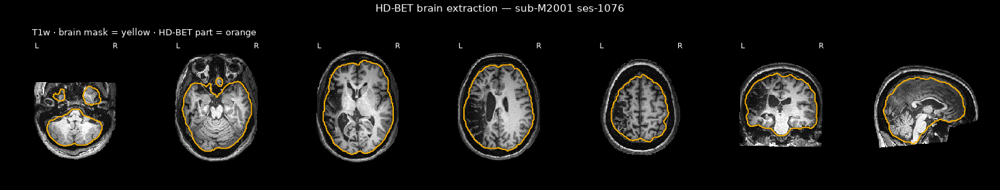

In [15]:
from calmar.scheduled import submit_step
from calmar.step_summary import show_step

if not RUN_TEST:
    print("RUN_TEST = False — continuing into batch processing")
else:
    test_entry = SUBJECTS[TEST_SUBJECT_IDX]          # chosen in the cell above
    brain = submit_step("brain", [test_entry], study, timings=BATCH_TIMINGS)
    show_step(brain, study, title="Brain extraction (HD-BET)")

#### Step 2 — Lesion segmentation 1 (LINDA)

*Optional:* runs only when `"linda"` is in `SEGMENTATION_METHODS`. Without LINDA, the template registration is done by the registration step after SynthStroke instead.

**What:** LINDA (`linda/0.5.1`) segments the chronic stroke lesion on the T1w and registers the brain nonlinearly to its template.
**Inputs:** T1w + the brain mask from step 1 (HD-BET, or the union with SynthStrip after a skull-strip repair). The mask is passed to LINDA's R API as `brain_mask=`, which skips LINDA's own skull strip (`src/analysis_17_linda_predict_with_mask.sh`).
**Outputs** (`derivatives/linda/sub-*/ses-*/anat/`): `Prediction3_native.nii.gz` (lesion in T1w space; this is the mask you edit in QC), `Lesion_in_MNI.nii.gz`, `Subject_in_MNI.nii.gz` and the transforms `Reg3_sub_to_template_*`, which later steps reuse to bring other masks into the same space.

**Template space (MNI152).** LINDA registers each brain to its own template, **ch2 (Colin27)**: a single person's brain in MNI coordinates. The atlases (Harvard-Oxford, JHU, Schaefer, Destrieux), the BCBToolkit tractograms and DeepDisco are defined on the population-average **FSL MNI152** template (MNI152NLin6Asym). So ch2 is registered to MNI152 once (`src/analysis_38_template_ch2_to_mni152.sh`, ANTs SyN, brain to brain; its QC figure is in `atlases/templates/ch2_to_MNI152NLin6Asym/qc.png`), and every mask is warped native → Penn → ch2 → MNI152 in **one** resampling. `*_in_MNI.nii.gz` files are on MNI152 (182×218×182, 1 mm); LINDA's original ch2 outputs are kept as `Subject_in_ch2` / `Lesion_in_ch2`.

**Check:**
- **In the viewer:** the red LINDA mask covers the lesion (dark on T1w) and no healthy tissue or ventricles. The number of blobs and the share of lesion outside the brain mask are reported as metrics (they describe LINDA's behaviour on this lesion).
- **In the static figure** (path in the summary, row 2): the warped T1w (`Subject_in_MNI`) lines up with the cyan MNI152 brain outline. `r` is its correlation with the MNI152 template inside the brain. Lesions and individual anatomy lower it; values below the threshold in `calmar/step_qc.py` (`TEMPLATE_CORR_MIN`, calibrated on this dataset) are flagged as a possible registration failure. The lesion volume is also compared before and after the warp: a change beyond ×0.5–×2 is flagged as a transform problem. Judge the outline overlap by eye.

linda: using unchanged results for 1 participant(s).


Participant,Result,Key metrics,⚠ Workflow checks,Time
sub-M2001 ses-1076,reused — unchanged since Slurm job 6,"Registration: T1 vs MNI152 template r = 0.47LINDA lesion: 261 ml in 5 blobs, 364 ml in template, 3% outside brain mask",—,9200 s

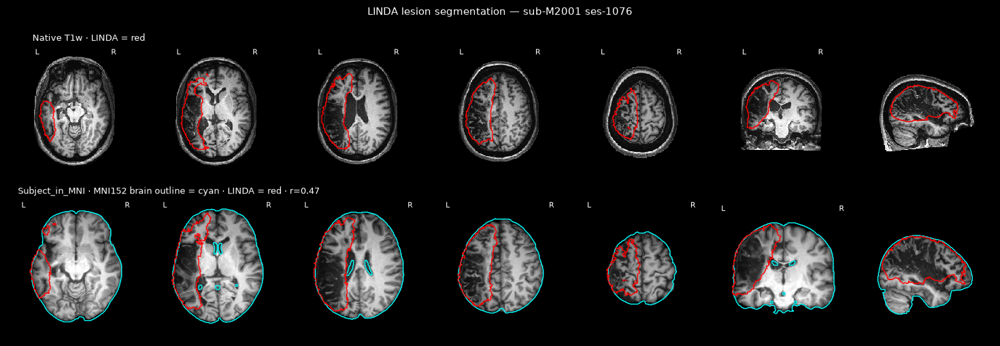

In [16]:
if not RUN_TEST:
    print("RUN_TEST = False — continuing into batch processing")
else:
    test_entry = SUBJECTS[TEST_SUBJECT_IDX]          # chosen with the participant picker
    linda = submit_step("linda", [test_entry], study, timings=BATCH_TIMINGS)
    show_step(linda, study, title="LINDA lesion segmentation")

#### Step 3 — Lesion segmentation 2 (SynthStroke)

*Optional:* runs only when `"synthstroke"` is in `SEGMENTATION_METHODS`.

**What:** SynthStroke (`synthstroke/0.0.0`, synth-plus weights in `SYNTHSTROKE_WEIGHTS_DIR`) is an independent deep-learning lesion segmenter. Having two methods lets you compare them and choose the better mask for each participant.
**Post-processing (automatic):** SynthStroke sees the whole head and sometimes labels skull or neck as lesion. Voxels outside the brain mask of step 1, dilated by 2 voxels, are removed. The untouched prediction is kept as `prediction_lesion_mask_raw.nii.gz`. With LINDA, the mask is then warped to MNI152 with LINDA's transforms plus the ch2 → MNI152 template transform (one resampling), giving `SynthStroke_in_MNI.nii.gz`; without LINDA the registration step below does this.
**Parameters:** `SYNTHSTROKE_TTA` (test-time augmentation), `SYNTHSTROKE_TIMEOUT`. The run refuses the baseline model unless `SYNTHSTROKE_ALLOW_BASELINE`.

**Check:** green (SynthStroke) and, when LINDA ran, red (LINDA) outlines on the T1w. Dice describes how much the two methods agree on this lesion. Methods can legitimately differ by lesion type, so use it, with the figure, to choose which mask to interpret in Quality control. "Removed outside brain" is the volume the clean-up step took away. The warp to the template is checked like LINDA's (volume change beyond ×0.5–×2 is flagged).

synthstroke: using unchanged results for 1 participant(s).


Participant,Result,Key metrics,⚠ Workflow checks,Time
sub-M2001 ses-1076,reused — unchanged since Slurm job 7,"SynthStroke lesion: 95.5 ml in 2 blobs, 123 ml in template, <1% outside brain maskAgreement (Dice): SynthStroke vs LINDA 0.53",—,168 s

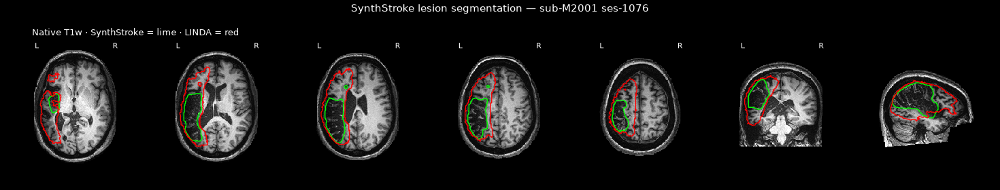

In [17]:
if not RUN_TEST:
    print("RUN_TEST = False — continuing into batch processing")
else:
    test_entry = SUBJECTS[TEST_SUBJECT_IDX]          # chosen with the participant picker
    synthstroke = submit_step("synthstroke", [test_entry], study, timings=BATCH_TIMINGS)
    show_step(synthstroke, study, title="SynthStroke lesion segmentation")

#### Step 3b — Template registration without LINDA (ANTs)

*Runs only when `"linda"` is not in `SEGMENTATION_METHODS`;* with LINDA, its own registration is reused and this cell submits nothing.

**What:** registers each brain to the FSL MNI152 template (MNI152NLin6Asym, 1 mm), the space of the atlases, BCBToolkit and DeepDisco, with ANTs (`ants/2.6.5`, `src/analysis_29_registration.sh`).
**How:** the brain-extracted T1w (mask of step 1) to the MNI152 brain: an affine stage (Mattes mutual information, one thread, seed `REGISTRATION_SEED`), then a nonlinear SyN stage (cross-correlation, `REGISTRATION_THREADS` threads). This is ANTs' documented route to a reproducible result: only the affine metric depends on the thread count. The **SynthStroke lesion, dilated by 2 voxels, is excluded from the cost function** (cost-function masking), so the lesion does not pull the warp; this is why the step runs after SynthStroke.
**Outputs** (`derivatives/registration/sub-*/ses-*/anat/`): the transforms `T1w_to_MNI152_0GenericAffine.mat` + `T1w_to_MNI152_1Warp.nii.gz` (+ inverse), `Subject_in_MNI.nii.gz` (whole-head T1w on MNI152), `SynthStroke_in_MNI.nii.gz` and the cost-function mask. The manual mask's products are kept here too.

**Check:** in the viewer, the warped T1w fills the cyan MNI152 brain outline, with ventricles and cortex in place, and the SynthStroke lesion sits on the dark lesion. After the manual-mask step has run, the same viewer also offers the manual lesion as a separate layer so its template-space placement can be checked. The summary gives the correlation `r` with the template (flagged when unusually low) and flags a lesion volume change beyond ×0.5–×2 between native and template space.


In [18]:
if not RUN_TEST:
    print("RUN_TEST = False — continuing into batch processing")
else:
    test_entry = SUBJECTS[TEST_SUBJECT_IDX]          # chosen with the participant picker
    registration = submit_step("registration", [test_entry], study, timings=BATCH_TIMINGS)
    show_step(registration, study, title="Template registration (ANTs, without LINDA)")


registration: skipped, not needed: LINDA's registration to the template is used.


Participant,Result,Key metrics,⚠ Workflow checks,Time
sub-M2001 ses-1076,skipped,—,—,0 s


#### Acute route: OpenADS on diffusion-weighted images

*Runs only when `CONFIG["MODALITY"] = "dwi"`;* in the chronic (T1) route this cell submits nothing, and in the acute route the brain-extraction, LINDA, SynthStroke and registration cells submit nothing.

**What:** OpenADS (`openadscpu/1.0.0`) segments the acute ischaemic lesion on the diffusion-weighted image (b1000 trace) with its ADC map. It also registers the DWI to MNI152 (affine + SyN against its JHU ADC template), and the native lesion is warped to the pipeline's FSL MNI152 with those transforms. Checked on 10 ISLES-2022 cases: same side in all, OpenADS-vs-expert Dice 0.75–0.91 in template space for most lesions; very small lesions are often missed.
**Dataset:** BIDS with `sub-*/ses-*/dwi/*_dwi.nii.gz` and a matching `*_adc.nii.gz` (the ISLES-2022 layout). For an extracted ISLES-2022 dataset set `DATASET_SOURCE = "isles2022"`, `LOCAL_DATASET` to the root containing `sub-strokecase*` and `derivatives/`, and `MODALITY = "dwi"`. The guided notebook exposes this as **ISLES 2022 (local)**, validates DWI+ADC pairs before starting, and recognises the official `derivatives/{sub}/{ses}/{sub}_{ses}_msk.nii.gz` expert masks automatically.
**Interpretation:** most knowledge-base findings come from chronic-stroke studies; the report marks each finding's study phase and says when it differs from this participant's (acute).

**Check:** the lesion is bright on the DWI and dark on the ADC map; in template space it stays on the same side and keeps its volume within ×0.5–×2.


In [19]:
if not RUN_TEST:
    print("RUN_TEST = False — continuing into batch processing")
else:
    test_entry = SUBJECTS[TEST_SUBJECT_IDX]          # chosen with the participant picker
    openads = submit_step("openads", [test_entry], study, timings=BATCH_TIMINGS)
    show_step(openads, study, title="OpenADS acute lesion segmentation (DWI)")


openads: skipped, OpenADS runs only in the acute (DWI) route, CONFIG["MODALITY"] = "dwi".


Participant,Result,Key metrics,⚠ Workflow checks,Time
sub-M2001 ses-1076,skipped,—,—,0 s


#### Step 4 — Manual (reference) mask

**What:** brings an expert-drawn lesion mask, when one exists, into the T1w space and then the template space, so the automatic masks can be scored against it.
**Where it comes from:** `MANUAL_MASK_PATH`, or the dataset publisher's `derivatives/lesion_masks`, preferring the T1w's own session. If only another session's mask exists it is still used, and flagged: the lesion and the brain may have changed between scans.
**How:** for masks drawn on another scan (here the T2w), that scan is rigidly registered to the T1w (SimpleITK, Mattes mutual information, 3 resolution levels, seed `REGISTRATION_SEED`). The mask follows with nearest-neighbour interpolation and is then warped to MNI152 with the template registration, LINDA's or the registration step's (`ExpertMask_in_MNI.nii.gz`).

**What to check in the viewer:**
- **Registration:** tick **Registered reference scan** on and off. Its anatomy (ventricles, cortex, the lesion) should line up with the T1w and the blue manual mask should sit on the visible lesion. If it is offset, the registration failed and every Dice score is meaningless.
- **Agreement:** the manual mask (blue) with LINDA (red) and SynthStroke (green, ticked off at first). The summary gives each method's Dice with the manual mask (1 = identical) and **why** it is not 1: how much of the manual lesion the method covers, and how much of the method's mask lies inside the manual lesion. Low coverage = the method misses part of the lesion; little inside = it also labels tissue the expert did not. These describe the tools on this lesion; they are not workflow errors. A manual mask drawn on a T2w often includes tissue that looks abnormal only on T2 (gliosis around the cavity), which T1-based tools leave out.

Workflow checks here: a mask from another session; more than 5% of the registered mask outside the head, meaning the registration failed (the head, not the brain mask, is used because chronic lesions include CSF-filled cavities that brain extraction leaves out); and the lesion volume before and after the warp to the template.

manual: using unchanged results for 1 participant(s).


Participant,Result,Key metrics,⚠ Workflow checks,Time
sub-M2001 ses-1076,reused — unchanged since Slurm job 8,"Manual mask: drawn on another scan, rigidly registered to this T1 (mask from ses-1253, T1 from ses-1076)LINDA lesion: 261 mlSynthStroke lesion: 95.5 mlManual lesion: 150 ml in 6 blobs, 202 ml in template, <1% outside brain mask, 0% outside headAgreement (Dice): LINDA vs Manual 0.66 · LINDA vs Manual (template) 0.66 · SynthStroke vs Manual 0.74Versus manual: LINDA covers 91% of the manual lesion and 52% of LINDA lies inside it (1.7× the manual volume: larger) · SynthStroke covers 61% of the manual lesion and 95% of SynthStroke lies inside it (0.6× the manual volume: smaller)","⚠ manual mask drawn on ses-1253, T1 is ses-1076: cross-session registration; lesion extent may differ between scans",74 s

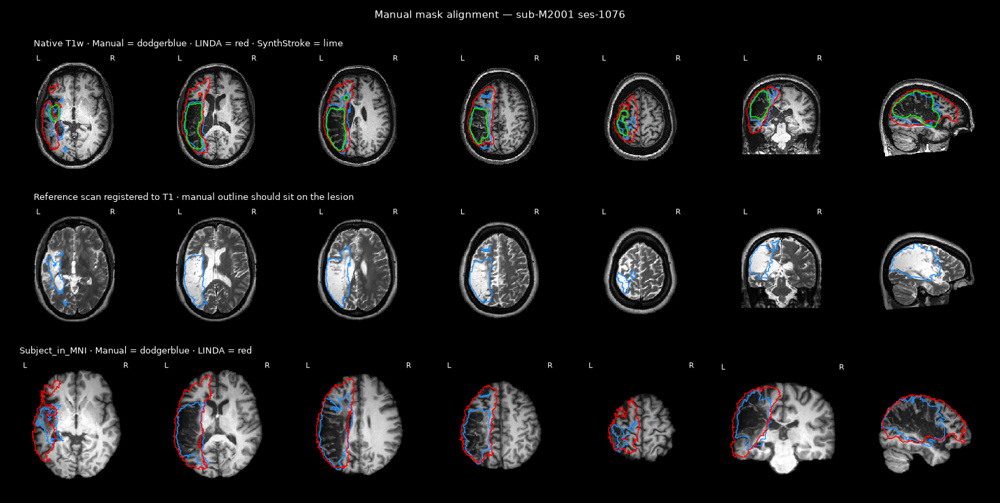

In [20]:
if not RUN_TEST:
    print("RUN_TEST = False — continuing into batch processing")
else:
    test_entry = SUBJECTS[TEST_SUBJECT_IDX]          # chosen with the participant picker
    manual = submit_step("manual", [test_entry], study, timings=BATCH_TIMINGS)
    show_step(manual, title="Manual mask registration and agreement")
    # Keep native registration and template-space inspection in one tabbed view.
    import ipywidgets as widgets
    from calmar.study import stage_selected
    from calmar.step_viewer import show_step_viewer
    _manual_views = []
    _native_view = show_step_viewer("manual", [test_entry], study, key="step_manual", display_panel=False)
    if _native_view is not None:
        _manual_views.append(("Native mask and reference scan", _native_view["panel"]))
    if (stage_selected("registration", globals().get("CONFIG", getattr(study, "config", {})))
            and cm.present(study.template_dir(test_entry) / "ExpertMask_in_MNI.nii.gz")):
        _mni_view = show_step_viewer("registration", [test_entry], study, key="step_registration_manual", display_panel=False)
        if _mni_view is not None:
            _manual_views.append(("Template-space mask", _mni_view["panel"]))
    if len(_manual_views) > 1:
        _manual_tabs = widgets.Tab(children=[panel for _, panel in _manual_views], selected_index=0)
        for _i, (_title, _) in enumerate(_manual_views): _manual_tabs.set_title(_i, _title)
        display(_manual_tabs)
    elif _manual_views:
        display(_manual_views[0][1])

#### Optional acute DWI+ADC segmentation, diffusion tract microstructure and brain health for the test participant

Any optional analyses selected above that belong to this participant now run before the single-subject checkpoint. Acute DWI+ADC lesion segmentation runs with OpenADS; eligible gradient-bearing diffusion MRI runs shared QSIPrep preprocessing followed by the selected QSIRecon bundle-tractometry or DIPY tensor-map method; structural brain health runs the available SynthSeg and/or DeepWMH components. Their saved QC is shown here so failures are found before the batch. A different diffusion session remains linked to the selected anatomical session. Successfully completed entries are not recomputed in the later optional batch cells, including when `OVERWRITE=True`, provided their settings, inputs and outputs remain unchanged.

dmri_preproc: using unchanged results for 1 participant(s).


Participant,Result,Key metrics,⚠ Workflow checks,Time
sub-M2001 ses-1225,reused — unchanged since Slurm job 9,preprocessed_dwi: 1reports: 8hmc_method: tortoisecross_session_anatomy: True,⚠ cross-session anatomy/lesion mask,2225 s


dmri_recon: using unchanged results for 1 participant(s).


Participant,Result,Key metrics,⚠ Workflow checks,Time
sub-M2001 ses-1225,reused — unchanged since Slurm job 10,tractometry_tables: 1bundles: 76reports: 5recon_spec: ss3t_fod_autotrack,⚠ patient-specific stroke tractography requires visual QC,9381 s


dmri_metrics: using unchanged results for 1 participant(s).


Participant,Result,Key metrics,⚠ Workflow checks,Time
sub-M2001 ses-1225,reused — unchanged since Slurm job 19,tracts: 76source_tables: 1,⚠ no opposite phase-encoding DWI; susceptibility correction is limited⚠ diffusion and anatomical lesion mask come from different sessions⚠ lesion-to-bundle overlap and valid-voxel coverage are not yet calculated⚠ patient-specific bundle absence is not evidence of anatomical disconnection,0 s



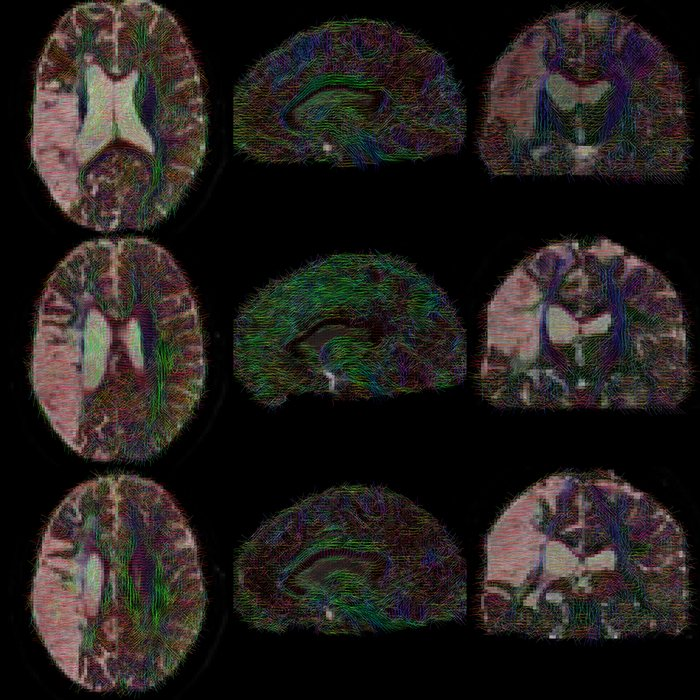

Review this selected-method preview and the linked full reports before accepting participant diffusion measurements.
brain_health_anatomy: using unchanged results for 1 participant(s).


Participant,Result,Key metrics,⚠ Workflow checks,Time
sub-M2001 ses-1076,reused — unchanged since Slurm job 20,"intracranial_volume_ml: 1,449brain_tissue_volume_ml: 1,155brain_parenchymal_fraction: 0.797lesion_cavity_ml: 17.3lesion_adjusted_brain_parenchymal_fraction: 0.809lateral_ventricle_fraction: 0.0319lesion_masked_lateral_ventricle_fraction: 0.0263lesion_ventricle_overlap_ml: 8.08left_lateral_ventricle_ml: 31.4right_lateral_ventricle_ml: 14.7",⚠ stroke lesion overlaps SynthSeg lateral-ventricle labels; raw ventricle volumes may reflect the cavity,118 s

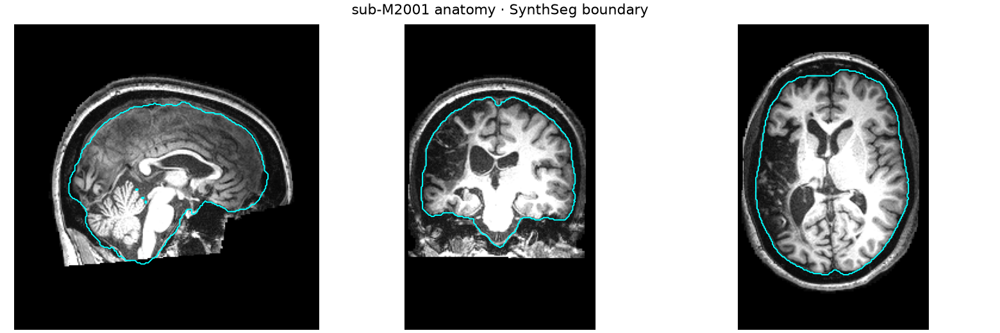

brain_health_metrics: using unchanged results for 1 participant(s).


Participant,Result,Key metrics,⚠ Workflow checks,Time
sub-M2001 ses-1076,reused — unchanged since Slurm job 21,"intracranial_volume_ml: 1,449brain_tissue_volume_ml: 1,155brain_parenchymal_fraction: 0.797lesion_cavity_ml: 17.3lesion_adjusted_brain_parenchymal_fraction: 0.809lateral_ventricle_fraction: 0.0319lesion_masked_lateral_ventricle_fraction: 0.0263lesion_ventricle_overlap_ml: 8.08left_lateral_ventricle_ml: 31.4right_lateral_ventricle_ml: 14.7",⚠ stroke lesion overlaps SynthSeg lateral-ventricle labels; raw ventricle volumes may reflect the cavity,2 s

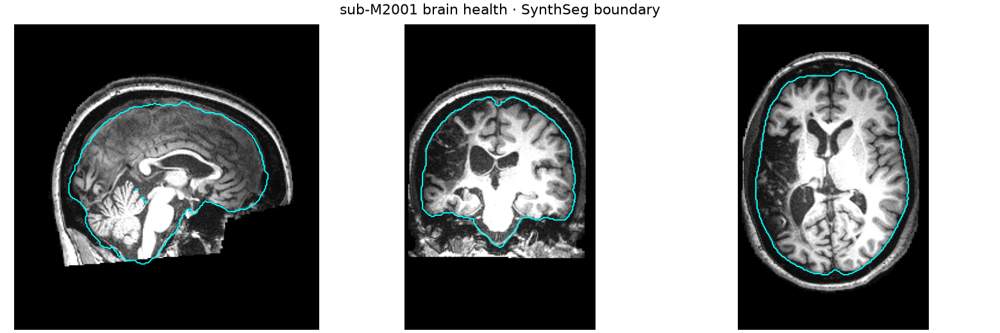

Review each brain_health_qc.png before treating these provisional features as interpretable.
Optional analyses not selected or not available for this test participant (selections for other participants run in the batch section): acute DWI+ADC/OpenADS lesion segmentation.


In [21]:
if not RUN_TEST:
    print("RUN_TEST = False — continuing into batch processing")
else:
    from calmar.single_subject import mark_optional_completed, optional_entries_for_test
    _single_optional_completed = globals().setdefault("_SINGLE_OPTIONAL_COMPLETED", {})
    _single_optional_skipped = []
    _test_entry = SUBJECTS[TEST_SUBJECT_IDX]

    _test_dwi = optional_entries_for_test(globals().get("DWI_SUBJECTS"), _test_entry)
    if CONFIG.get("MODALITY", "t1") == "dwi":
        print("DWI is the primary route; its OpenADS test already ran in the main single-subject cells.")
    elif _test_dwi:
        try:
            test_dwi_acquisition = submit_step("acquisition", _test_dwi, DWI_STUDY, timings=BATCH_TIMINGS)
            show_step(test_dwi_acquisition, title="Test participant DWI+ADC acquisition", images=True)
            test_dwi_openads = submit_step("openads", _test_dwi, DWI_STUDY, timings=BATCH_TIMINGS)
            show_step(test_dwi_openads, DWI_STUDY, title="Test participant OpenADS acute DWI+ADC segmentation", images=True)
            if not mark_optional_completed(_single_optional_completed, "dwi", _test_dwi, DWI_STUDY,
                                           [test_dwi_acquisition, test_dwi_openads]):
                print("DWI completion evidence could not be recorded; the later batch will rerun it safely.")
        except Exception as exc:
            DWI_ERROR = str(exc)
            print(f"Optional DWI test failed; it was not marked complete and the lesion test will continue. {exc}")
    else:
        _single_optional_skipped.append("acute DWI+ADC/OpenADS lesion segmentation")

    _test_dmri = optional_entries_for_test(globals().get("DMRI_SUBJECTS"), _test_entry)
    if _test_dmri:
        try:
            test_dmri_preproc = submit_step("dmri_preproc", _test_dmri, DMRI_STUDY, timings=BATCH_TIMINGS)
            show_step(test_dmri_preproc, title="Test participant lesion-aware QSIPrep", viewer=False)
            test_dmri_recon = submit_step("dmri_recon", _test_dmri, DMRI_STUDY, timings=BATCH_TIMINGS)
            show_step(test_dmri_recon, title="Test participant diffusion reconstruction", viewer=False)
            test_dmri_metrics = submit_step("dmri_metrics", _test_dmri, DMRI_STUDY, timings=BATCH_TIMINGS)
            show_step(test_dmri_metrics, title="Test participant diffusion metrics", viewer=False)
            if not mark_optional_completed(_single_optional_completed, "dmri", _test_dmri, DMRI_STUDY,
                                           [test_dmri_preproc, test_dmri_recon, test_dmri_metrics]):
                print("Diffusion tract-microstructure completion evidence could not be recorded; the later batch will rerun it safely.")
            from calmar.dmri_visualization import show_dmri_visuals
            _SINGLE_DMRI_VISUALIZED = show_dmri_visuals(
                _test_dmri, DMRI_STUDY, title="Test participant diffusion visual review")
            print("Review this selected-method preview and the linked full reports before accepting participant diffusion measurements.")
        except Exception as exc:
            DMRI_ERROR = str(exc)
            print(f"Optional diffusion tract-microstructure test failed; it was not marked complete and the lesion test will continue. {exc}")
    else:
        _single_optional_skipped.append("diffusion tract-microstructure analysis")

    _test_brain_health = optional_entries_for_test(globals().get("BRAIN_HEALTH_SUBJECTS"), _test_entry)
    if _test_brain_health:
        try:
            _test_bh_anatomy = [e for e in _test_brain_health if "atrophy" in e["brain_health_components"]]
            _test_bh_wmh = [e for e in _test_brain_health if "wmh" in e["brain_health_components"]]
            _test_brain_health_results = []
            if _test_bh_anatomy:
                test_brain_health_anatomy = submit_step("brain_health_anatomy", _test_bh_anatomy, study, timings=BATCH_TIMINGS)
                show_step(test_brain_health_anatomy, title="Test participant T1 volumetry (SynthSeg)", images=True, viewer=False)
                _test_brain_health_results.append(test_brain_health_anatomy)
            if _test_bh_wmh:
                test_brain_health_wmh = submit_step("brain_health_wmh", _test_bh_wmh, study, timings=BATCH_TIMINGS)
                show_step(test_brain_health_wmh, title="Test participant FLAIR WMH candidates (DeepWMH)", images=True, viewer=False)
                _test_brain_health_results.append(test_brain_health_wmh)
            test_brain_health_metrics = submit_step("brain_health_metrics", _test_brain_health, study, timings=BATCH_TIMINGS)
            show_step(test_brain_health_metrics, title="Test participant stroke-aware brain-health features", images=True, viewer=False)
            _test_brain_health_results.append(test_brain_health_metrics)
            if not mark_optional_completed(_single_optional_completed, "brain_health", _test_brain_health, study,
                                           _test_brain_health_results):
                print("Brain-health completion evidence could not be recorded; the later batch will rerun it safely.")
            print("Review each brain_health_qc.png before treating these provisional features as interpretable.")
        except Exception as exc:
            BRAIN_HEALTH_ERROR = str(exc)
            print(f"Optional brain-health test failed; it was not marked complete and the lesion test will continue. {exc}")
    else:
        _single_optional_skipped.append("structural brain-health analysis")

    if _single_optional_skipped:
        print("Optional analyses not selected or not available for this test participant "
              "(selections for other participants run in the batch section): "
              + "; ".join(_single_optional_skipped) + ".")

#### BCBToolkit disconnectome

**What it does.** For each selected lesion mask, BCBToolkit (`bcbtoolkit/0.0.0`, `run_disco.sh`) estimates the *disconnectome*: for every voxel, the proportion of healthy reference tractograms whose streamlines pass through the lesion and then through that voxel (0–1). This moves from *where* the lesion is to *which connections it is likely to interrupt*. Optionally Tractotron gives per-tract disconnection probabilities. The next code cell runs this step for the test participant as a Slurm job (`src/analysis_27_bcb.sh`, ~8 min per mask); nothing runs in the notebook kernel.

**Inputs.** Template-space lesion masks, one per source: LINDA `derivatives/linda/…/Lesion_in_MNI.nii.gz`, SynthStroke `derivatives/synthstroke/…/SynthStroke_in_MNI.nii.gz`, manual `derivatives/linda/…/ExpertMask_in_MNI.nii.gz`. A missing mask is reported and skipped.

**Outputs** (in `derivatives/bcbtoolkit/<sub>/<ses>/anat/`):
- `Disconnectome_linda.nii.gz`, `Disconnectome_synthstroke.nii.gz`, `Disconnectome_expert.nii.gz` (manual mask; `expert` is the legacy file token) — on the same grid as the input mask.
- With Tractotron: `Tractotron_probs/` (LINDA) or `Tractotron_probs_<token>/`.

**Key parameters (CONFIG).**

| Setting | Default | Meaning |
|---|---|---|
| `BCB_MASKS` | `"all"` | `"all"`, `"both"` (LINDA + manual), or one of `"linda"`, `"synthstroke"`, `"manual"` |
| `BCB_INPUT_GRID` | `"mni152"` | The mask is placed on BCBToolkit's own FSL MNI152 1 mm grid **by world coordinates** before `run_disco.sh`, and the map is resampled back to the mask's grid the same way. BCBToolkit's built-in reslice of LINDA's 181×217×181 masks matches by *voxel index*, which shifts the lesion 1 mm posterior and 1 mm inferior. `"native"` = old behaviour (mask passed unchanged). |
| `BCB_RUN_TRACTOTRON` | `False` | Also run Tractotron (HCP1065 probabilistic atlas). |
| `BCB_OVERWRITE` | `False` | Replace existing maps. Without it, maps made with different settings (e.g. before `BCB_INPUT_GRID` existed) are kept and reported as **stale**, not silently reused. |

**Space.** The masks are on FSL MNI152, the template BCBToolkit's tractograms use (see step 2). `BCB_INPUT_GRID="mni152"` additionally guarantees the exact 182×218×182 grid by world coordinates.

**What to check in the viewer** (one map and lesion per mask source, ticked on or off; static figure in `reports/qc/steps/bcb/<sub>_<ses>.png`): the lesion (source colour) and the disconnectome heat map (values ≥ 0.1) on `Subject_in_MNI`. Workflow checks: the heat map must start **at** the lesion outline (an offset means a space or grid error), and an empty or out-of-range map is flagged automatically. The pathways it follows and its extent (`voxels_above_0.5`) describe BCBToolkit's estimate for this lesion; they are information, not errors.

bcb: using unchanged results for 1 participant(s).


Participant,Result,Key metrics,⚠ Workflow checks,Time
sub-M2001 ses-1076,reused — unchanged since Slurm job 22,"Map (LINDA lesion): 275,253 voxels above 0.5Map (SynthStroke lesion): 130,807 voxels above 0.5Map (Manual lesion): 252,364 voxels above 0.5",—,406 s

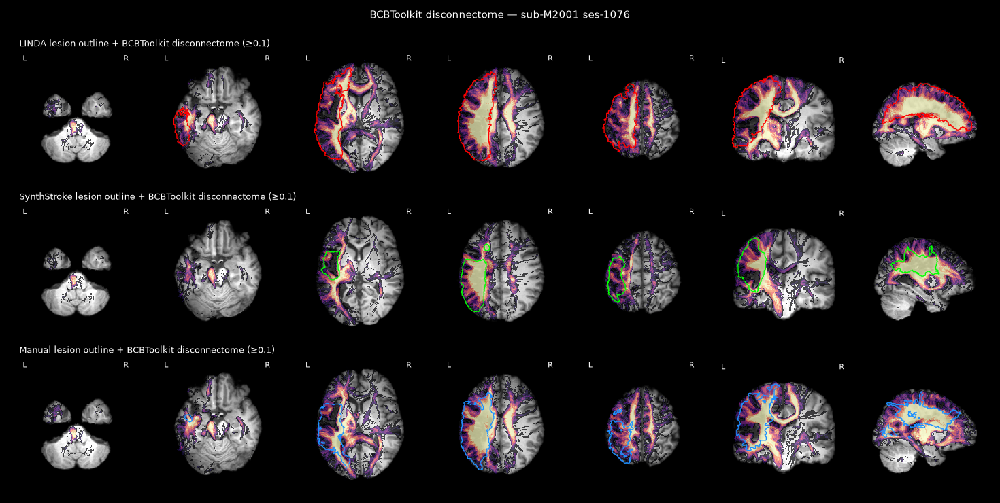

In [22]:
if not RUN_TEST:
    print("RUN_TEST = False — continuing into batch processing")
else:
    test_entry = SUBJECTS[TEST_SUBJECT_IDX]          # chosen with the participant picker
    bcb = submit_step("bcb", [test_entry], study, timings=BATCH_TIMINGS)
    show_step(bcb, study, title="BCBToolkit disconnectome")

#### DeepDisco disconnectome (deep learning)

**What it does.** DeepDisco (`deepdisco/20251008`, `deepdisco-cli`) is a neural network trained to predict BCBToolkit-style disconnectomes from a lesion mask, in seconds rather than minutes. It is run for each selected mask and for up to four fibre-class models: `whole_brain`, `association`, `projection`, `commissural`. The next code cell runs this step for the test participant as a Slurm job (`src/analysis_28_deepdisco.sh`); nothing runs in the notebook kernel.

**Inputs.** The same template-space lesion masks as BCBToolkit (LINDA `Lesion_in_MNI`, SynthStroke `SynthStroke_in_MNI`, manual `ExpertMask_in_MNI`). DeepDisco requires a binary mask on the FSL MNI152 **2 mm** grid (91×109×91), so each mask is downsampled first (threshold 0.5).

**Outputs** (in `derivatives/deepdisco/<sub>/<ses>/anat/`): `DeepDisco_<token>_<model>.nii.gz`, with `<token>` = `linda`, `synthstroke` or `expert` (manual) and `<model>` as above — on the 2 mm MNI152 grid.

**Key parameters (CONFIG).**

| Setting | Default | Meaning |
|---|---|---|
| `DEEPDISCO_MASK_SOURCE` | `"all"` | `"all"`, `"both"` (LINDA + manual), or one of `"linda"`, `"synthstroke"`, `"manual"` |
| `DEEPDISCO_RUN_ALL` | `True` | Run all four fibre-class models. If `False`, only `DEEPDISCO_MODELS` (a list of model names). |
| `DEEPDISCO_MODELS` | — | Models to run when `DEEPDISCO_RUN_ALL = False`. |
| `DEEPDISCO_DOWNSAMPLING` | `"coverage"` | A 2 mm voxel is lesion when **at least half of it** is covered by the 1 mm mask. `"nearest"` = old behaviour: point-samples one 1 mm sub-voxel, which can drop thin parts of a lesion. |
| `DEEPDISCO_OVERWRITE` | `False` | Replace existing maps; otherwise maps made with other settings are kept and reported as **stale**. |

**Space.** The masks are on FSL MNI152, the template DeepDisco was trained on; they are downsampled to its 2 mm grid.

**What to check in the viewer** (static figure in `reports/qc/steps/deepdisco/<sub>_<ses>.png`): as for BCBToolkit, the lesion plus one DeepDisco map (≥ 0.1) on `Subject_in_MNI`. Choose the lesion source (LINDA, SynthStroke, Manual) and the **model** (whole brain, association, projection, commissural fibres) with the buttons; the map changes with them. The metrics also report `<source>_r_vs_bcb`, the correlation with the BCBToolkit map over voxels where either map is > 0 (same definition as the comparison panel); it describes how closely the two methods' estimates agree for this lesion (they can legitimately differ), and is not a workflow check.

#### Comparing BCBToolkit and DeepDisco

The interactive panel below shows anatomy, the lesion and both disconnectomes in one viewer, with the same controls as the step viewers: choose the lesion source and the DeepDisco model with the buttons, tick **BCBToolkit map** and **DeepDisco map** on and off to compare them at the same location (both ticked = blended), choose the plane and **Centre on lesion**. Opening **Agreement metrics** computes (once, as a Slurm reporting job, then cached):

- **Pearson r** — voxel-wise correlation of the two maps (clipped to 0–1; DeepDisco linearly resampled onto the BCBToolkit grid), over voxels where either map is > 0. It asks whether the *pattern* of disconnection is the same, regardless of overall scale. The QC figure's `r_vs_bcb` uses the same definition (computed on the participant's template grid).
- **Dice (threshold 0.5)** — overlap of the voxels each method calls disconnected (value > 0.5): 2·|A∩B| / (|A|+|B|); 1 = same extent, 0 = no overlap. The voxel counts above 0.5 are shown for each method.

**Interpreting disagreement.** High r with low Dice usually means the same tracts are implicated but one method is more conservative (compare the voxel counts). Low r means the methods implicate different tracts: inspect both maps against the lesion. BCBToolkit is the reference method that DeepDisco approximates; because DeepDisco works at 2 mm, expect the largest differences for small or thin lesions and at lesion edges.

deepdisco: using unchanged results for 1 participant(s).


Participant,Result,Key metrics,⚠ Workflow checks,Time
sub-M2001 ses-1076,reused — unchanged since Slurm job 23,"Map (LINDA lesion): 518,012 voxels above 0.5, r = 0.84 with BCBToolkitMap (SynthStroke lesion): 288,068 voxels above 0.5, r = 0.77 with BCBToolkitMap (Manual lesion): 476,427 voxels above 0.5, r = 0.83 with BCBToolkit",—,175 s

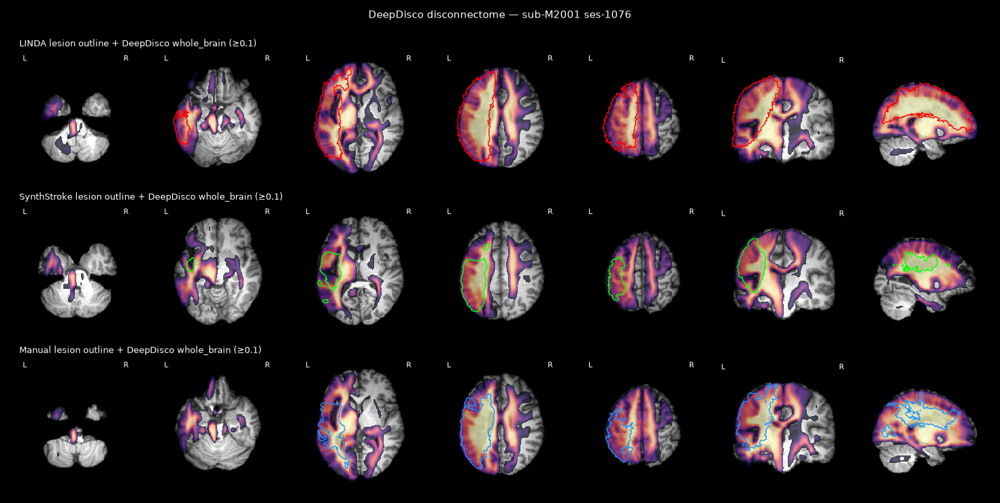

In [23]:
if not RUN_TEST:
    print("RUN_TEST = False — continuing into batch processing")
else:
    test_entry = SUBJECTS[TEST_SUBJECT_IDX]          # chosen with the participant picker
    deepdisco = submit_step("deepdisco", [test_entry], study, timings=BATCH_TIMINGS)
    show_step(deepdisco, study, title="DeepDisco disconnectome")

In [24]:
# BCBToolkit vs DeepDisco — interactive comparison for the test participant.
COMPARE_MASK_SOURCE = None          # "linda" | "synthstroke" | "manual"; None = first source with maps
COMPARE_MODEL = "whole_brain"       # DeepDisco map shown first: whole_brain | association | projection | commissural

if not RUN_TEST:
    print('RUN_TEST = False — continuing into batch processing')
else:
    from calmar.disconnectome_compare import show_disconnectome_comparison
    entry = SUBJECTS[TEST_SUBJECT_IDX]
    # One NiiVue viewer; the participant menu also offers the other discovered participants.
    # Agreement metrics (Pearson r, Dice > 0.5) run as a Slurm reporting job when their section is opened.
    _disconnectome_comparison = show_disconnectome_comparison(
        study, entry, mask_source=COMPARE_MASK_SOURCE, model=COMPARE_MODEL, entries=SUBJECTS)

### Continue to batch or jump to reporting

Review the single-subject results above, then choose **Continue to batch** to process the cohort and stop at QC, or **Jump to reporting** to open report setup and selection using available outputs. Jumping does not mark QC as completed. Earlier cells remain available for reruns while paused.


In [25]:
# Pause after the single-subject test; skipped in batch mode (RUN_TEST = False).
if RUN_TEST:
    show_timings(min_seconds=1.0)
    from calmar.execution import pause_before_batch
    _batch_checkpoint = pause_before_batch()
    _batch_checkpoint._resume()
    assert not _batch_checkpoint.paused
    print("Demo: continuing to the batch; completed test steps are reused.")
else:
    print("RUN_TEST = False — continuing into batch processing")

**If the buttons do not respond (‘Loading widget…’ or ‘Waiting…’):** insert a temporary code cell and run this command by itself:

```python
%calmar_continue batch
```

This releases the batch checkpoint. Then select the first batch code cell below and choose **Run → Run All Cells Below**. Execution will pause at QC.

To go to reporting instead (the **Jump to reporting** button), run `%calmar_continue report` by itself, then run the report cells one by one.

Demo: continuing to the batch; completed test steps are reused.


## Batch processing

The same steps as the single-subject test, for every participant in `SUBJECTS`. Each participant is a separate Slurm job, so participants run in parallel, have their own logs and time limit, and one failure does not stop the others. A step reports all failures after every job has finished.

Participants whose inputs and outputs are unchanged since their last successful job are reused, not recomputed. Review the summary tables: their ⚠ workflow checks point to pipeline problems (inputs, registrations, spaces, outdated methods) before you spend time on detailed QC; the metrics describe each tool's output.

#### Brain extraction + LINDA

Brain extraction, then LINDA lesion segmentation and template registration (see steps 1–2 above for details and what to check). LINDA is skipped when it is not in `SEGMENTATION_METHODS`.

In [26]:
print("Demo: following the full batch workflow before reporting.")

Demo: following the full batch workflow before reporting.


brain: skipped, not part of the acute (DWI) route.


brain: skipped, not part of the acute (DWI) route.


brain: using unchanged results for 2 participant(s).


Participant,Result,Key metrics,⚠ Workflow checks,Time
sub-M2001 ses-1076,reused — unchanged since Slurm job 5,"Brain: 1,348 ml, 0 ml added by SynthStriphdbet_volume_ml: 1,348",—,30 s
sub-M2004 ses-524,reused — unchanged since Slurm job 24,"Brain: 1,268 ml, 0 ml added by SynthStriphdbet_volume_ml: 1,268",—,25 s
sub-strokecase0001 ses-0001,skipped,—,—,0 s
sub-strokecase0002 ses-0001,skipped,—,—,0 s

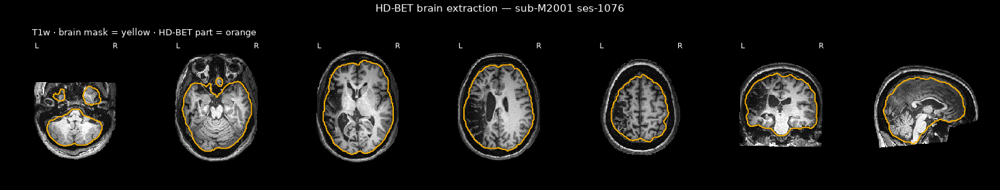
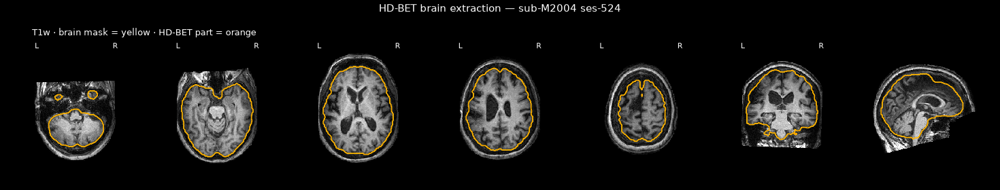

linda: skipped, not part of the acute (DWI) route.


linda: skipped, not part of the acute (DWI) route.


linda: using unchanged results for 2 participant(s).


Participant,Result,Key metrics,⚠ Workflow checks,Time
sub-M2001 ses-1076,reused — unchanged since Slurm job 6,"Registration: T1 vs MNI152 template r = 0.47LINDA lesion: 261 ml in 5 blobs, 364 ml in template, 3% outside brain mask",—,9200 s
sub-M2004 ses-524,reused — unchanged since Slurm job 25,"Registration: T1 vs MNI152 template r = 0.63LINDA lesion: 160 ml in 24 blobs, 253 ml in template, 4% outside brain mask",—,10821 s
sub-strokecase0001 ses-0001,skipped,—,—,0 s
sub-strokecase0002 ses-0001,skipped,—,—,0 s

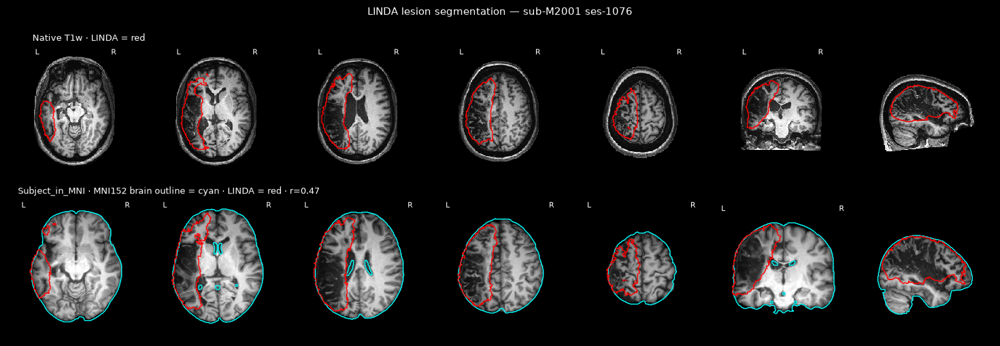
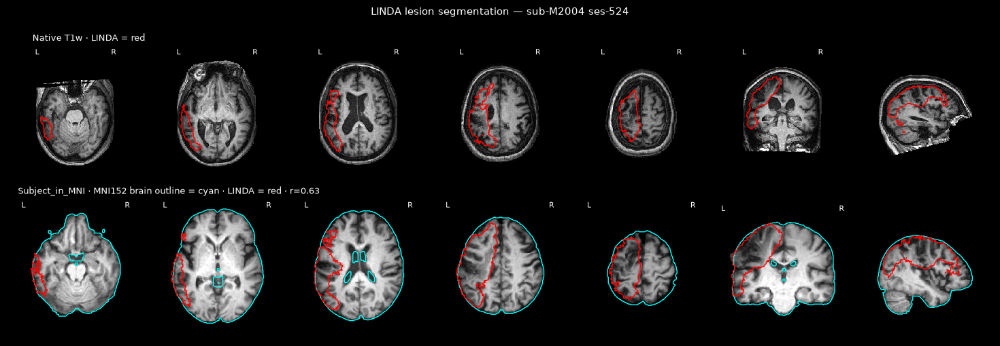

In [27]:
from calmar.scheduled import submit_step
from calmar.step_summary import show_step

brain = submit_step("brain", SUBJECTS, study, timings=BATCH_TIMINGS)
show_step(brain, study, title="Brain extraction (HD-BET) — all participants")
linda = submit_step("linda", SUBJECTS, study, timings=BATCH_TIMINGS)
show_step(linda, study, title="LINDA lesion segmentation — all participants")

#### SynthStroke

Second segmentation, with clean-up outside the brain and warp to the template (see step 3).

synthstroke: skipped, not part of the acute (DWI) route.


synthstroke: skipped, not part of the acute (DWI) route.


synthstroke: using unchanged results for 2 participant(s).


Participant,Result,Key metrics,⚠ Workflow checks,Time
sub-M2001 ses-1076,reused — unchanged since Slurm job 7,"SynthStroke lesion: 95.5 ml in 2 blobs, 123 ml in template, <1% outside brain maskAgreement (Dice): SynthStroke vs LINDA 0.53",—,168 s
sub-M2004 ses-524,reused — unchanged since Slurm job 26,"SynthStroke lesion: 22.7 ml in 1 blob, 36.7 ml in template, 0% outside brain maskAgreement (Dice): SynthStroke vs LINDA 0.21",—,170 s
sub-strokecase0001 ses-0001,skipped,—,—,0 s
sub-strokecase0002 ses-0001,skipped,—,—,0 s

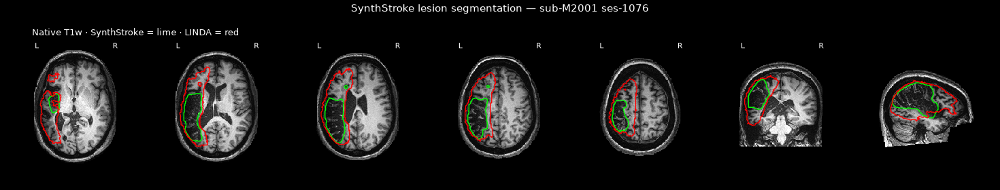
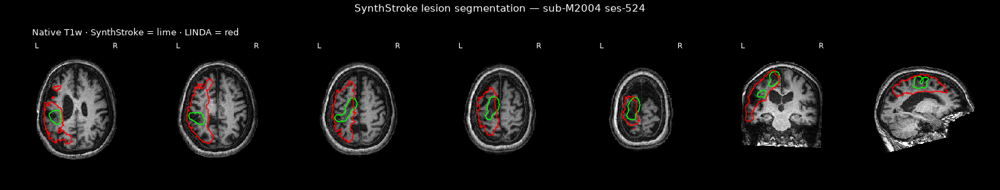

In [28]:
synthstroke = submit_step("synthstroke", SUBJECTS, study, timings=BATCH_TIMINGS)
show_step(synthstroke, study, title="SynthStroke lesion segmentation — all participants")

#### Template registration (without LINDA)

ANTs registration to the template for each participant, when LINDA is not in `SEGMENTATION_METHODS` (see step 3b). With LINDA nothing is submitted.


In [29]:
registration = submit_step("registration", SUBJECTS, study, timings=BATCH_TIMINGS)
show_step(registration, study, title="Template registration (ANTs, without LINDA) — all participants")


registration: skipped, not needed: LINDA's registration to the template is used.


registration: skipped, not needed: LINDA's registration to the template is used.


registration: skipped, not part of the acute (DWI) route.


registration: skipped, not part of the acute (DWI) route.


Participant,Result,Key metrics,⚠ Workflow checks,Time
sub-M2001 ses-1076,skipped,—,—,0 s
sub-M2004 ses-524,skipped,—,—,0 s
sub-strokecase0001 ses-0001,skipped,—,—,0 s
sub-strokecase0002 ses-0001,skipped,—,—,0 s


#### OpenADS (acute route)

OpenADS segmentation and its registration to the template for each participant, when `MODALITY = "dwi"` (see the acute-route step above). In the chronic route nothing is submitted.


openads: skipped, OpenADS runs only in the acute (DWI) route, CONFIG["MODALITY"] = "dwi".


openads: skipped, OpenADS runs only in the acute (DWI) route, CONFIG["MODALITY"] = "dwi".


openads: using unchanged results for 2 participant(s).


Participant,Result,Key metrics,⚠ Workflow checks,Time
sub-M2001 ses-1076,skipped,—,—,0 s
sub-M2004 ses-524,skipped,—,—,0 s
sub-strokecase0001 ses-0001,reused — unchanged since Slurm job 27,"OpenADS lesion: 3.33 ml in 20 blobs, 5.93 ml in template, 0% outside brain mask",—,426 s
sub-strokecase0002 ses-0001,reused — unchanged since Slurm job 28,"OpenADS lesion: 1.29 ml in 1 blob, 1.29 ml in template, 0% outside brain mask",—,421 s

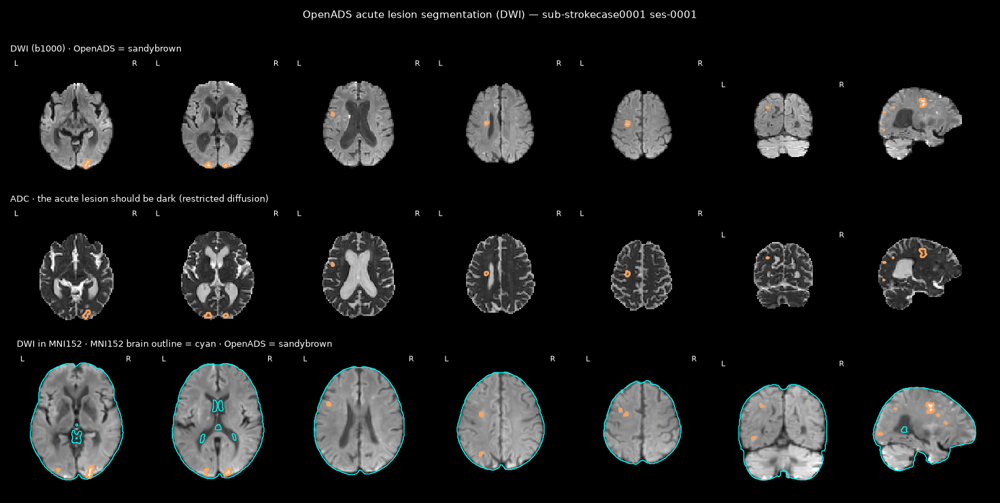
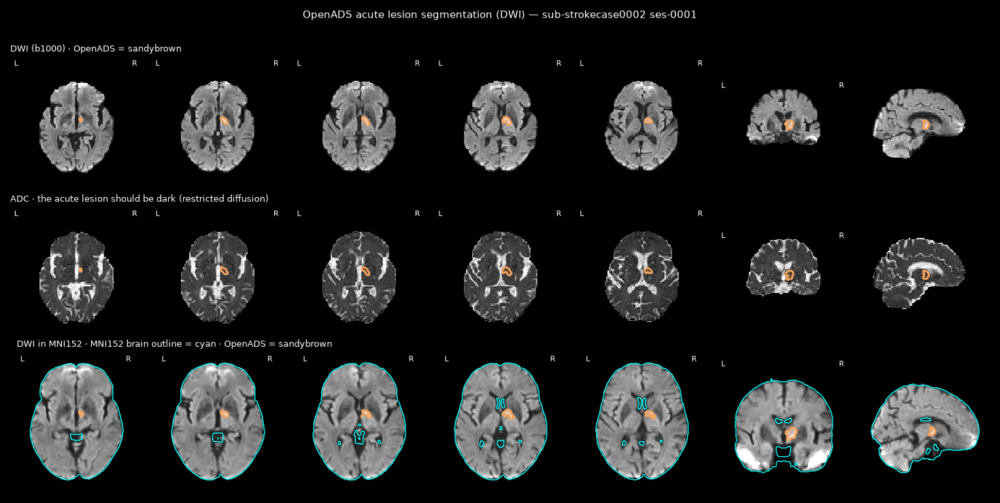

In [30]:
openads = submit_step("openads", SUBJECTS, study, timings=BATCH_TIMINGS)
show_step(openads, study, title="OpenADS acute lesion segmentation (DWI) — all participants")


#### Manual masks

Registration of available expert masks to T1w and template space, with agreement scores (see step 4). Participants without a manual mask are listed as skipped.

manual: using unchanged results for 4 participant(s).


Participant,Result,Key metrics,⚠ Workflow checks,Time
sub-M2001 ses-1076,reused — unchanged since Slurm job 8,"Manual mask: drawn on another scan, rigidly registered to this T1 (mask from ses-1253, T1 from ses-1076)LINDA lesion: 261 mlSynthStroke lesion: 95.5 mlManual lesion: 150 ml in 6 blobs, 202 ml in template, <1% outside brain mask, 0% outside headAgreement (Dice): LINDA vs Manual 0.66 · LINDA vs Manual (template) 0.66 · SynthStroke vs Manual 0.74Versus manual: LINDA covers 91% of the manual lesion and 52% of LINDA lies inside it (1.7× the manual volume: larger) · SynthStroke covers 61% of the manual lesion and 95% of SynthStroke lies inside it (0.6× the manual volume: smaller)","⚠ manual mask drawn on ses-1253, T1 is ses-1076: cross-session registration; lesion extent may differ between scans",74 s
sub-M2004 ses-524,reused — unchanged since Slurm job 29,"Manual mask: drawn on another scan, rigidly registered to this T1 (mask from ses-755, T1 from ses-524)LINDA lesion: 160 mlSynthStroke lesion: 22.7 mlManual lesion: 46.9 ml in 13 blobs, 77.4 ml in template, 4% outside brain mask, 0% outside headAgreement (Dice): LINDA vs Manual 0.37 · LINDA vs Manual (template) 0.41 · SynthStroke vs Manual 0.58Versus manual: LINDA covers 82% of the manual lesion and 24% of LINDA lies inside it (3.4× the manual volume: larger) · SynthStroke covers 43% of the manual lesion and 90% of SynthStroke lies inside it (0.5× the manual volume: smaller)","⚠ manual mask drawn on ses-755, T1 is ses-524: cross-session registration; lesion extent may differ between scans",75 s
sub-strokecase0001 ses-0001,reused — unchanged since Slurm job 30,"Manual mask: drawn on this scan (no registration needed)OpenADS lesion: 3.33 mlManual lesion: 6.68 ml in 38 blobs, 11.3 ml in template, 0% outside headAgreement (Dice): OpenADS vs Manual 0.61Versus manual: OpenADS covers 46% of the manual lesion and 92% of OpenADS lies inside it (0.5× the manual volume: smaller)",—,3 s
sub-strokecase0002 ses-0001,reused — unchanged since Slurm job 31,"Manual mask: drawn on this scan (no registration needed)OpenADS lesion: 1.29 mlManual lesion: 0.94 ml in 1 blob, 0.89 ml in template, 0% outside headAgreement (Dice): OpenADS vs Manual 0.82Versus manual: OpenADS covers 98% of the manual lesion and 71% of OpenADS lies inside it (1.4× the manual volume: larger)",—,3 s

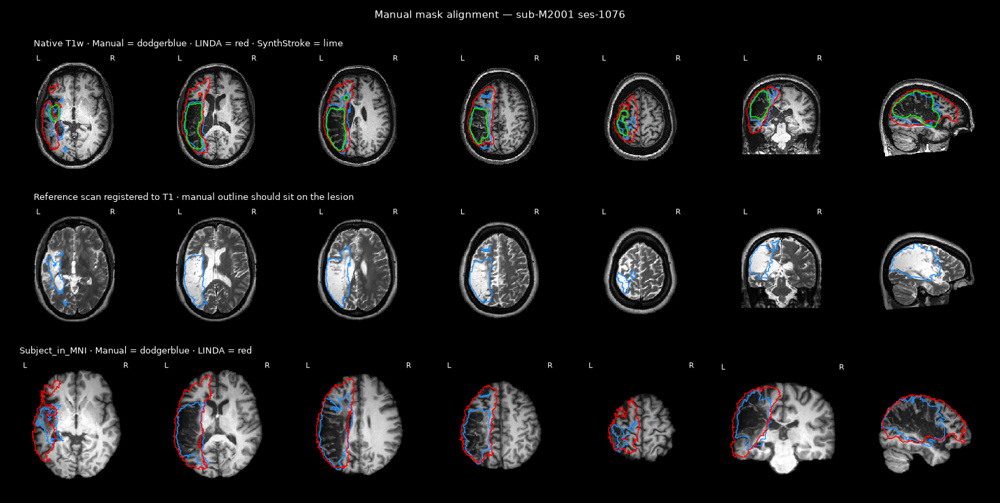
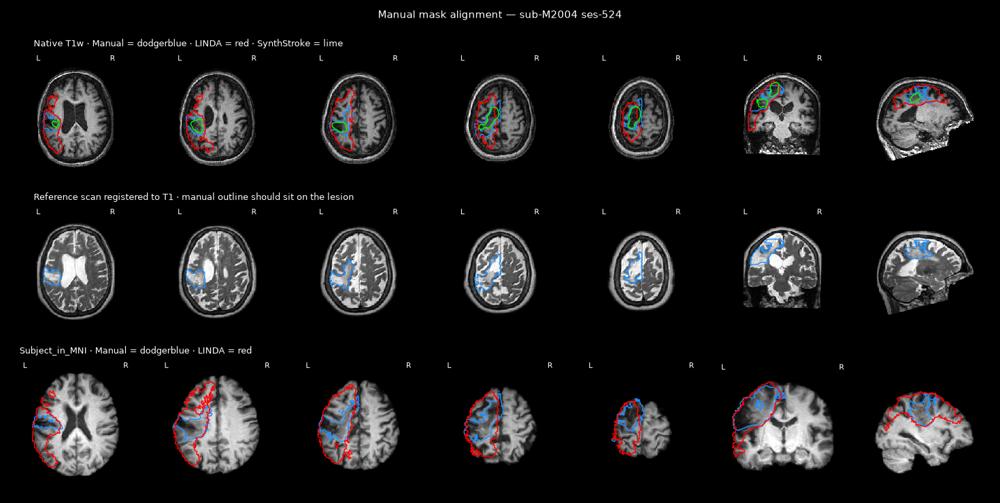
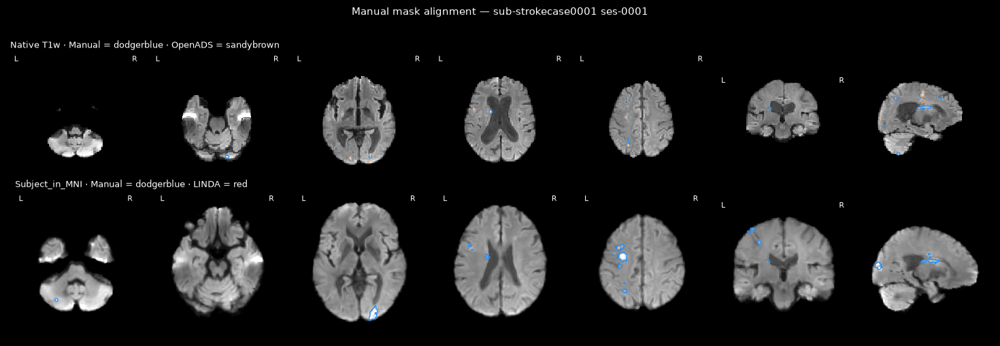
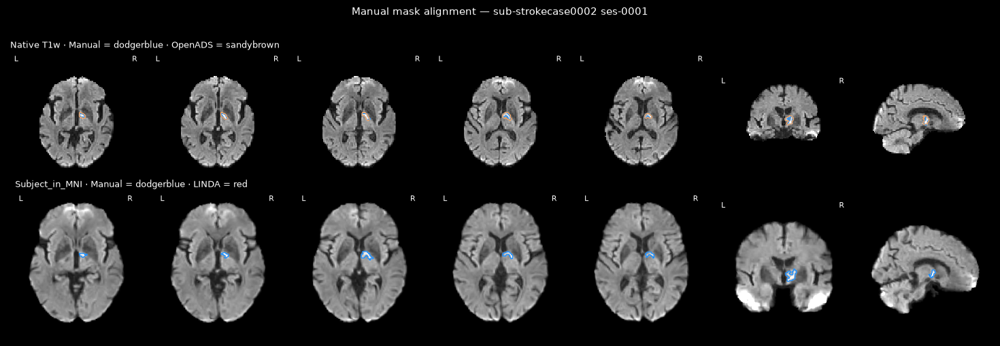

In [31]:
manual = submit_step("manual", SUBJECTS, study, timings=BATCH_TIMINGS)
show_step(manual, title="Manual mask registration and agreement — all participants")
# Native registration and template-space inspection share one tabbed view.
import ipywidgets as widgets
from calmar.study import stage_selected
from calmar.step_viewer import show_step_viewer
_manual_views = []
_native_view = show_step_viewer("manual", SUBJECTS, study, key="step_manual_batch", display_panel=False)
if _native_view is not None:
    _manual_views.append(("Native mask and reference scan", _native_view["panel"]))
_with_manual_mni = [entry for entry in SUBJECTS
                    if cm.present(study.template_dir(entry) / "ExpertMask_in_MNI.nii.gz")]
if (stage_selected("registration", globals().get("CONFIG", getattr(study, "config", {})))
        and _with_manual_mni):
    _mni_view = show_step_viewer("registration", _with_manual_mni, study, key="step_registration_manual", display_panel=False)
    if _mni_view is not None:
        _manual_views.append(("Template-space mask", _mni_view["panel"]))
if len(_manual_views) > 1:
    _manual_tabs = widgets.Tab(children=[panel for _, panel in _manual_views], selected_index=0)
    for _i, (_title, _) in enumerate(_manual_views): _manual_tabs.set_title(_i, _title)
    display(_manual_tabs)
elif _manual_views:
    display(_manual_views[0][1])

## Results and quality control

First review the processing outputs (QC, below), repair what QC flags, then run the batch disconnectomes and open the results preview. Optional group summaries are inside that preview.

## Quality control

**What it does.** One panel shows each participant's processing outputs, one stage at a time, and records your rating. Processing pauses here: later cells do not run until you choose **Do QC**, **Use existing QC** or **Skip QC**.

**Stages rated** (only those with outputs on disk are offered):

| Stage | Shown in the viewer | Question |
|---|---|---|
| Skull strip / brain extraction | Brain-extracted N4 T1 (or head + brain mask in yellow) | Is all brain kept and all skull/dura removed? |
| LINDA lesion mask | Native T1 + LINDA lesion outline (red) | Does the mask match the lesion? |
| SynthStroke lesion mask | Native T1 + SynthStroke outline (green) | Same question for SynthStroke |
| Manual mask → MNI warp | `Subject_in_MNI` + warped manual mask (blue), LINDA (red), optional SynthStroke (green) | Did registration keep the manual lesion in the right anatomy? |
| OpenADS lesion mask (native DWI) | Diffusion-weighted image + OpenADS outline (copper) | Does the mask cover the acute lesion (bright on DWI, dark on ADC)? |
| OpenADS lesion → MNI warp | OpenADS's warped DWI (`Subject_in_MNI`) + OpenADS lesion, optional manual mask | Did registration keep the lesion in the right anatomy? |

**Acute (DWI) route** (`CONFIG["MODALITY"] = "dwi"`): the two OpenADS stages replace the skull-strip, LINDA and SynthStroke stages (OpenADS's lesion is confined to its own DWI brain mask, so the brain mask is not rated); the manual-mask warp stage is offered when a manual mask exists. The ADC map is in the OpenADS step viewer and QC figure above. The only repair is **Re-run OpenADS** (Repair 4); for a lesion rated 3, choose the manual mask in the report.

The manual delineation itself is not rated; tick **Manual reference** above the viewer to overlay it on the native T1 as a reference.

**Rating scale** (the full rubric for the selected stage is shown under the viewer):
- **1 good** — usable as is.
- **2 acceptable** — minor problems (a few voxels of dura, a small false-positive cluster, slight boundary error); usable, or fixable with mask clean-up below.
- **3 poor** — not usable: missed brain or lesion, large false positives, wrong territory. A poor skull strip invalidates the lesion stages that depend on it.

Issue tags and notes describe *what* is wrong; **Mark participant for repair** puts the participant in the repair queues below (a skull-strip rating of 3 ticks it automatically).

**Where it is saved.** Ratings, tags, notes, reviewer, date and the repair flag go to `<linda_dir>/Lesion_in_MNI.qc.json` (written even when LINDA produced no mask; acute route: `<openads_dir>/OpenADS_in_MNI.qc.json`). Your Do/Skip/Use-existing choice is appended to `QC_decision.json` in the same folder. Participant reports state this choice (reviewed, existing QC reused, or skipped); the ratings themselves are in the sidecar and the QC summary. Unsaved clicks live only in the panel until it is rerun or the kernel restarts.

**Buttons.** Click 1/2/3 beside a stage to rate and view it. **Save stage →** saves that stage and opens the next; **Save & next participant** saves all stages and moves on. **Run skull-strip repair** (T1 route only) saves the skull-strip rating of a participant marked for repair and runs the repair cell below (Repair 1). **Continue after QC** runs the rest of the notebook.

**Suggested order for a reviewer:** for each participant rate the skull strip first (if it is 3, repair it before judging the lesions), then LINDA, SynthStroke and the MNI warp. Then work through the repair tools below in order — skull-strip repair, mask clean-up, external edit, re-run queue — rerun this panel to rate the repaired outputs, and finish with the QC summary.

In [32]:

# QC review panel. Pauses the notebook until you choose Do QC, Use existing QC or Skip QC.
# Display settings only; they do not change what is saved.
from calmar.qc_panel import QCDisplay, open_qc_review

LESION_OPACITY = 0.80              # lesion overlay opacity (0 = invisible, 1 = opaque)
LESION_AS_BOUNDARY = True          # draw only the lesion outline (cached next to the mask as *_boundary_tN.nii.gz)
LESION_BOUNDARY_THICKNESS = 1      # outline width in voxels (1 thin – 3 thick)
BRAIN_MASK_OPACITY = 0.30          # brain-mask overlay when the extracted brain cannot be shown
SKULL_STRIP_SHOW_EXTRACTED = True  # skull strip: show N4 T1 × brain mask, so leftover skull/dura is visible
MANUAL_OVERLAY_OPACITY = 0.50      # manual-mask overlay (native reference and MNI warp)

_qc_panel = open_qc_review(
    SUBJECTS, study,
    QCDisplay(lesion_opacity=LESION_OPACITY, lesion_as_boundary=LESION_AS_BOUNDARY,
              lesion_boundary_thickness=LESION_BOUNDARY_THICKNESS,
              brain_mask_opacity=BRAIN_MASK_OPACITY,
              skull_strip_show_extracted=SKULL_STRIP_SHOW_EXTRACTED,
              manual_overlay_opacity=MANUAL_OVERLAY_OPACITY),
    viewer=cw.fresh_viewer("qc_dashboard", height=400), encode_volumes=cw.vols)
assert get_ipython()._calmar_qc_checkpoint.choose("skipped")
print("DEMO: human QC skipped by request; no ratings or repair decisions fabricated.")

**If the buttons do not respond (‘Loading widget…’ or ‘Waiting…’):** insert a temporary code cell and run this command by itself:

```python
%calmar_continue skip-qc
```

This explicitly skips QC and saves ‘QC skipped by user’ for the reports. It does not start subsequent processing cells. To skip QC and open report selection directly, use `%calmar_continue skip-qc-to-report` instead.

QCPanel(children=(HTML(value='<b>⏸ QC decision required for the current cohort.</b> Choose <b>Do QC</b> to rev…

DEMO: human QC skipped by request; no ratings or repair decisions fabricated.


### Repair 1 — skull-strip repair (HD-BET again, then LINDA again)

**When to use it.** The skul
l strip was rated **3**, or it has an issue tag and the participant is marked for repair. A bad brain mask distorts LINDA's registration and lesion prediction, so repair it before fixing lesion masks. **Run skull-strip repair** in the QC panel runs this cell for the next queued participant.

**Lesion cavity left outside the mask** (tag `lesion_excluded_by_strip`): a dark, CSF-filled cavity in the lesion territory lies outside the brain-mask outline, and LINDA's red outline stops at the mask edge. With `REPAIR_BRAIN_MASK = "auto"` such a participant's repaired mask is HD-BET **OR SynthStrip** (brain + surrounding CSF), so LINDA can reach the cavity. On this dataset that raised LINDA's Dice for large cavities (~40 ml or more outside HD-BET: sub-M2045 0.73 → 0.77, sub-M2029 0.61 → 0.70) and lowered it for small ones, where LINDA also labelled the extra CSF next to the lesion. After the repair, check that the new red outline fills the cavity without spreading into the sulci.

**What it does** (as Slurm jobs; the notebook waits):
1. HD-BET runs again on the original T1, by default in `accurate` mode (5-model ensemble — slower, but keeps cerebellum and brainstem better than the `fast` mode of the first pass). With the union, SynthStrip's mask is added (SynthStrip runs first if step 1 did not run it).
2. LINDA runs again through the pipeline's LINDA step with that brain mask (its own skull stripping is skipped), with the same seed, single thread and MNI152 outputs as the first pass.

**What changes on disk.**
- HD-BET folder: `<T1>_desc-<mode>_brain.nii.gz`, `_brain_mask.nii.gz` and `_brain_mask.json` (the mask method used) are added.
- LINDA folder: recomputed; the folder as it was before the repair is kept as `<linda_dir>.previous.<id>`.
- `Lesion_in_MNI.qc.json`: the repair is logged (with the previous ratings), **all stage ratings are cleared** and the repair flag removed — the new images must be rated again.

`DRY_RUN = True` runs HD-BET (and SynthStrip if needed) only, so you can inspect the new brain mask; LINDA, ratings and the queue are unchanged.

**Check:** the brain mask shown after each repair covers the whole brain; a warning is printed if it is >15% smaller than the old one. Then rerun the QC panel and rate the participant again.

In [33]:

# Skull-strip repair: HD-BET again, then LINDA with the new brain mask (both in Slurm).
from calmar.qc_repair import run_skull_strip_repair

REPAIR_MODE = "step_marked"     # "step_marked": next queued participant (rerun for the next)
                                # "batch_marked": every queued participant; "single": REPAIR_SUBJECT_IDX
REPAIR_SUBJECT_IDX = 0          # position in SUBJECTS (0-based); used only by "single"
DRY_RUN = False                 # True = HD-BET only; LINDA, ratings and the queue are left unchanged
HDBET_REPAIR_MODE = "accurate"  # "accurate" (5-model ensemble, slower) or "fast"
HDBET_DEVICE = None             # None = GPU if the Slurm node has one, else CPU; or "cpu" / "0"
HDBET_TTA = False               # HD-BET test-time augmentation (dry run only; much slower)
REPAIR_BRAIN_MASK = "auto"      # "auto": HD-BET OR SynthStrip if the skull strip is tagged lesion_excluded_by_strip,
                                # else CONFIG["BRAIN_MASK"]; or force "hdbet" / "hdbet+synthstrip"
ONLY_SKULL_STRIP_ISSUES = True  # queue only participants whose skull strip is rated 3 or has an issue tag
REVIEWER = ""                   # name recorded in the edit log

repair_results = run_skull_strip_repair(
    SUBJECTS, study, CONFIG, mode=REPAIR_MODE, subject_index=REPAIR_SUBJECT_IDX,
    dry_run=DRY_RUN, hdbet_mode=HDBET_REPAIR_MODE, device=HDBET_DEVICE, tta=HDBET_TTA,
    brain_mask=REPAIR_BRAIN_MASK,
    only_skull_strip_issues=ONLY_SKULL_STRIP_ISSUES, reviewer=REVIEWER or None, viewers=cw)

Mode: step_marked · HD-BET accurate · brain mask auto · HD-BET + LINDA re-run
No skull-strip repairs are queued. In the QC panel, rate a skull strip 3 (or tag a skull-strip issue and mark the participant for repair), save, then click Run skull-strip repair.


### Repair 2–4 — fixing LINDA lesion masks

Use these after the skull strip is good, when the LINDA lesion was rated 2 or 3. All three work on LINDA's **native-space** lesion `<linda_dir>/Prediction3_native.nii.gz` (on the undistorted T1) and then re-warp it to `Lesion_in_MNI.nii.gz` with LINDA's transforms in a Slurm job (the notebook waits, typically a few minutes). Every later step — atlas overlap, disconnectomes, reports — uses the edited masks. SynthStroke and manual masks are not edited here.

Common to all three:
- **Backup.** The first edit copies LINDA's prediction to `<linda_dir>/_linda_original/Prediction3_native.nii.gz`. If LINDA was re-run since, the next edit first archives the older copy in `_linda_original/superseded/`, so edits start from the newest prediction. The MNI re-warp job also keeps the LINDA folder as it was as `<linda_dir>.previous.<jobid>`.
- **Audit trail.** Each operation is logged with its parameters, reviewer and time in `Prediction3_native.qc.json`; the re-warp in `Lesion_in_MNI.qc.json`.
- **Queue.** A successful edit removes the participant's repair flag. Ratings are kept — rerun the QC panel and rate the edited mask again.

**Repair 2 — mask clean-up (below).** Reproducible operations, applied in this order to LINDA's prediction: threshold → morphological opening (removes specks/thin bridges) → closing (fills small gaps) → fill holes → keep the N largest connected components → clip to one hemisphere. The preview shows LINDA's prediction and the cleaned mask with voxel counts kept/removed/added; nothing is saved until **Apply & save**. Settings always start from LINDA's prediction, not from a previous clean-up. **Revert to LINDA original** restores the prediction. Use for rating 2 problems: small false-positive clusters, holes, contralateral specks.

In [34]:
# Repair 2 — deterministic clean-up of LINDA's native lesion (re-warp to MNI runs in Slurm).
from calmar.qc_repair import MaskCleanupPanel

REVIEWER = ""   # name recorded with each saved edit

MaskCleanupPanel(SUBJECTS, study, cw.fresh_viewer("qc_edit_preview", height=300),
                 encode_volumes=cw.vols, reviewer=REVIEWER)

MaskCleanupPanel(children=(HBox(children=(Dropdown(description='Participant:', layout=Layout(width='340px'), o…

**Repair 3 — external editor (below).** For problems clean-up cannot fix (a missed part of the lesion, a false positive touching the lesion): paint the mask by hand.
1. Pick the participant and editor; the viewer shows the current native lesion.
2. **Export for editing** copies the native T1 and `Prediction3_native.nii.gz` to `qc_edits/<sub>_<ses>/` and shows a terminal command with a pinned module (e.g. `module load itksnap/4.4.0`). An earlier, different copy in that folder is kept as `*.replaced-<time>.nii.gz`.
3. Run the command in a terminal on the Neurodesktop, edit, and save over the exported lesion file.
4. **Import edited mask** refuses files whose grid (shape/affine) differs from LINDA's, replaces `Prediction3_native.nii.gz`, logs `external_edit` and re-warps to MNI.

In [35]:
# Repair 3 — edit LINDA's native lesion by hand in an external editor, then import it.
# Export copies the native T1 + lesion to QC_EDITS_DIR/<sub>_<ses>/ and shows the command to open
# them on the Neurodesktop. Import checks the grid matches, replaces Prediction3_native.nii.gz
# (LINDA's prediction kept in _linda_original/) and re-warps to MNI in Slurm.
from calmar.qc_repair import ExternalEditPanel

QC_EDITS_DIR = PROJECT_DIR / "qc_edits"   # working copies for the editor
EDITOR = "ITK-SNAP"                       # default editor: "ITK-SNAP", "FSLeyes" or "MRIcroGL"
REVIEWER = ""                             # name recorded with the import

ExternalEditPanel(SUBJECTS, study, cw.fresh_viewer("qc_export_preview", height=300),
                  edits_dir=QC_EDITS_DIR, encode_volumes=cw.vols, reviewer=REVIEWER, editor=EDITOR)

ExternalEditPanel(children=(HBox(children=(Dropdown(description='Participant:', layout=Layout(width='340px'), …

**Repair 4 — re-run queue (below).** Lists participants marked for repair and re-runs LINDA for one participant per click, with the best existing HD-BET brain mask (`accurate` before `fast`; HD-BET runs first if none exists) and LINDA's own skull stripping skipped. Use it when the lesion prediction failed but the skull strip is fine, or after a dry-run skull-strip repair. All LINDA outputs are regenerated (the previous folder is kept as `<linda_dir>.previous.<jobid>`); on success the repair flag is cleared and **all stage ratings are cleared**, since they described the old images.

A participant whose lesion was edited by hand (clean-up or external editor) after the last LINDA run is **blocked**, because a re-run would overwrite that work. *Revert to LINDA original* (Repair 2) unblocks it; `ALLOW_OVERWRITING_EDITS = True` overrides the block.

**Acute (DWI) route:** the button is **Re-run OpenADS**. It recomputes OpenADS and its warp to MNI152 (the previous folder is kept as `<openads_dir>.previous.<id>`), carries the QC edit log over, clears the stale ratings and the repair flag, and re-warps the manual mask when one is configured (its template-space copy lived in that folder). Repairs 1–3 edit LINDA's lesion and do nothing in this route.

In [36]:
# Repair 4 — re-run LINDA for participants marked for repair, using the best existing HD-BET mask
# (accurate > fast; HD-BET runs first if there is none). Runs in Slurm; the notebook waits.
from calmar.qc_repair import RerunQueuePanel

ALLOW_OVERWRITING_EDITS = False   # True = allow a re-run that discards manual edits made since the last LINDA run
REVIEWER = ""                     # name recorded in the edit log

RerunQueuePanel(SUBJECTS, study, CONFIG, allow_overwriting_edits=ALLOW_OVERWRITING_EDITS,
                reviewer=REVIEWER or None)

RerunQueuePanel(children=(HTML(value='<em>No participants are marked for repair.</em>'), Output()))

#### QC summary

Collects the saved QC of every participant in this run into one table and `qc_summary.csv` (in the LINDA derivatives folder): the rating of each stage, issue tags, whether the participant is still marked for repair, and how many edits are logged. The charts count ratings per stage and issue tags.

**Check:** no stage left unrated that you meant to review; participants still marked for repair or rated 3 have either been repaired (and re-rated) or will be excluded or caveated in reports.

In [37]:
# QC summary: one row per participant with the saved rating of each stage (1/2/3, blank = unrated,
# n/a = no output to rate), issue tags, repair flag and number of logged edits.
from calmar.qc_repair import show_qc_summary

QC_SUMMARY_CSV = DERIV_DIR / "qc_summary.csv"   # written on every run

qc_summary = show_qc_summary(SUBJECTS, study, QC_SUMMARY_CSV)

QC summary for 4 participant(s) written to /home/jovyan/neurodesktop-storage/calmar/data/ds004884/derivatives/linda/qc_summary.csv


,subject,session,skull_strip,lesion,synthstroke_lesion,manual_lesion,expert_mni_warp,openads_lesion,openads_mni_warp,issue_tags,marked_for_repair,n_edits,last_edit,reviewer,reviewed_on
0,sub-M2001,ses-1076,NaN,NaN,NaN,n/a,None,n/a,n/a,,False,1,warp_native_to_mni,,
1,sub-M2004,ses-524,NaN,NaN,NaN,n/a,None,n/a,n/a,,False,1,warp_native_to_mni,,
2,sub-strokecase0001,ses-0001,n/a,n/a,n/a,n/a,None,NaN,NaN,,False,0,,,
3,sub-strokecase0002,ses-0001,n/a,n/a,n/a,n/a,None,NaN,NaN,,False,0,,,


#### Reset QC ratings

Ratings persist in `<linda_dir>/Lesion_in_MNI.qc.json`, so restarting the kernel keeps them. Use this cell to clear them deliberately — one stage, one participant, or all participants of this run. It starts as a **dry run** that only lists the sidecars it would change; set `DRY_RUN = False` to apply.

With `KEEP_EDITS = True` the ratings, tags, notes, reviewer and repair flag are cleared and the reset is logged; the edit history stays. `KEEP_EDITS = False` (with `RESET_STAGE = None`) deletes the sidecar, history included. Masks and `QC_decision.json` are never changed.

In [38]:
# Reset saved QC ratings (dry run by default).
from calmar.qc_repair import reset_qc

RESET_SUBJECT = None   # e.g. "sub-M2040"; None = every participant in SUBJECTS
RESET_SESSION = None   # e.g. "ses-842"; None = every session
RESET_STAGE = None     # "skull_strip", "lesion", "synthstroke_lesion", "manual_lesion",
                       # "expert_mni_warp"; None = all stages + reviewer and repair flag
KEEP_EDITS = True      # False (with RESET_STAGE = None) deletes the sidecar, edit history included
DRY_RUN = True         # True = only list what would change

affected = reset_qc(SUBJECTS, study, subject=RESET_SUBJECT, session=RESET_SESSION,
                    stage=RESET_STAGE, keep_edits=KEEP_EDITS, dry_run=DRY_RUN)
print(("Would reset" if DRY_RUN else "Reset") + f" {len(affected)} sidecar(s):",
      *[f"  {path}" for path in affected], sep="\n")
if DRY_RUN and affected:
    print("Set DRY_RUN = False and rerun to apply.")

Would reset 2 sidecar(s):
  /home/jovyan/neurodesktop-storage/calmar/data/ds004884/derivatives/linda/sub-M2001/ses-1076/anat/Lesion_in_MNI.qc.json
  /home/jovyan/neurodesktop-storage/calmar/data/ds004884/derivatives/linda/sub-M2004/ses-524/anat/Lesion_in_MNI.qc.json
Set DRY_RUN = False and rerun to apply.


## Remaining optional acute DWI+ADC/OpenADS analysis and QC

The selected test participant was processed before the checkpoint. This step processes any remaining chosen DWI+ADC pairs with OpenADS in Slurm, then opens one QC review for all selected DWI entries. The DWI may come from another session; outputs remain under that DWI session and are registered and QC-reviewed independently. DWI signal evolves after stroke, so cross-session use does not assume unchanged diffusion contrast or identical lesion boundaries. If DWI was unavailable or declined, the notebook records that and continues.

In [39]:
if CONFIG.get("MODALITY", "t1") == "dwi":
    print("DWI is the primary route and its OpenADS outputs were already reviewed in the main QC step.")
elif not globals().get("DWI_SUBJECTS"):
    print("Acute DWI+ADC/OpenADS lesion segmentation was unavailable or not selected. The separate diffusion tract-microstructure route is handled below.")
else:
    from calmar.qc_panel import open_qc_review
    from calmar.single_subject import pending_optional_entries
    _dwi_pending = pending_optional_entries(
        DWI_SUBJECTS, globals().get("_SINGLE_OPTIONAL_COMPLETED", {}).get("dwi"),
        route="dwi", study=DWI_STUDY)
    if _dwi_pending:
        dwi_acquisition = submit_step("acquisition", _dwi_pending, DWI_STUDY, timings=BATCH_TIMINGS)
        show_step(dwi_acquisition, title="Selected DWI+ADC acquisition")
        dwi_openads = submit_step("openads", _dwi_pending, DWI_STUDY, timings=BATCH_TIMINGS)
        show_step(dwi_openads, DWI_STUDY, title="Optional OpenADS DWI analysis", viewer=False)
    else:
        print("All selected optional DWI entries completed in the single-subject test; opening their QC.")
    _dwi_qc_panel = open_qc_review(
        DWI_SUBJECTS, DWI_STUDY, viewer=cw.fresh_viewer("dwi_qc_dashboard", height=400),
        encode_volumes=cw.vols, continue_role="after-dwi-qc",
        continue_label="Continue after DWI QC",
        continue_prompt="Continue to disconnectomes and reports using the reviewed DWI outputs?")
    assert get_ipython()._calmar_qc_checkpoint.choose("skipped")
    print("DEMO: optional DWI human QC skipped by request.")

Acute DWI+ADC/OpenADS lesion segmentation was unavailable or not selected. The separate diffusion tract-microstructure route is handled below.


## Optional diffusion tract-microstructure analysis

This opt-in route is distinct from OpenADS and from the BCB/DeepDisco disconnectomes. The test participant is processed before the checkpoint and this cell processes only remaining selected entries. It accepts only 4-D diffusion series with valid b-values/b-vectors and at least 30 distinct diffusion directions. QSIPrep uses the configured native-T1 lesion mask during anatomical normalization. The selected reconstruction is either QSIRecon participant-specific bundles and tractometry or DIPY weighted-least-squares tensor maps (FA, MD, AD and RD); these are separate methods and are never combined. The validated DIPY path accepts a single nonzero shell; multi-shell sessions remain available for QSIRecon and are disabled for DIPY. Stroke-related oedema, cavitation, crossing fibres and tracking failure can alter both methods, so a missing bundle is **not** reported as proof of disconnection. Participant diffusion measurements appear in their own report section with their visual-QC status after the selected method's normalized metrics exist.

dmri_preproc: Slurm job 33 is already running this request; waiting for it.


dmri_preproc · sub-M2004 ses-780 · Slurm job 33 · submitted 0:00:00

dmri_preproc · sub-M2004 ses-780 · Slurm job 33 · running 0:00:00  

dmri_preproc · sub-M2004 ses-780 · Slurm job 33 · running 0:00:10

dmri_preproc · sub-M2004 ses-780 · Slurm job 33 · running 0:00:20

dmri_preproc · sub-M2004 ses-780 · Slurm job 33 · running 0:00:30

... (1,104 outputs left out)

dmri_metrics · sub-M2004 ses-780 · Slurm job 44 · queued 0:00:00   

dmri_metrics · sub-M2004 ses-780 · done in 0:00:10 (Slurm job 44)

Participant,Result,Key metrics,⚠ Workflow checks,Time
sub-M2004 ses-780,computed now,tracts: 76source_tables: 1,⚠ no opposite phase-encoding DWI; susceptibility correction is limited⚠ diffusion and anatomical lesion mask come from different sessions⚠ lesion-to-bundle overlap and valid-voxel coverage are not yet calculated⚠ patient-specific bundle absence is not evidence of anatomical disconnection,0 s


Review the selected-method preview and linked full reports before accepting participant diffusion measurements.



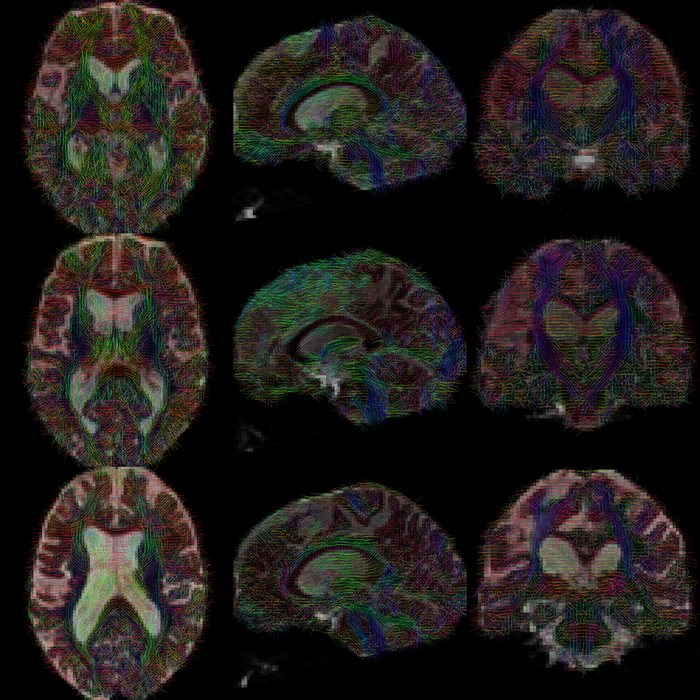

In [40]:
if not globals().get("DMRI_SUBJECTS"):
    print("Diffusion tract-microstructure analysis was unavailable or not selected; this is separate from OpenADS acute-lesion segmentation.")
else:
    from calmar.single_subject import pending_optional_entries
    _dmri_pending = pending_optional_entries(
        DMRI_SUBJECTS, globals().get("_SINGLE_OPTIONAL_COMPLETED", {}).get("dmri"),
        route="dmri", study=DMRI_STUDY)
    if not _dmri_pending:
        print("All selected diffusion tract-microstructure entries completed in the single-subject test.")
    else:
        try:
            dmri_preproc = submit_step("dmri_preproc", _dmri_pending, DMRI_STUDY, timings=BATCH_TIMINGS)
            show_step(dmri_preproc, title="Lesion-aware QSIPrep diffusion preprocessing", viewer=False)
            dmri_recon = submit_step("dmri_recon", _dmri_pending, DMRI_STUDY, timings=BATCH_TIMINGS)
            show_step(dmri_recon, title="Participant diffusion reconstruction", viewer=False)
            dmri_metrics = submit_step("dmri_metrics", _dmri_pending, DMRI_STUDY, timings=BATCH_TIMINGS)
            show_step(dmri_metrics, title="Diffusion metrics for participant reports", viewer=False)
            print("Review the selected-method preview and linked full reports before accepting participant diffusion measurements.")
        except Exception as exc:
            DMRI_ERROR = str(exc)
            print(f"Optional diffusion tract-microstructure analysis failed; standard disconnectomes and reports will continue. {exc}")
    from calmar.dmri_visualization import show_dmri_visuals
    _already_shown = globals().get("_SINGLE_DMRI_VISUALIZED", set())
    show_dmri_visuals(DMRI_SUBJECTS, DMRI_STUDY,
                      title="Diffusion visual review — selected participants",
                      already_shown=_already_shown)

## Optional background brain health

For selected entries, the test participant is processed before the checkpoint and this cell processes only the remainder. SynthSeg 8.2.1 measures descriptive T1 tissue and ventricular fractions. DeepWMH 1.0.1 segments FLAIR hyperintensity; ANTs registers the native stroke lesion to FLAIR, and the lesion plus `BRAIN_HEALTH_LESION_EXCLUSION_MM` is removed from the non-stroke WMH candidate burden. Acute infarct-related oedema can extend beyond this zone, chronic cavities can bias volumetry, and no age-adjusted atrophy or automated Fazekas diagnosis is inferred. Review every saved QC overlay before accepting these values in the report.


brain_health_anatomy · sub-M2004 ses-524 · Slurm job 45 · submitted 0:00:00

brain_health_anatomy · sub-M2004 ses-524 · Slurm job 45 · queued 0:00:00   

brain_health_anatomy · sub-M2004 ses-524 · Slurm job 45 · running 0:00:10

brain_health_anatomy · sub-M2004 ses-524 · Slurm job 45 · running 0:00:20

brain_health_anatomy · sub-M2004 ses-524 · Slurm job 45 · running 0:00:30

brain_health_anatomy · sub-M2004 ses-524 · Slurm job 45 · running 0:00:40

... (5 outputs left out)

brain_health_anatomy · sub-M2004 ses-524 · Slurm job 45 · running 0:01:41

brain_health_anatomy · sub-M2004 ses-524 · Slurm job 45 · running 0:01:51

brain_health_anatomy · sub-M2004 ses-524 · Slurm job 45 · running 0:02:01

brain_health_anatomy · sub-M2004 ses-524 · done in 0:02:11 (Slurm job 45)

Participant,Result,Key metrics,⚠ Workflow checks,Time
sub-M2004 ses-524,computed now,"intracranial_volume_ml: 1,390brain_tissue_volume_ml: 1,030brain_parenchymal_fraction: 0.741lesion_cavity_ml: 10.3lesion_adjusted_brain_parenchymal_fraction: 0.748lateral_ventricle_fraction: 0.046lesion_masked_lateral_ventricle_fraction: 0.0459lesion_ventricle_overlap_ml: 0.014left_lateral_ventricle_ml: 37.3right_lateral_ventricle_ml: 26.6",⚠ stroke lesion overlaps SynthSeg lateral-ventricle labels; raw ventricle volumes may reflect the cavity,116 s

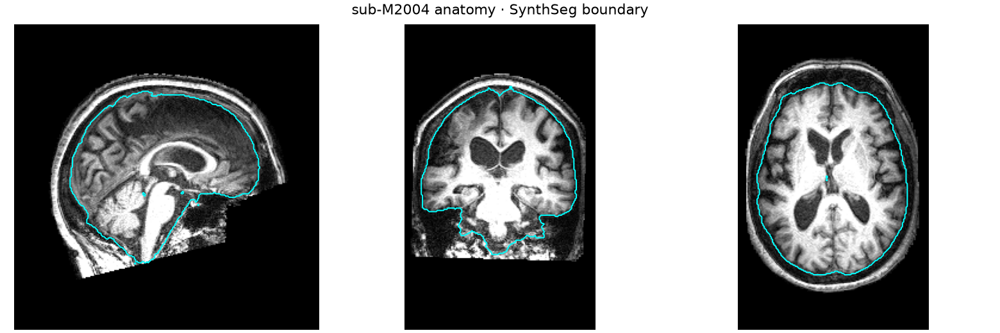

brain_health_wmh · 2 jobs · 2 submitted · 0:00:00

brain_health_wmh · 2 jobs · 2 queued · 0:00:00   

brain_health_wmh · 2 jobs · 2 running · 0:00:10

brain_health_wmh · 2 jobs · 2 running · 0:00:20

brain_health_wmh · 2 jobs · 2 running · 0:00:31

brain_health_wmh · 2 jobs · 2 running · 0:00:41

... (64 outputs left out)

brain_health_wmh · 2 jobs · 2 running · 0:11:54

brain_health_wmh · 2 jobs · 2 running · 0:12:04

brain_health_wmh · 2 jobs · 2 running · 0:12:15

brain_health_wmh · 2 jobs done in 0:12:25      

Participant,Result,Key metrics,⚠ Workflow checks,Time
sub-strokecase0001 ses-0001,computed now,—,—,733 s
sub-strokecase0002 ses-0001,computed now,—,—,731 s

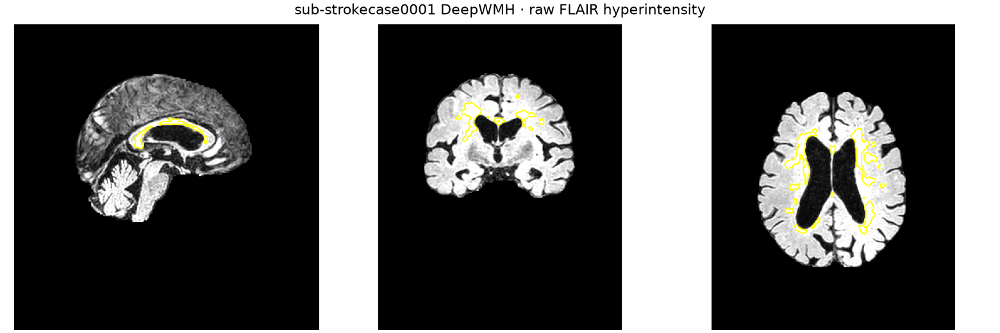
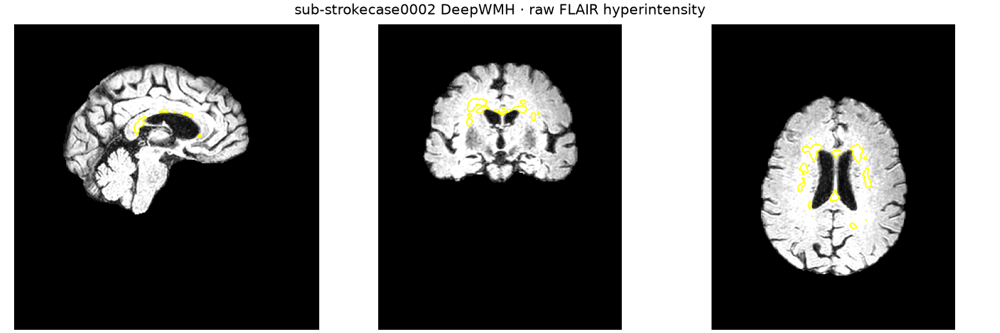

brain_health_metrics · 3 jobs · 3 submitted · 0:00:00

brain_health_metrics · 3 jobs · 3 queued · 0:00:00   

brain_health_metrics · 3 jobs · 1 done, 2 running · 0:00:10

brain_health_metrics · 3 jobs · 1 done, 2 running · 0:00:20

brain_health_metrics · 3 jobs · 1 done, 2 running · 0:00:30

brain_health_metrics · 3 jobs · 1 done, 2 running · 0:00:41

brain_health_metrics · 3 jobs done in 0:00:51              

Participant,Result,Key metrics,⚠ Workflow checks,Time
sub-M2004 ses-524,computed now,"intracranial_volume_ml: 1,390brain_tissue_volume_ml: 1,030brain_parenchymal_fraction: 0.741lesion_cavity_ml: 10.3lesion_adjusted_brain_parenchymal_fraction: 0.748lateral_ventricle_fraction: 0.046lesion_masked_lateral_ventricle_fraction: 0.0459lesion_ventricle_overlap_ml: 0.014left_lateral_ventricle_ml: 37.3right_lateral_ventricle_ml: 26.6",⚠ stroke lesion overlaps SynthSeg lateral-ventricle labels; raw ventricle volumes may reflect the cavity,2 s
sub-strokecase0001 ses-0001,computed now,total_flair_hyperintensity_ml: 25.6wmh_candidate_ml: 21.3stroke_excluded_hyperintensity_ml: 4.33wmh_fraction_icv: None,⚠ acute FLAIR: infarct-related oedema may extend beyond the exclusion zone,37 s
sub-strokecase0002 ses-0001,computed now,total_flair_hyperintensity_ml: 13.5wmh_candidate_ml: 13.5stroke_excluded_hyperintensity_ml: 0wmh_fraction_icv: None,⚠ acute FLAIR: infarct-related oedema may extend beyond the exclusion zone,37 s

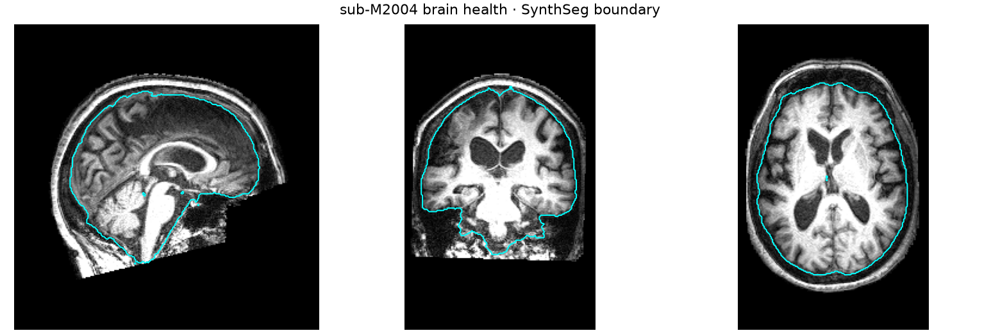
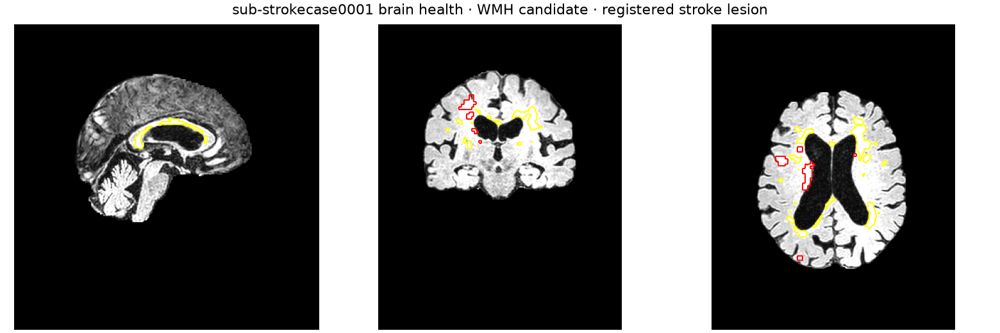
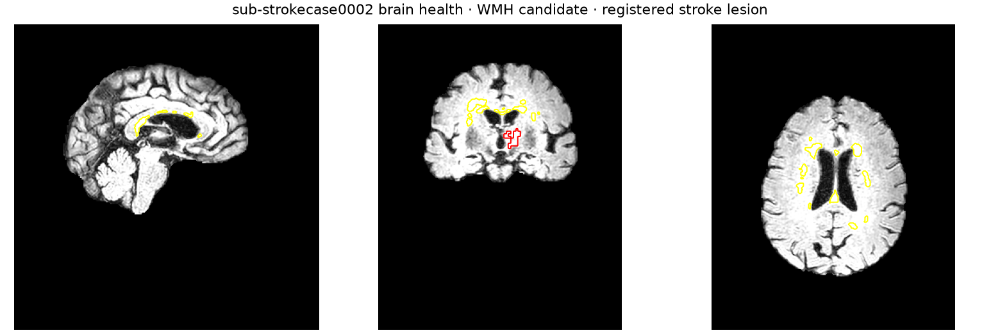

Review each brain_health_qc.png before treating these provisional features as interpretable.


In [41]:
if not globals().get("BRAIN_HEALTH_SUBJECTS"):
    print("Brain-health analysis unavailable or not selected.")
else:
    from calmar.single_subject import pending_optional_entries
    _brain_health_pending = pending_optional_entries(
        BRAIN_HEALTH_SUBJECTS, globals().get("_SINGLE_OPTIONAL_COMPLETED", {}).get("brain_health"),
        route="brain_health", study=study)
    if not _brain_health_pending:
        print("All selected brain-health entries completed in the single-subject test.")
    else:
        try:
            _bh_anatomy = [e for e in _brain_health_pending if "atrophy" in e["brain_health_components"]]
            _bh_wmh = [e for e in _brain_health_pending if "wmh" in e["brain_health_components"]]
            if _bh_anatomy:
                brain_health_anatomy = submit_step("brain_health_anatomy", _bh_anatomy, study, timings=BATCH_TIMINGS)
                show_step(brain_health_anatomy, title="Atrophy-sensitive T1 volumetry (SynthSeg)", viewer=False)
            if _bh_wmh:
                brain_health_wmh = submit_step("brain_health_wmh", _bh_wmh, study, timings=BATCH_TIMINGS)
                show_step(brain_health_wmh, title="Raw FLAIR hyperintensity segmentation (DeepWMH)", viewer=False)
            brain_health_metrics = submit_step("brain_health_metrics", _brain_health_pending, study, timings=BATCH_TIMINGS)
            show_step(brain_health_metrics, title="Stroke-aware brain-health features for reports", viewer=False)
            print("Review each brain_health_qc.png before treating these provisional features as interpretable.")
        except Exception as exc:
            BRAIN_HEALTH_ERROR = str(exc)
            print(f"Optional brain-health analysis failed; lesion and disconnectome reports will continue. {exc}")

## Disconnectomes (batch)

A disconnectome estimates which white-matter connections pass through the lesion: for each voxel, the probability that its tracts are disrupted. It is computed for **every available template-space mask** (LINDA, SynthStroke, manual; `BCB_MASKS`, `DEEPDISCO_MASK_SOURCE`). QC ratings do **not** filter this step. Use the ratings to choose which mask's results to interpret in the report. Existing maps are reused. When a method option changes they are reported as stale until recomputed with `BCB_OVERWRITE` or `DEEPDISCO_OVERWRITE`.

#### BCBToolkit disconnectome

Tractography-based (`bcbtoolkit/0.0.0`, 10 healthy-control tractograms on MNI152). About 8 minutes per mask. See the single-subject step for parameters and what to check.

bcb: using unchanged results for 1 participant(s).


bcb · 3 jobs · 3 submitted · 0:00:00

bcb · 3 jobs · 3 queued · 0:00:00   

bcb · 3 jobs · 3 running · 0:00:10

bcb · 3 jobs · 3 running · 0:00:20

bcb · 3 jobs · 3 running · 0:00:31

... (30 outputs left out)

bcb · 3 jobs · 1 running, 2 done · 0:05:48

bcb · 3 jobs · 1 running, 2 done · 0:05:58

bcb · 3 jobs · 1 running, 2 done · 0:06:08

bcb · 3 jobs done in 0:06:18              

Participant,Result,Key metrics,⚠ Workflow checks,Time
sub-M2001 ses-1076,reused — unchanged since Slurm job 22,"Map (LINDA lesion): 275,253 voxels above 0.5Map (SynthStroke lesion): 130,807 voxels above 0.5Map (Manual lesion): 252,364 voxels above 0.5",—,406 s
sub-M2004 ses-524,computed now,"Map (LINDA lesion): 190,367 voxels above 0.5Map (SynthStroke lesion): 77,713 voxels above 0.5Map (Manual lesion): 131,687 voxels above 0.5",—,369 s
sub-strokecase0001 ses-0001,computed now,"Map (OpenADS lesion): 37,389 voxels above 0.5Map (Manual lesion): 64,254 voxels above 0.5",—,236 s
sub-strokecase0002 ses-0001,computed now,"Map (OpenADS lesion): 18,478 voxels above 0.5Map (Manual lesion): 16,666 voxels above 0.5",—,235 s

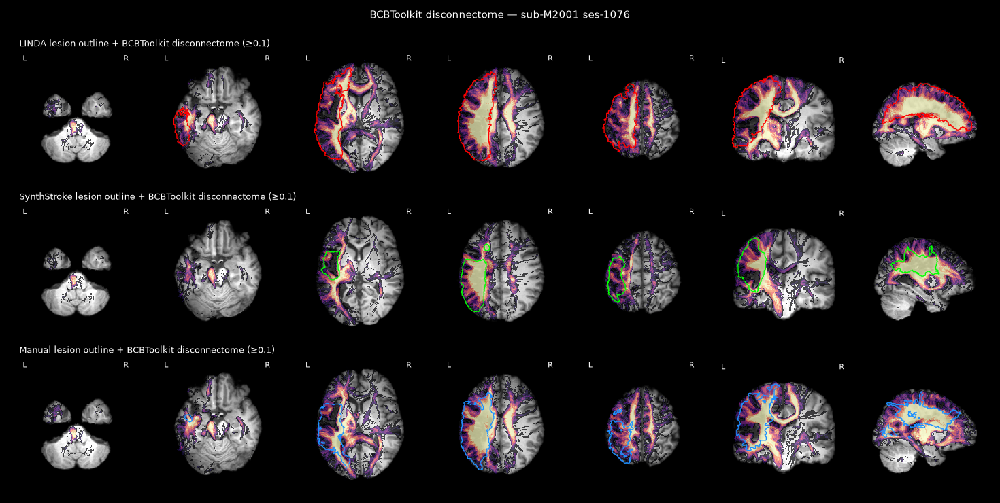
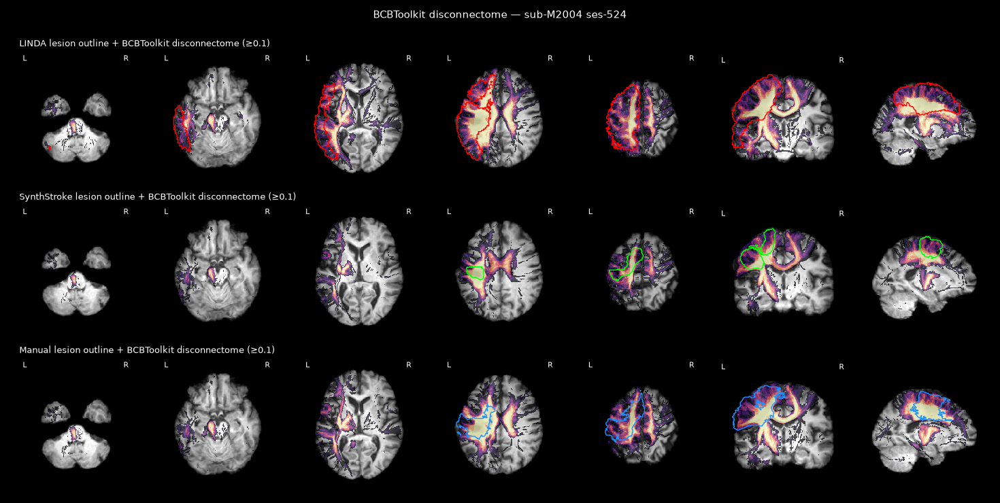
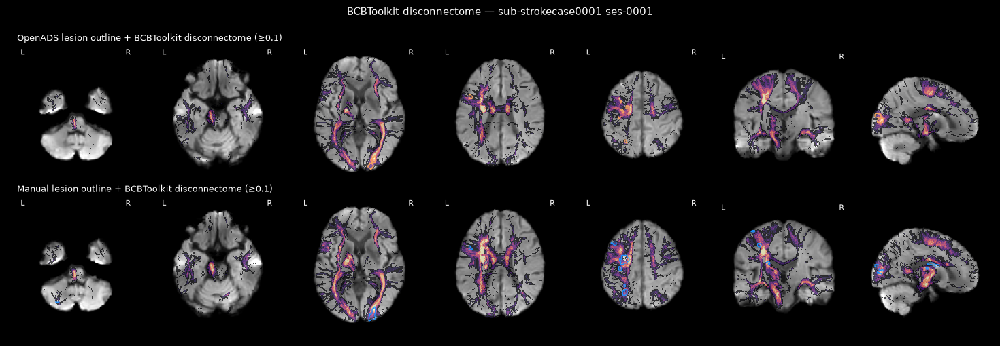
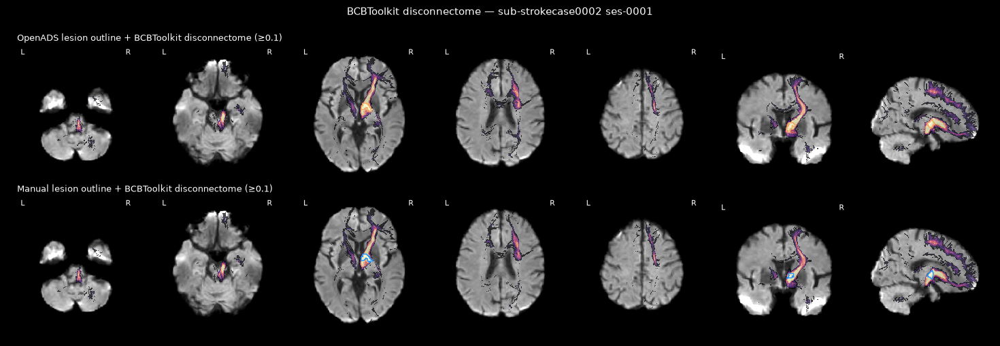

In [42]:
from calmar.scheduled import submit_step
from calmar.step_summary import show_step

bcb = submit_step("bcb", SUBJECTS, study, timings=BATCH_TIMINGS)
show_step(bcb, study, title="BCBToolkit disconnectome — all participants")

#### DeepDisco disconnectome

Deep-learning estimate (`deepdisco/20251008`), seconds per mask. The four fibre-class models (association, projection, commissural, whole brain) run when `DEEPDISCO_RUN_ALL`. The summary reports each map's correlation with BCBToolkit's.

deepdisco: using unchanged results for 1 participant(s).


deepdisco · 3 jobs · 3 submitted · 0:00:00

deepdisco · 3 jobs · 3 queued · 0:00:00   

deepdisco · 3 jobs · 3 running · 0:00:10

deepdisco · 3 jobs · 3 running · 0:00:20

deepdisco · 3 jobs · 3 running · 0:00:31

... (11 outputs left out)

deepdisco · 3 jobs · 1 running, 2 done · 0:02:34

deepdisco · 3 jobs · 1 running, 2 done · 0:02:44

deepdisco · 3 jobs · 1 running, 2 done · 0:02:54

deepdisco · 3 jobs done in 0:03:04              

Participant,Result,Key metrics,⚠ Workflow checks,Time
sub-M2001 ses-1076,reused — unchanged since Slurm job 23,"Map (LINDA lesion): 518,012 voxels above 0.5, r = 0.84 with BCBToolkitMap (SynthStroke lesion): 288,068 voxels above 0.5, r = 0.77 with BCBToolkitMap (Manual lesion): 476,427 voxels above 0.5, r = 0.83 with BCBToolkit",—,175 s
sub-M2004 ses-524,computed now,"Map (LINDA lesion): 386,745 voxels above 0.5, r = 0.81 with BCBToolkitMap (SynthStroke lesion): 155,701 voxels above 0.5, r = 0.78 with BCBToolkitMap (Manual lesion): 251,568 voxels above 0.5, r = 0.81 with BCBToolkit",—,169 s
sub-strokecase0001 ses-0001,computed now,"Map (OpenADS lesion): 98,400 voxels above 0.5, r = 0.60 with BCBToolkitMap (Manual lesion): 175,143 voxels above 0.5, r = 0.67 with BCBToolkit",—,114 s
sub-strokecase0002 ses-0001,computed now,"Map (OpenADS lesion): 36,517 voxels above 0.5, r = 0.70 with BCBToolkitMap (Manual lesion): 30,958 voxels above 0.5, r = 0.69 with BCBToolkit",—,114 s

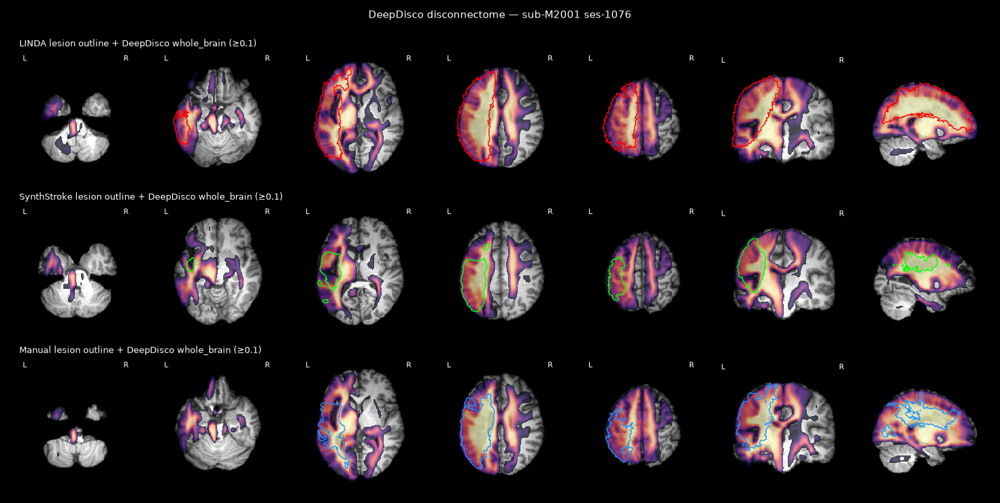
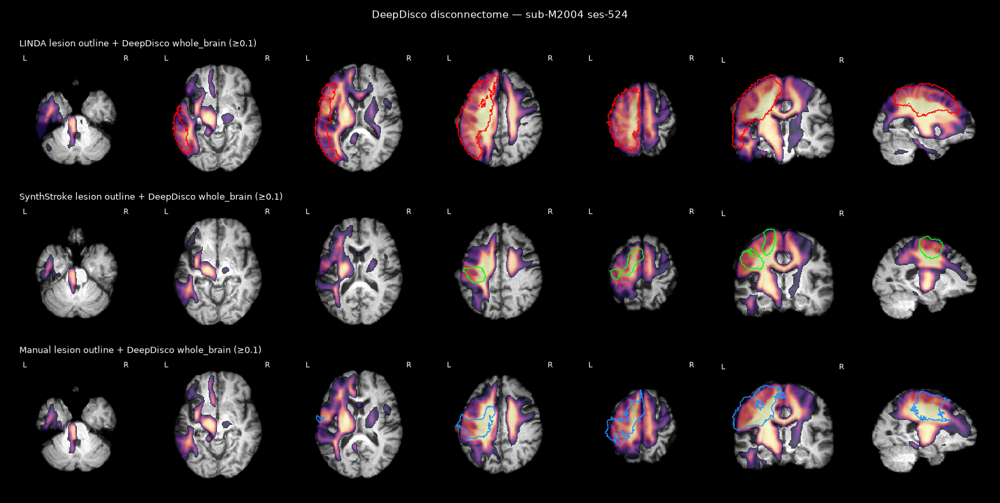
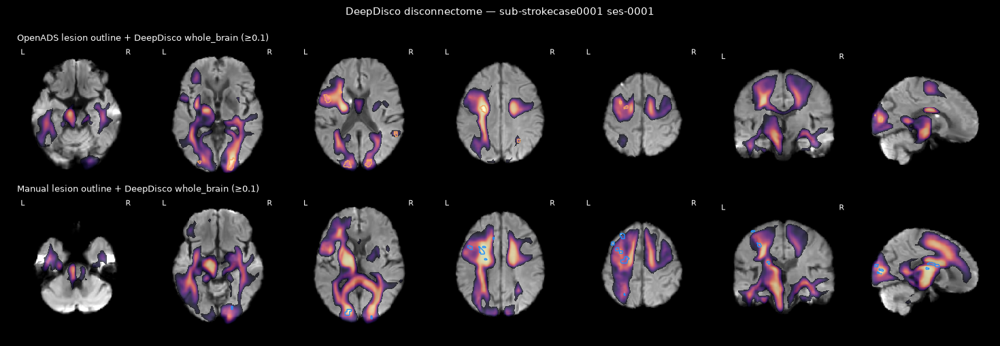
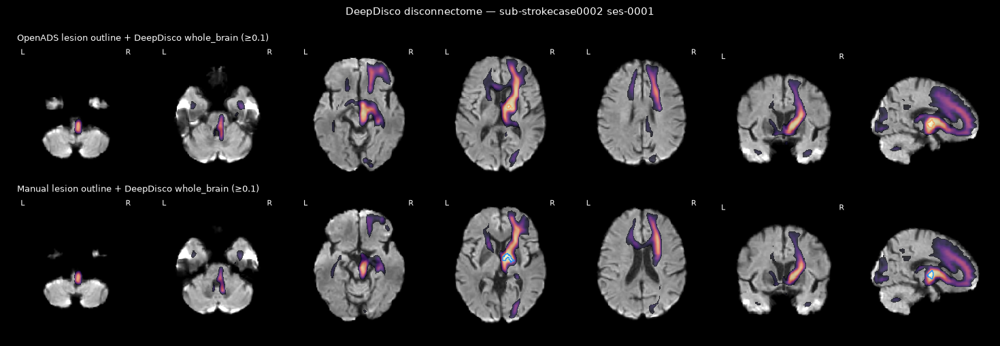

In [43]:
deepdisco = submit_step("deepdisco", SUBJECTS, study, timings=BATCH_TIMINGS)
show_step(deepdisco, study, title="DeepDisco disconnectome — all participants")

## Atlas results

**What this section does.** It measures, for each participant and lesion mask, how much of the lesion falls inside each region of the configured atlases (HarvardOxford, AAL, Destrieux, Schaefer400, JHU), then lets you browse and export those tables.

**How the numbers are computed** (one row per participant × region; the MNI-space mask is resampled onto the atlas grid with nearest-neighbour interpolation and binarised at `> CONFIG["LESION_THRESHOLD"]`):
- `overlap_voxels` = voxels that are both lesion and ROI.
- `lesion_in_roi_percent` = % of the lesion's voxels inside the ROI (`overlap_voxels / total_lesion_voxels × 100`). The columns of one participant sum to ≤ 100 %; the remainder lies outside every labelled ROI (e.g. white matter for cortical atlases).
- `roi_coverage_percent` = % of the ROI's voxels covered by lesion.
- *Lesion side* is counted from the lesion voxels themselves (left/right of MNI x = 0), never inferred from the ROI name.

**Template space.** Lesion masks are on FSL MNI152 (MNI152NLin6Asym; see step 2), the space the Harvard-Oxford and JHU atlases were built in. Schaefer and Destrieux are distributed in MNI152 space by nilearn and AAL in SPM's MNI space; all are resampled to the lesion by world coordinates. The remaining uncertainty is registration accuracy (individual brain → MNI152), which matters most for small or thin regions.

**What to check.** The total lesion size is plausible for the mask you QC'd; the top regions agree with where the lesion sits in the brain view; a participant with no rows really has no lesion (and is not simply missing a mask).

In [44]:
# Compute lesion–atlas overlap tables in Slurm (one job; cached results are reused).
# Output: OVERLAP_DFS = {"<atlas>_<source>": table}, also saved as CSV under reports/.
from calmar.reporting import overlap_tables

OVERLAP_MASK_SOURCE = "all"   # "all", or one of "linda", "synthstroke", "openads", "manual"

# "all": selected T1 segmentations, optional OpenADS when chosen, and the manual mask.
from calmar.study import analysis_mask_sources, config_for_entry
_sources = (sorted({source for entry in SUBJECTS
                    for source in analysis_mask_sources(config_for_entry(CONFIG, entry))})
            if OVERLAP_MASK_SOURCE == "all" else [OVERLAP_MASK_SOURCE])
# overlap_tables reads ALL_ATLASES, _mask_path_for, CONFIG and PROJECT_DIR from the namespace.
OVERLAP_DFS = overlap_tables(globals(), SUBJECTS, _sources)
print("Atlas tables ready:", list(OVERLAP_DFS))

reporting · sub-M2001 ses-1076, sub-M2004 ses-524, sub-strokecase0001 ses-0001, sub-strokecase0002 ses-0001 · Slurm job 57 · submitted 0:00:00

reporting · sub-M2001 ses-1076, sub-M2004 ses-524, sub-strokecase0001 ses-0001, sub-strokecase0002 ses-0001 · Slurm job 57 · queued 0:00:00   

reporting · sub-M2001 ses-1076, sub-M2004 ses-524, sub-strokecase0001 ses-0001, sub-strokecase0002 ses-0001 · Slurm job 57 · running 0:00:10

reporting · sub-M2001 ses-1076, sub-M2004 ses-524, sub-strokecase0001 ses-0001, sub-strokecase0002 ses-0001 · Slurm job 57 · running 0:00:20

reporting · sub-M2001 ses-1076, sub-M2004 ses-524, sub-strokecase0001 ses-0001, sub-strokecase0002 ses-0001 · Slurm job 57 · running 0:00:30

reporting · sub-M2001 ses-1076, sub-M2004 ses-524, sub-strokecase0001 ses-0001, sub-strokecase0002 ses-0001 · done in 0:00:40 (Slurm job 57)

Atlas tables ready: ['HarvardOxford_linda', 'HarvardOxford_manual', 'HarvardOxford_openads', 'HarvardOxford_synthstroke', 'AAL_linda', 'AAL_manual', 'AAL_openads', 'AAL_synthstroke', 'Destrieux_linda', 'Destrieux_manual', 'Destrieux_openads', 'Destrieux_synthstroke', 'Schaefer400_linda', 'Schaefer400_manual', 'Schaefer400_openads', 'Schaefer400_synthstroke', 'JHU_linda', 'JHU_manual', 'JHU_openads', 'JHU_synthstroke', 'XTRACT_linda', 'XTRACT_manual', 'XTRACT_openads', 'XTRACT_synthstroke']


In [45]:
# Preview the atlas tables: one selector (participant, atlas, mask) drives the table,
# brain view and region chart. Group summaries are computed only when opened.
from calmar.atlas_results import build_results_panel

RESULTS_DEFAULT_ATLAS = CONFIG.get("DEFAULT_ATLAS")   # atlas shown first

_subject_report_panel = build_results_panel(
    OVERLAP_DFS, SUBJECTS, RESULTS_DEFAULT_ATLAS, ALL_ATLASES, cw,
    deriv_path_for=study.qc_dir, template_path_for=study.template_dir, inventory_for=study.masks,
    deriv_dir=DERIV_DIR, atlas_dir=ATLAS_DIR, reports_dir=REPORTS_DIR,
    threshold=CONFIG["LESION_THRESHOLD"],
    previous=globals().get("_subject_report_panel"))   # closes the panel from an earlier run
if _subject_report_panel is None:
    print("No atlas-overlap tables available. Run the atlas-overlap calculation first.")
else:
    display(_subject_report_panel["widget"])

In [46]:
# Add "Export selected atlas PDF" to the preview above. The PDF holds the participant,
# atlas and mask currently selected there: a summary page (lesion size, QC checkpoint
# status, top-20 bar chart of lesion_in_roi_percent) and the full region table.
from calmar.atlas_pdf import attach_pdf_export

ATLAS_PDF_DIR = REPORTS_DIR / "pdfs"   # where exported PDFs are written

attach_pdf_export(_subject_report_panel, ATLAS_PDF_DIR, atlas_dir=ATLAS_DIR, deriv_path_for=study.qc_dir)
from calmar.atlas_pdf import write_atlas_pdf
from calmar.qc_decisions import report_qc_text
DEMO_ATLAS_PDFS = []
for _table_key, _table in OVERLAP_DFS.items():
    _atlas, _source = _table_key.rsplit('_', 1)
    for _entry in SUBJECTS:
        _pdf = write_atlas_pdf(_entry['subject'], _entry.get('session'), _table,
            _atlas, _source, pdf_dir=ATLAS_PDF_DIR, atlas_dir=ATLAS_DIR,
            qc_text=report_qc_text(study.qc_dir(_entry), _entry))
        if _pdf is not None:
            DEMO_ATLAS_PDFS.append(str(_pdf))
print('Saved atlas PDFs:', len(DEMO_ATLAS_PDFS))


  ✓ /home/jovyan/neurodesktop-storage/calmar/reports/unattended-demo/pdfs/sub-M2001_ses-1076_HarvardOxford_linda.pdf


  ✓ /home/jovyan/neurodesktop-storage/calmar/reports/unattended-demo/pdfs/sub-M2004_ses-524_HarvardOxford_linda.pdf
  no data for sub-strokecase0001 ses-0001 (HarvardOxford)
  no data for sub-strokecase0002 ses-0001 (HarvardOxford)


  ✓ /home/jovyan/neurodesktop-storage/calmar/reports/unattended-demo/pdfs/sub-M2001_ses-1076_HarvardOxford_manual.pdf


  ✓ /home/jovyan/neurodesktop-storage/calmar/reports/unattended-demo/pdfs/sub-M2004_ses-524_HarvardOxford_manual.pdf


  ✓ /home/jovyan/neurodesktop-storage/calmar/reports/unattended-demo/pdfs/sub-strokecase0001_ses-0001_HarvardOxford_manual.pdf
  no data for sub-strokecase0002 ses-0001 (HarvardOxford)
  no data for sub-M2001 ses-1076 (HarvardOxford)
  no data for sub-M2004 ses-524 (HarvardOxford)


  ✓ /home/jovyan/neurodesktop-storage/calmar/reports/unattended-demo/pdfs/sub-strokecase0001_ses-0001_HarvardOxford_openads.pdf
  no data for sub-strokecase0002 ses-0001 (HarvardOxford)


... (31 outputs left out)

  ✓ /home/jovyan/neurodesktop-storage/calmar/reports/unattended-demo/pdfs/sub-M2001_ses-1076_XTRACT_manual.pdf
  ✓ /home/jovyan/neurodesktop-storage/calmar/reports/unattended-demo/pdfs/sub-M2004_ses-524_XTRACT_manual.pdf


  ✓ /home/jovyan/neurodesktop-storage/calmar/reports/unattended-demo/pdfs/sub-strokecase0001_ses-0001_XTRACT_manual.pdf
  ✓ /home/jovyan/neurodesktop-storage/calmar/reports/unattended-demo/pdfs/sub-strokecase0002_ses-0001_XTRACT_manual.pdf
  no data for sub-M2001 ses-1076 (XTRACT)
  no data for sub-M2004 ses-524 (XTRACT)


  ✓ /home/jovyan/neurodesktop-storage/calmar/reports/unattended-demo/pdfs/sub-strokecase0001_ses-0001_XTRACT_openads.pdf
  ✓ /home/jovyan/neurodesktop-storage/calmar/reports/unattended-demo/pdfs/sub-strokecase0002_ses-0001_XTRACT_openads.pdf


  ✓ /home/jovyan/neurodesktop-storage/calmar/reports/unattended-demo/pdfs/sub-M2001_ses-1076_XTRACT_synthstroke.pdf
  ✓ /home/jovyan/neurodesktop-storage/calmar/reports/unattended-demo/pdfs/sub-M2004_ses-524_XTRACT_synthstroke.pdf
  no data for sub-strokecase0001 ses-0001 (XTRACT)
  no data for sub-strokecase0002 ses-0001 (XTRACT)
Saved atlas PDFs: 52


## Participant interpretation report

**What it does.** For one participant and one MNI-space lesion mask, the report combines the atlas overlap with the aphasia knowledge base (`stroke-aphasia-kb/`) and the participant's clinical data (`participants.tsv`). It is saved as `reports/interpretation_<sub>_<ses>_<mask>.html` (print it to PDF from the browser).

**Report sections and how they are computed**
- *Provenance and caveats* — research use only / not a diagnosis; which mask was used and its QC rating (from the `*.qc.json` sidecar); method agreement as Dice between all available MNI masks (2·|A∩B| / (|A|+|B|), 1 = identical); the template-space caveat.
- *Damaged regions* — display-atlas ROIs holding ≥ `INTERP_MIN_OVERLAP_PCT` % of the lesion (`lesion_in_roi_percent`) **or** with ≥ `INTERP_MIN_REGION_PCT` % of the ROI lesioned (`roi_coverage_percent`) — the same rule the KB interpretation uses; sorted by share of the lesion, at most `INTERP_MAX_ROIS` rows.
- *Behavioural / clinical data* — WAB-AQ, WAB type (annotated with its fluency/comprehension/repetition profile), age, sex, days to WAB, lesion volume (mL).
- *Participant measures: what the evidence says* — group findings associated with WAB-AQ, age, days post-onset, sex and lesion volume; these are not participant-level predictions.
- *Lesion location: what the evidence says* — symptom-level KB findings matched through damaged regions. Aphasia diagnoses and subtype labels are excluded. The primary list requires the configured minimum numbers of citation keys and distinct anatomy mappings after KB synonyms are merged; all relationship types, including null and mixed findings, count. The remaining symptom summaries stay expandable.
- *White-matter disconnection* — direction counts for findings linked to each disconnected tract, with cross-references when the same symptom target has direct-damage evidence from a different anatomy. Each cross-reference shows the direction mix on both paths; the paths are not treated as independent or additive evidence.
- *Therapy recommendations* — KB therapies targeting the predicted impairments, gated by impairments implied by the WAB type; ⚠ marks therapies whose evidence comes from a different recovery stage.

**Fixed rules** (WAB type profile, recovery stage cut-offs, evidence-strength stars) are printed as tables under the settings cell and defined, with their sources, in `stroke-aphasia-kb/scripts/aphasia_rules.py`. The WAB profile follows the WAB/WAB-R taxonomy; the 14-day acute/subacute boundary is **not sourced** (the stroke-recovery consensus uses 7 days), and the star bins are a project heuristic.

**What to check.** The mask named in the provenance block is the one you QC'd (and is not rated *poor*); Dice between methods — low agreement means the lesion extent itself is uncertain; damaged regions match the brain view; the WAB type and days post-onset match the source data. Treat predictions as literature associations, not individual diagnoses.

In [47]:
# Settings for the participant interpretation report.
# The form below sets participant, mask, display atlas and decoding; edit the rest here.
from calmar.participant_report import rules_html

INTERP_SUBJECT_IDX = TEST_SUBJECT_IDX       # participant first shown in the form (index into SUBJECTS)
INTERP_MASK_SOURCE = "synthstroke"           # preferred lesion mask: "linda", "synthstroke" or "manual"
INTERP_DISPLAY_ATLAS = "HarvardOxford"       # atlas of the damaged-regions table
INTERP_RUN_DECODING = False                  # also run optional Neurosynth decoding (slower)
INTERP_KB_ATLASES = ["AAL", "HarvardOxford", "Destrieux", "Schaefer400", "JHU", "XTRACT"]  # atlases used to query the KB
INTERP_HIGH_CONF_ONLY = False                # keep only KB findings with confidence "high"
INTERP_EVIDENCE = "all"                      # KB evidence used (also in the form): "approved" entries only,
                                             # "in_review" (approved + in review) or "all" (+ unreviewed drafts)
INTERP_MIN_OVERLAP_PCT = 5.0                 # an ROI counts as damaged if it holds >= this % of the lesion
INTERP_MIN_REGION_PCT = 25.0                 # ... or if >= this % of the ROI is destroyed (small regions, thin tracts)
INTERP_DISCONNECTOME = "bcb"                 # tract disconnection from the "bcb" (BCBToolkit) or "deepdisco" map, or "none"
INTERP_MIN_DISCONNECTED_PCT = 50.0           # a tract counts as disconnected if >= this % of it has probability > 0.5
INTERP_TOP_N = 5                             # rows per predictor / therapy table (not the symptom relevance rule)
INTERP_MAX_ROIS = 15                         # rows in the damaged-regions table
INTERP_MAX_EVIDENCE_REGIONS = 8              # main damaged-ROI evidence blocks before the additional-region fold
INTERP_MIN_SUMMARY_CITATIONS = 2             # primary symptom summary: at least this many citation keys
INTERP_MIN_SUMMARY_ANATOMIES = 2             # ... and this many anatomy mappings after KB synonyms are merged
from calmar.kb_location import kb_selection_text, resolve_kb_root
APHASIA_KB_ROOT, APHASIA_KB_REASON = resolve_kb_root(PROJECT_DIR)
print(kb_selection_text(APHASIA_KB_ROOT, APHASIA_KB_REASON))

# The fixed clinical/display rules the report applies (sources in stroke-aphasia-kb/scripts/aphasia_rules.py).
display(HTML(rules_html(APHASIA_KB_ROOT)))
from dataclasses import fields
from calmar.participant_report import ReportSettings
_demo_report_defaults = ReportSettings()
for _field in fields(_demo_report_defaults):
    globals().setdefault('INTERP_' + _field.name.upper(), getattr(_demo_report_defaults, _field.name))


Knowledge base: /home/jovyan/neurodesktop-storage/calmar/stroke-aphasia-kb (CALMaR submodule); git a02628430286e71eec3a503a9f84fed5c5663321 (2026-11-12); clean working tree; HEAD is not contained in last-fetched origin/main; latest not verified (Knowledge-base update disabled by CALMAR_KB_UPDATE=off.).


### Choose report inputs

Use the form below—no code editing is needed. The mask menu lists only masks that exist in MNI space for the chosen participant; the optional *Compare available MNI masks* view overlays them so you can see where the methods disagree before choosing one. **Generate participant report** stores the choice (`INTERP_SUBJECT_IDX`, `INTERP_MASK_SOURCE`, `INTERP_DISPLAY_ATLAS`, `INTERP_RUN_DECODING`) and runs the report cells automatically.

**What to check.** The mask you pick is the one that passed QC for this participant.

In [48]:
# Choose participant, mask, display atlas and decoding, then click Generate participant report.
# The form writes INTERP_SUBJECT_IDX / INTERP_MASK_SOURCE / INTERP_DISPLAY_ATLAS /
# INTERP_RUN_DECODING into the notebook namespace (show_report_inputs needs globals() for that).
from calmar.report_ui import show_report_inputs

_report_inputs = show_report_inputs(globals())
_rp_subj, _rp_mask = _report_inputs.subject, _report_inputs.source
_report_inputs.choose_participant(SUBJECTS[INTERP_SUBJECT_IDX]["subject"])
_report_inputs.choose_mask("openads" if config_for_entry(CONFIG, SUBJECTS[INTERP_SUBJECT_IDX])["MODALITY"] == "dwi" else "synthstroke")
assert _report_inputs.approve(), _report_inputs.message.value
print("Demo: report form approved using its displayed defaults.")

**If the buttons do not respond (‘Loading widget…’ or ‘Waiting…’):** insert a temporary code cell and run this command by itself:

```python
%calmar_continue generate
```

This does what **Generate participant report** does, with the form's current choices. To choose without the form, add the participant and the mask, e.g. `%calmar_continue generate sub-01 manual`. Then run the report cell below (Shift+Enter).

Demo: report form approved using its displayed defaults.


### Generated participant report

The next cell builds the report for the selection above (atlas tables and the static lesion overlay are prepared in Slurm) and shows one panel: report sections (starting with *Provenance and caveats*), a brain viewer that loads when its tab is opened and, if requested, Neurosynth decoding. The saved HTML contains the QC checkpoint notice, the provenance block and a static overlay image.

**What to check.** Open *Generation details* for the KB summary (a KB with 0 regions means the KB folder is wrong) and the number of KB findings per atlas; confirm the brain viewer shows the lesion where the damaged-regions table says it is.

reporting · sub-M2001 ses-1076 · Slurm job 58 · submitted 0:00:00

reporting · sub-M2001 ses-1076 · Slurm job 58 · queued 0:00:00   

reporting · sub-M2001 ses-1076 · done in 0:00:10 (Slurm job 58)

reporting · reporting · Slurm job 59 · submitted 0:00:00

reporting · reporting · Slurm job 59 · queued 0:00:00   

reporting · reporting · done in 0:00:10 (Slurm job 59)


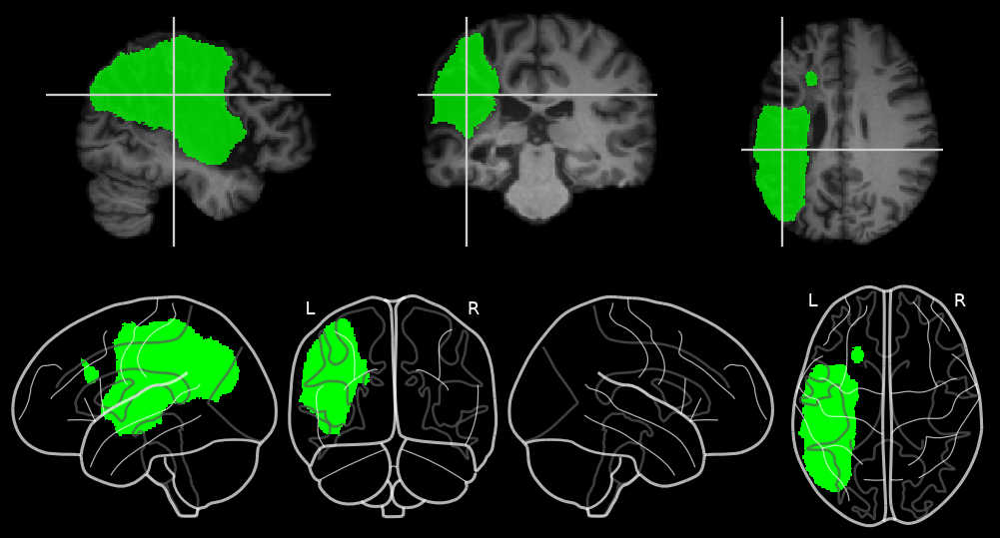

Saved participant report: /home/jovyan/neurodesktop-storage/calmar/reports/unattended-demo/interpretation_sub-M2001_ses-1076_synthstroke.html


In [49]:
# Generate the interpretation report for the participant and mask chosen in the form.
from calmar.participant_report import ReportSettings, generate_participant_report, selected_entry

REPORT_SETTINGS = ReportSettings(
    kb_atlases=tuple(INTERP_KB_ATLASES), display_atlas=INTERP_DISPLAY_ATLAS,
    high_conf_only=INTERP_HIGH_CONF_ONLY, evidence=INTERP_EVIDENCE,
    min_overlap_pct=INTERP_MIN_OVERLAP_PCT, min_region_pct=INTERP_MIN_REGION_PCT,
    disconnectome=INTERP_DISCONNECTOME, min_disconnected_pct=INTERP_MIN_DISCONNECTED_PCT, top_n=INTERP_TOP_N,
    max_rois=INTERP_MAX_ROIS, max_evidence_regions=INTERP_MAX_EVIDENCE_REGIONS,
    min_summary_citations=INTERP_MIN_SUMMARY_CITATIONS,
    min_summary_anatomies=INTERP_MIN_SUMMARY_ANATOMIES,
    threshold=CONFIG["LESION_THRESHOLD"])     # mask threshold used for Dice between masks

# namespace=globals() is needed only by the Slurm helpers that prepare overlap tables/overlay.
PARTICIPANT_REPORT = generate_participant_report(
    selected_entry(SUBJECTS, INTERP_SUBJECT_IDX), INTERP_MASK_SOURCE, REPORT_SETTINGS,
    study=study, namespace=globals(), reports_dir=REPORTS_DIR, dataset_dir=RAW_DATASET_DIR,
    atlas_dir=ATLAS_DIR, kb_root=APHASIA_KB_ROOT, kb_reason=APHASIA_KB_REASON,
    helpers=cw, run_decoding=INTERP_RUN_DECODING)
display(PARTICIPANT_REPORT.panel.widget)

# Short names used by the decoding and outputs cells.
_participant_report_panel, _rpt_path = PARTICIPANT_REPORT.panel, PARTICIPANT_REPORT.path
_calmar_generated_report_selection = PARTICIPANT_REPORT.selection
if globals().get("_report_inputs"):
    _report_inputs.message.value = ("Participant report ready. Optional Neurosynth decoding is running…"
                                    if INTERP_RUN_DECODING else "Participant report ready below.")
DEMO_REPORTS = globals().setdefault('DEMO_REPORTS', [])
DEMO_REPORTS.append(str(PARTICIPANT_REPORT.path))
display(HTML(PARTICIPANT_REPORT.path.read_text()))
print('Saved participant report:', PARTICIPANT_REPORT.path)


In [50]:
# Optional Neurosynth decoding of the report's mask (Slurm job; result joins the report above).
# Correlates the lesion with Neurosynth term maps; shows the top 10 terms with r > 0.05.
from calmar.participant_report import decode_into_report, selected_entry

if INTERP_RUN_DECODING:
    if not globals().get("_CALMAR_SETUP_READY", False):
        raise RuntimeError("Setup imports did not complete. Resolve the setup error before decoding.")
    _decode_entry = selected_entry(SUBJECTS, INTERP_SUBJECT_IDX)
    _decode_dataset = (study.dataset_for(_decode_entry)
                       if 'study' in globals() and hasattr(study, 'dataset_for') else RAW_DATASET_DIR)
    decode_into_report(
        globals().get("PARTICIPANT_REPORT"), _decode_entry, INTERP_MASK_SOURCE,
        kb_root=APHASIA_KB_ROOT, dataset_dir=_decode_dataset, project_dir=PROJECT_DIR,
        form=globals().get("_report_inputs"))

## Available outputs

A compact inventory: how many participants have an MNI mask from each source, the saved group lesion-frequency maps, and a link to the most recent participant report. It lists files that exist; it does **not** mean their QC was completed. Check that the counts match the cohort you intended to process.

### Demo report: sub-M2004

In [51]:
INTERP_SUBJECT_IDX = 1
# Choose participant, mask, display atlas and decoding, then click Generate participant report.
# The form writes INTERP_SUBJECT_IDX / INTERP_MASK_SOURCE / INTERP_DISPLAY_ATLAS /
# INTERP_RUN_DECODING into the notebook namespace (show_report_inputs needs globals() for that).
from calmar.report_ui import show_report_inputs

_report_inputs = show_report_inputs(globals())
_rp_subj, _rp_mask = _report_inputs.subject, _report_inputs.source
_report_inputs.choose_participant(SUBJECTS[INTERP_SUBJECT_IDX]["subject"])
_report_inputs.choose_mask("openads" if config_for_entry(CONFIG, SUBJECTS[INTERP_SUBJECT_IDX])["MODALITY"] == "dwi" else "synthstroke")
assert _report_inputs.approve(), _report_inputs.message.value
print("Demo: report form approved using its displayed defaults.")

**If the buttons do not respond (‘Loading widget…’ or ‘Waiting…’):** insert a temporary code cell and run this command by itself:

```python
%calmar_continue generate
```

This does what **Generate participant report** does, with the form's current choices. To choose without the form, add the participant and the mask, e.g. `%calmar_continue generate sub-01 manual`. Then run the report cell below (Shift+Enter).

Demo: report form approved using its displayed defaults.


reporting · sub-M2004 ses-524 · Slurm job 60 · submitted 0:00:00

reporting · sub-M2004 ses-524 · Slurm job 60 · queued 0:00:00   

reporting · sub-M2004 ses-524 · done in 0:00:10 (Slurm job 60)

reporting · reporting · Slurm job 61 · submitted 0:00:00

reporting · reporting · Slurm job 61 · queued 0:00:00   

reporting · reporting · done in 0:00:10 (Slurm job 61)


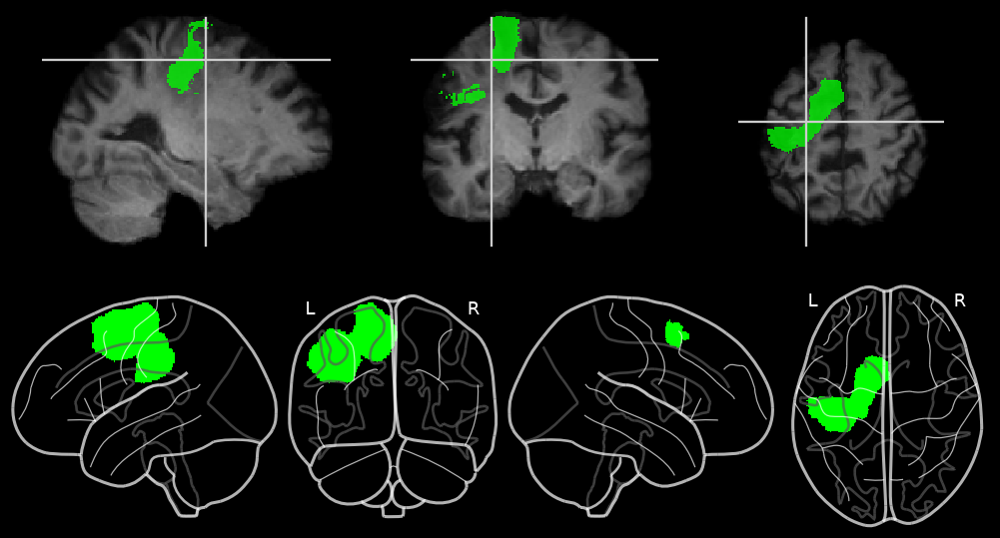

Saved participant report: /home/jovyan/neurodesktop-storage/calmar/reports/unattended-demo/interpretation_sub-M2004_ses-524_synthstroke.html


In [52]:
# Generate the interpretation report for the participant and mask chosen in the form.
from calmar.participant_report import ReportSettings, generate_participant_report, selected_entry

REPORT_SETTINGS = ReportSettings(
    kb_atlases=tuple(INTERP_KB_ATLASES), display_atlas=INTERP_DISPLAY_ATLAS,
    high_conf_only=INTERP_HIGH_CONF_ONLY, evidence=INTERP_EVIDENCE,
    min_overlap_pct=INTERP_MIN_OVERLAP_PCT, min_region_pct=INTERP_MIN_REGION_PCT,
    disconnectome=INTERP_DISCONNECTOME, min_disconnected_pct=INTERP_MIN_DISCONNECTED_PCT, top_n=INTERP_TOP_N,
    max_rois=INTERP_MAX_ROIS, max_evidence_regions=INTERP_MAX_EVIDENCE_REGIONS,
    min_summary_citations=INTERP_MIN_SUMMARY_CITATIONS,
    min_summary_anatomies=INTERP_MIN_SUMMARY_ANATOMIES,
    threshold=CONFIG["LESION_THRESHOLD"])     # mask threshold used for Dice between masks

# namespace=globals() is needed only by the Slurm helpers that prepare overlap tables/overlay.
PARTICIPANT_REPORT = generate_participant_report(
    selected_entry(SUBJECTS, INTERP_SUBJECT_IDX), INTERP_MASK_SOURCE, REPORT_SETTINGS,
    study=study, namespace=globals(), reports_dir=REPORTS_DIR, dataset_dir=RAW_DATASET_DIR,
    atlas_dir=ATLAS_DIR, kb_root=APHASIA_KB_ROOT, kb_reason=APHASIA_KB_REASON,
    helpers=cw, run_decoding=INTERP_RUN_DECODING)
display(PARTICIPANT_REPORT.panel.widget)

# Short names used by the decoding and outputs cells.
_participant_report_panel, _rpt_path = PARTICIPANT_REPORT.panel, PARTICIPANT_REPORT.path
_calmar_generated_report_selection = PARTICIPANT_REPORT.selection
if globals().get("_report_inputs"):
    _report_inputs.message.value = ("Participant report ready. Optional Neurosynth decoding is running…"
                                    if INTERP_RUN_DECODING else "Participant report ready below.")
DEMO_REPORTS = globals().setdefault('DEMO_REPORTS', [])
DEMO_REPORTS.append(str(PARTICIPANT_REPORT.path))
display(HTML(PARTICIPANT_REPORT.path.read_text()))
print('Saved participant report:', PARTICIPANT_REPORT.path)


### Demo report: sub-strokecase0001

In [53]:
INTERP_SUBJECT_IDX = 2
# Choose participant, mask, display atlas and decoding, then click Generate participant report.
# The form writes INTERP_SUBJECT_IDX / INTERP_MASK_SOURCE / INTERP_DISPLAY_ATLAS /
# INTERP_RUN_DECODING into the notebook namespace (show_report_inputs needs globals() for that).
from calmar.report_ui import show_report_inputs

_report_inputs = show_report_inputs(globals())
_rp_subj, _rp_mask = _report_inputs.subject, _report_inputs.source
_report_inputs.choose_participant(SUBJECTS[INTERP_SUBJECT_IDX]["subject"])
_report_inputs.choose_mask("openads" if config_for_entry(CONFIG, SUBJECTS[INTERP_SUBJECT_IDX])["MODALITY"] == "dwi" else "synthstroke")
assert _report_inputs.approve(), _report_inputs.message.value
print("Demo: report form approved using its displayed defaults.")

**If the buttons do not respond (‘Loading widget…’ or ‘Waiting…’):** insert a temporary code cell and run this command by itself:

```python
%calmar_continue generate
```

This does what **Generate participant report** does, with the form's current choices. To choose without the form, add the participant and the mask, e.g. `%calmar_continue generate sub-01 manual`. Then run the report cell below (Shift+Enter).

Demo: report form approved using its displayed defaults.


reporting · sub-strokecase0001 ses-0001 · Slurm job 62 · submitted 0:00:00

reporting · sub-strokecase0001 ses-0001 · Slurm job 62 · queued 0:00:00   

reporting · sub-strokecase0001 ses-0001 · done in 0:00:10 (Slurm job 62)

reporting · reporting · Slurm job 63 · submitted 0:00:00

reporting · reporting · Slurm job 63 · queued 0:00:00   

reporting · reporting · done in 0:00:10 (Slurm job 63)


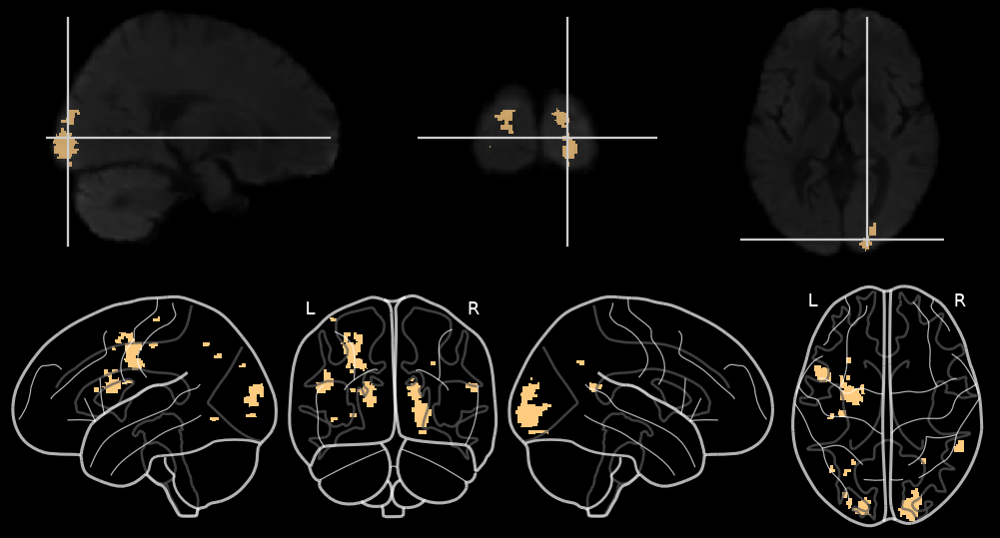

Saved participant report: /home/jovyan/neurodesktop-storage/calmar/reports/unattended-demo/interpretation_sub-strokecase0001_ses-0001_openads.html


In [54]:
# Generate the interpretation report for the participant and mask chosen in the form.
from calmar.participant_report import ReportSettings, generate_participant_report, selected_entry

REPORT_SETTINGS = ReportSettings(
    kb_atlases=tuple(INTERP_KB_ATLASES), display_atlas=INTERP_DISPLAY_ATLAS,
    high_conf_only=INTERP_HIGH_CONF_ONLY, evidence=INTERP_EVIDENCE,
    min_overlap_pct=INTERP_MIN_OVERLAP_PCT, min_region_pct=INTERP_MIN_REGION_PCT,
    disconnectome=INTERP_DISCONNECTOME, min_disconnected_pct=INTERP_MIN_DISCONNECTED_PCT, top_n=INTERP_TOP_N,
    max_rois=INTERP_MAX_ROIS, max_evidence_regions=INTERP_MAX_EVIDENCE_REGIONS,
    min_summary_citations=INTERP_MIN_SUMMARY_CITATIONS,
    min_summary_anatomies=INTERP_MIN_SUMMARY_ANATOMIES,
    threshold=CONFIG["LESION_THRESHOLD"])     # mask threshold used for Dice between masks

# namespace=globals() is needed only by the Slurm helpers that prepare overlap tables/overlay.
PARTICIPANT_REPORT = generate_participant_report(
    selected_entry(SUBJECTS, INTERP_SUBJECT_IDX), INTERP_MASK_SOURCE, REPORT_SETTINGS,
    study=study, namespace=globals(), reports_dir=REPORTS_DIR, dataset_dir=RAW_DATASET_DIR,
    atlas_dir=ATLAS_DIR, kb_root=APHASIA_KB_ROOT, kb_reason=APHASIA_KB_REASON,
    helpers=cw, run_decoding=INTERP_RUN_DECODING)
display(PARTICIPANT_REPORT.panel.widget)

# Short names used by the decoding and outputs cells.
_participant_report_panel, _rpt_path = PARTICIPANT_REPORT.panel, PARTICIPANT_REPORT.path
_calmar_generated_report_selection = PARTICIPANT_REPORT.selection
if globals().get("_report_inputs"):
    _report_inputs.message.value = ("Participant report ready. Optional Neurosynth decoding is running…"
                                    if INTERP_RUN_DECODING else "Participant report ready below.")
DEMO_REPORTS = globals().setdefault('DEMO_REPORTS', [])
DEMO_REPORTS.append(str(PARTICIPANT_REPORT.path))
display(HTML(PARTICIPANT_REPORT.path.read_text()))
print('Saved participant report:', PARTICIPANT_REPORT.path)


### Demo report: sub-strokecase0002

In [55]:
INTERP_SUBJECT_IDX = 3
# Choose participant, mask, display atlas and decoding, then click Generate participant report.
# The form writes INTERP_SUBJECT_IDX / INTERP_MASK_SOURCE / INTERP_DISPLAY_ATLAS /
# INTERP_RUN_DECODING into the notebook namespace (show_report_inputs needs globals() for that).
from calmar.report_ui import show_report_inputs

_report_inputs = show_report_inputs(globals())
_rp_subj, _rp_mask = _report_inputs.subject, _report_inputs.source
_report_inputs.choose_participant(SUBJECTS[INTERP_SUBJECT_IDX]["subject"])
_report_inputs.choose_mask("openads" if config_for_entry(CONFIG, SUBJECTS[INTERP_SUBJECT_IDX])["MODALITY"] == "dwi" else "synthstroke")
assert _report_inputs.approve(), _report_inputs.message.value
print("Demo: report form approved using its displayed defaults.")

**If the buttons do not respond (‘Loading widget…’ or ‘Waiting…’):** insert a temporary code cell and run this command by itself:

```python
%calmar_continue generate
```

This does what **Generate participant report** does, with the form's current choices. To choose without the form, add the participant and the mask, e.g. `%calmar_continue generate sub-01 manual`. Then run the report cell below (Shift+Enter).

Demo: report form approved using its displayed defaults.


reporting · sub-strokecase0002 ses-0001 · Slurm job 64 · submitted 0:00:00

reporting · sub-strokecase0002 ses-0001 · Slurm job 64 · queued 0:00:00   

reporting · sub-strokecase0002 ses-0001 · done in 0:00:10 (Slurm job 64)

reporting · reporting · Slurm job 65 · submitted 0:00:00

reporting · reporting · Slurm job 65 · queued 0:00:00   

reporting · reporting · done in 0:00:10 (Slurm job 65)


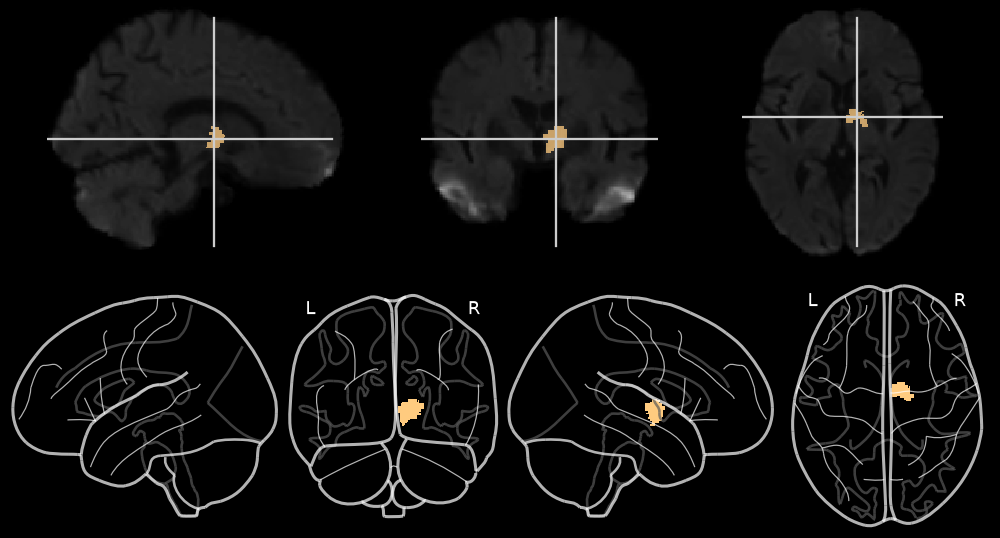

Saved participant report: /home/jovyan/neurodesktop-storage/calmar/reports/unattended-demo/interpretation_sub-strokecase0002_ses-0001_openads.html


In [56]:
# Generate the interpretation report for the participant and mask chosen in the form.
from calmar.participant_report import ReportSettings, generate_participant_report, selected_entry

REPORT_SETTINGS = ReportSettings(
    kb_atlases=tuple(INTERP_KB_ATLASES), display_atlas=INTERP_DISPLAY_ATLAS,
    high_conf_only=INTERP_HIGH_CONF_ONLY, evidence=INTERP_EVIDENCE,
    min_overlap_pct=INTERP_MIN_OVERLAP_PCT, min_region_pct=INTERP_MIN_REGION_PCT,
    disconnectome=INTERP_DISCONNECTOME, min_disconnected_pct=INTERP_MIN_DISCONNECTED_PCT, top_n=INTERP_TOP_N,
    max_rois=INTERP_MAX_ROIS, max_evidence_regions=INTERP_MAX_EVIDENCE_REGIONS,
    min_summary_citations=INTERP_MIN_SUMMARY_CITATIONS,
    min_summary_anatomies=INTERP_MIN_SUMMARY_ANATOMIES,
    threshold=CONFIG["LESION_THRESHOLD"])     # mask threshold used for Dice between masks

# namespace=globals() is needed only by the Slurm helpers that prepare overlap tables/overlay.
PARTICIPANT_REPORT = generate_participant_report(
    selected_entry(SUBJECTS, INTERP_SUBJECT_IDX), INTERP_MASK_SOURCE, REPORT_SETTINGS,
    study=study, namespace=globals(), reports_dir=REPORTS_DIR, dataset_dir=RAW_DATASET_DIR,
    atlas_dir=ATLAS_DIR, kb_root=APHASIA_KB_ROOT, kb_reason=APHASIA_KB_REASON,
    helpers=cw, run_decoding=INTERP_RUN_DECODING)
display(PARTICIPANT_REPORT.panel.widget)

# Short names used by the decoding and outputs cells.
_participant_report_panel, _rpt_path = PARTICIPANT_REPORT.panel, PARTICIPANT_REPORT.path
_calmar_generated_report_selection = PARTICIPANT_REPORT.selection
if globals().get("_report_inputs"):
    _report_inputs.message.value = ("Participant report ready. Optional Neurosynth decoding is running…"
                                    if INTERP_RUN_DECODING else "Participant report ready below.")
DEMO_REPORTS = globals().setdefault('DEMO_REPORTS', [])
DEMO_REPORTS.append(str(PARTICIPANT_REPORT.path))
display(HTML(PARTICIPANT_REPORT.path.read_text()))
print('Saved participant report:', PARTICIPANT_REPORT.path)


In [57]:
# Inventory of available outputs (presence only; does not imply QC was completed).
from calmar.participant_report import outputs_inventory_html

_latest_report = globals().get("PARTICIPANT_REPORT")   # None until a report is generated
display(HTML(outputs_inventory_html(SUBJECTS, study.masks, REPORTS_DIR,
                                    _latest_report.path if _latest_report else None)))
if callable(globals().get("show_timings")):
    show_timings()

MNI mask source,Available in cohort
LINDA,2 / 4
SynthStroke,2 / 4
OpenADS,2 / 4
Manual,4 / 4


Step,Time
Configuration (cell 12),1.2 s
Manual mask registration — single subject (cell 38),0.5 s
BCBToolkit disconnectome — single subject (cell 42),0.5 s
DeepDisco disconnectome — single subject (cell 44),0.5 s
Warp manual masks to MNI (cell 59),0.5 s
Manual mask editing (cell 66),1.3 s
calmar-direct-dmri,3 h 5 min
calmar-brain-health,15 min 28 s
BCBToolkit disconnectomes — batch (cell 83),6 min 19 s
DeepDisco disconnectomes — batch (cell 85),3 min 5 s


In [58]:

_demo_errors = {k: globals()[k] for k in ('DWI_ERROR', 'DMRI_ERROR', 'BRAIN_HEALTH_ERROR') if globals().get(k)}
print('Optional analysis errors (must be resolved before declaring success):', _demo_errors)
assert not _demo_errors, _demo_errors
assert len(DEMO_REPORTS) == 4 and all(Path(p).is_file() for p in DEMO_REPORTS)
assert len(set(DEMO_REPORTS)) == 4
_demo_proof = {'token': DEMO_COMPLETION_TOKEN, 'reports': DEMO_REPORTS,
               'atlas_pdfs': DEMO_ATLAS_PDFS, 'participants': [e['subject'] for e in SUBJECTS],
               'human_qc': 'skipped'}
_demo_proof_path = Path(DEMO_COMPLETION_PROOF)
_demo_proof_temporary = _demo_proof_path.with_suffix('.tmp')
_demo_proof_temporary.write_text(json.dumps(_demo_proof, indent=2))
_demo_proof_temporary.replace(_demo_proof_path)
print('Four reports and all selected processing cells completed. Human QC remains skipped.')


Optional analysis errors (must be resolved before declaring success): {}
Four reports and all selected processing cells completed. Human QC remains skipped.


## Saved demo downloads

Human QC was skipped for this demonstration. This page preserves static figures and reports. Live MRI viewers and computation require opening the notebook in Neurodesk; raw MRI volumes are not hosted here.

- [interpretation_sub-M2001_ses-1076_synthstroke.html](assets/fa48b08559463ea1-interpretation_sub-M2001_ses-1076_synthstroke.html)
- [interpretation_sub-M2004_ses-524_synthstroke.html](assets/7ed408f5dcec0455-interpretation_sub-M2004_ses-524_synthstroke.html)
- [interpretation_sub-strokecase0001_ses-0001_openads.html](assets/ced8a935707d2f8e-interpretation_sub-strokecase0001_ses-0001_openads.html)
- [interpretation_sub-strokecase0002_ses-0001_openads.html](assets/0f2c8785f12bf62a-interpretation_sub-strokecase0002_ses-0001_openads.html)
- [sub-M2001_ses-1076_HarvardOxford_linda.pdf](assets/6815a2bdd393860f-sub-M2001_ses-1076_HarvardOxford_linda.pdf)
- [sub-M2004_ses-524_HarvardOxford_linda.pdf](assets/6efa119e2a4ff5c5-sub-M2004_ses-524_HarvardOxford_linda.pdf)
- [sub-M2001_ses-1076_HarvardOxford_manual.pdf](assets/352cfa64ece7306e-sub-M2001_ses-1076_HarvardOxford_manual.pdf)
- [sub-M2004_ses-524_HarvardOxford_manual.pdf](assets/817603b3f199e0f6-sub-M2004_ses-524_HarvardOxford_manual.pdf)
- [sub-strokecase0001_ses-0001_HarvardOxford_manual.pdf](assets/7b20651c89d7d039-sub-strokecase0001_ses-0001_HarvardOxford_manual.pdf)
- [sub-strokecase0001_ses-0001_HarvardOxford_openads.pdf](assets/ca9ec5ab8c4a7eda-sub-strokecase0001_ses-0001_HarvardOxford_openads.pdf)
- [sub-M2001_ses-1076_HarvardOxford_synthstroke.pdf](assets/e03de5acaa62b9d6-sub-M2001_ses-1076_HarvardOxford_synthstroke.pdf)
- [sub-M2004_ses-524_HarvardOxford_synthstroke.pdf](assets/6f2149b691b1ef72-sub-M2004_ses-524_HarvardOxford_synthstroke.pdf)
- [sub-M2001_ses-1076_AAL_linda.pdf](assets/6beb3f32bc0bfe5a-sub-M2001_ses-1076_AAL_linda.pdf)
- [sub-M2004_ses-524_AAL_linda.pdf](assets/1726abe2b4b93269-sub-M2004_ses-524_AAL_linda.pdf)
- [sub-M2001_ses-1076_AAL_manual.pdf](assets/3e56a375bd8601a7-sub-M2001_ses-1076_AAL_manual.pdf)
- [sub-M2004_ses-524_AAL_manual.pdf](assets/29e911d06a3df5a2-sub-M2004_ses-524_AAL_manual.pdf)
- [sub-strokecase0001_ses-0001_AAL_manual.pdf](assets/7a5dceac3f9394a1-sub-strokecase0001_ses-0001_AAL_manual.pdf)
- [sub-strokecase0002_ses-0001_AAL_manual.pdf](assets/0215c16ebcdf68eb-sub-strokecase0002_ses-0001_AAL_manual.pdf)
- [sub-strokecase0001_ses-0001_AAL_openads.pdf](assets/ea1a98b2605bfc43-sub-strokecase0001_ses-0001_AAL_openads.pdf)
- [sub-strokecase0002_ses-0001_AAL_openads.pdf](assets/e4bbbbae993a7064-sub-strokecase0002_ses-0001_AAL_openads.pdf)
- [sub-M2001_ses-1076_AAL_synthstroke.pdf](assets/115cb21a68a84c89-sub-M2001_ses-1076_AAL_synthstroke.pdf)
- [sub-M2004_ses-524_AAL_synthstroke.pdf](assets/23071633a464b788-sub-M2004_ses-524_AAL_synthstroke.pdf)
- [sub-M2001_ses-1076_Destrieux_linda.pdf](assets/d60a52c94a5ba227-sub-M2001_ses-1076_Destrieux_linda.pdf)
- [sub-M2004_ses-524_Destrieux_linda.pdf](assets/5e710a54ef25f9eb-sub-M2004_ses-524_Destrieux_linda.pdf)
- [sub-M2001_ses-1076_Destrieux_manual.pdf](assets/a922c0c6e6b320ca-sub-M2001_ses-1076_Destrieux_manual.pdf)
- [sub-M2004_ses-524_Destrieux_manual.pdf](assets/4a9d42888b0129b9-sub-M2004_ses-524_Destrieux_manual.pdf)
- [sub-strokecase0001_ses-0001_Destrieux_manual.pdf](assets/b15fef5b716dd058-sub-strokecase0001_ses-0001_Destrieux_manual.pdf)
- [sub-strokecase0001_ses-0001_Destrieux_openads.pdf](assets/7e6b4dc8c744b267-sub-strokecase0001_ses-0001_Destrieux_openads.pdf)
- [sub-M2001_ses-1076_Destrieux_synthstroke.pdf](assets/86f834afcf9bf312-sub-M2001_ses-1076_Destrieux_synthstroke.pdf)
- [sub-M2004_ses-524_Destrieux_synthstroke.pdf](assets/a2b0b51332fffb11-sub-M2004_ses-524_Destrieux_synthstroke.pdf)
- [sub-M2001_ses-1076_Schaefer400_linda.pdf](assets/a176dcef8730fcd2-sub-M2001_ses-1076_Schaefer400_linda.pdf)
- [sub-M2004_ses-524_Schaefer400_linda.pdf](assets/4cece7173e5a81ae-sub-M2004_ses-524_Schaefer400_linda.pdf)
- [sub-M2001_ses-1076_Schaefer400_manual.pdf](assets/8b6a6844beb26921-sub-M2001_ses-1076_Schaefer400_manual.pdf)
- [sub-M2004_ses-524_Schaefer400_manual.pdf](assets/5742c78e13e3010d-sub-M2004_ses-524_Schaefer400_manual.pdf)
- [sub-strokecase0001_ses-0001_Schaefer400_manual.pdf](assets/cb811f3168e4abe7-sub-strokecase0001_ses-0001_Schaefer400_manual.pdf)
- [sub-strokecase0001_ses-0001_Schaefer400_openads.pdf](assets/c7cdfdac2f10a4bc-sub-strokecase0001_ses-0001_Schaefer400_openads.pdf)
- [sub-M2001_ses-1076_Schaefer400_synthstroke.pdf](assets/09ba6808b2a57ee8-sub-M2001_ses-1076_Schaefer400_synthstroke.pdf)
- [sub-M2004_ses-524_Schaefer400_synthstroke.pdf](assets/f7fe9444c5304af7-sub-M2004_ses-524_Schaefer400_synthstroke.pdf)
- [sub-M2001_ses-1076_JHU_linda.pdf](assets/1f93d277ad7518d6-sub-M2001_ses-1076_JHU_linda.pdf)
- [sub-M2004_ses-524_JHU_linda.pdf](assets/0b506b2cdb78553f-sub-M2004_ses-524_JHU_linda.pdf)
- [sub-M2001_ses-1076_JHU_manual.pdf](assets/13c78f17d8dedd29-sub-M2001_ses-1076_JHU_manual.pdf)
- [sub-M2004_ses-524_JHU_manual.pdf](assets/612cb10caf8f3e3b-sub-M2004_ses-524_JHU_manual.pdf)
- [sub-strokecase0002_ses-0001_JHU_manual.pdf](assets/372146ae96488b87-sub-strokecase0002_ses-0001_JHU_manual.pdf)
- [sub-strokecase0002_ses-0001_JHU_openads.pdf](assets/a44d436d4bdb1845-sub-strokecase0002_ses-0001_JHU_openads.pdf)
- [sub-M2001_ses-1076_JHU_synthstroke.pdf](assets/b24e36e18388aede-sub-M2001_ses-1076_JHU_synthstroke.pdf)
- [sub-M2004_ses-524_JHU_synthstroke.pdf](assets/32e103f4e2269070-sub-M2004_ses-524_JHU_synthstroke.pdf)
- [sub-M2001_ses-1076_XTRACT_linda.pdf](assets/3c576350628e0c35-sub-M2001_ses-1076_XTRACT_linda.pdf)
- [sub-M2004_ses-524_XTRACT_linda.pdf](assets/4bd6cb1432bae226-sub-M2004_ses-524_XTRACT_linda.pdf)
- [sub-M2001_ses-1076_XTRACT_manual.pdf](assets/6e0b1abad0ab0f16-sub-M2001_ses-1076_XTRACT_manual.pdf)
- [sub-M2004_ses-524_XTRACT_manual.pdf](assets/5a44f7b2aa2d0be2-sub-M2004_ses-524_XTRACT_manual.pdf)
- [sub-strokecase0001_ses-0001_XTRACT_manual.pdf](assets/139a5bdb5ac49889-sub-strokecase0001_ses-0001_XTRACT_manual.pdf)
- [sub-strokecase0002_ses-0001_XTRACT_manual.pdf](assets/71f1ad2d7c5bdbf7-sub-strokecase0002_ses-0001_XTRACT_manual.pdf)
- [sub-strokecase0001_ses-0001_XTRACT_openads.pdf](assets/71e0f911dae53370-sub-strokecase0001_ses-0001_XTRACT_openads.pdf)
- [sub-strokecase0002_ses-0001_XTRACT_openads.pdf](assets/c176afccf25b8c80-sub-strokecase0002_ses-0001_XTRACT_openads.pdf)
- [sub-M2001_ses-1076_XTRACT_synthstroke.pdf](assets/c3b1de65aca388a3-sub-M2001_ses-1076_XTRACT_synthstroke.pdf)
- [sub-M2004_ses-524_XTRACT_synthstroke.pdf](assets/c836fffe933defd5-sub-M2004_ses-524_XTRACT_synthstroke.pdf)
